<a href="https://colab.research.google.com/github/macontreras04/cpf/blob/main/PFE_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PFE

Este scrip corre varias cosas

In [ ]:
from scipy.stats import norm
import numpy as np

def pfe_analytic(S0, K, r, q, sigma, T, t, mu=None, confidence=0.99):
    mu = r - q if mu is None else mu
    z = norm.ppf(confidence)

    fwd_value = S0*np.exp(mu*t)*np.exp(-q*(T-t)) - K*np.exp(-r*(T-t))
    std_dollars = S0*np.exp(mu*t)*sigma*np.sqrt(t)*np.exp(-q*(T-t))

    return fwd_value + z*std_dollars

t = np.array([7,14,21,28,60,90,180,365]) / 365
pfe_approx = pfe_analytic(S0=5000, K=5000, r=0.045, q=0.013, sigma=0.18, T=1.0, t=t)
print(pfe_approx)

[ 442.01740063  561.15292271  652.8391538   730.35581188 1000.72466902
 1194.85136197 1642.80166474 2324.38293956]


In [ ]:
def pfe_lognormal_exact(S0, K, r, q, sigma, T, t, mu=None, confidence=0.99):
    mu = r - q if mu is None else mu
    z = norm.ppf(confidence)
    S_q99 = S0*np.exp((mu - 0.5*sigma**2)*t + sigma*np.sqrt(t)*z)   # percentil 99 exacto de S(t)
    return np.maximum(S_q99*np.exp(-q*(T-t)) - K*np.exp(-r*(T-t)), 0)

t = np.array([7,14,21,28,60,90,180,365]) / 365
pfe_exact = pfe_lognormal_exact(S0=5000, K=5000, r=0.045, q=0.013, sigma=0.18, T=1.0, t=t)
print(pfe_exact)

[ 448.85979331  574.90878521  673.55899412  758.08284062 1060.94531692
 1286.12519079 1830.15156664 2721.28290598]


[160.61256651 172.20397354 182.97469515 193.0503716  233.30949104
 264.08843877 337.15288354 451.24390522]
[ 448.22165081  573.16365901  671.71227205  754.75193087 1060.20605561
 1286.85851424 1823.62753886 2726.64110373]


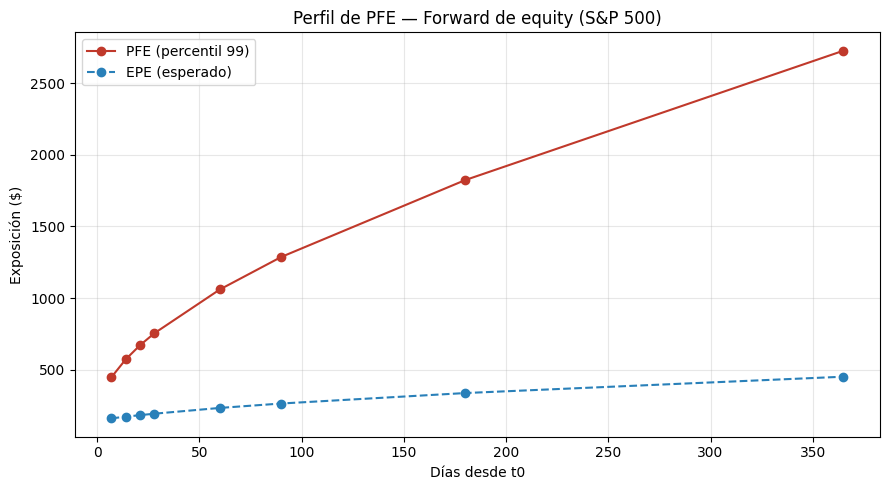

In [ ]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

def pfe_forward(S0, K, r, q, sigma, T, time_grid, n_paths=100_000, pct=99, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r - q if mu is None else mu          # drift real-world vs risk-neutral

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))   # pasos entre nodos consecutivos

    S = np.full(n_paths, S0, dtype=float)     # <- fix: forzar float
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = S*np.exp(-q*(T - time_grid[i])) - K*np.exp(-r*(T - time_grid[i]))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


def plot_pfe(time_grid, pfe, epe, pct=99):
    days = time_grid * 365

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(days, pfe, marker='o', color='#c0392b', label=f'PFE (percentil {pct})')
    ax.plot(days, epe, marker='o', color='#2980b9', linestyle='--', label='EPE (esperado)')

    ax.set_xlabel('Días desde t0')
    ax.set_ylabel('Exposición ($)')
    ax.set_title('Perfil de PFE — Forward de equity (S&P 500)')
    ax.set_xscale('linear')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
t, pfe, epe = pfe_forward(S0=5000, K=5000, r=0.045, q=0.013, sigma=0.18, T=1.0, time_grid=grid)

print(epe)
print(pfe)

plot_pfe(t, pfe, epe)

## CVA calculation

Supervivencia en tenors CDS: {0.5: np.float64(0.997004495503373), 1: np.float64(0.9920319148370607), 2: np.float64(0.9788926126429459), 3: np.float64(0.9607894391523232), 5: np.float64(0.9169827055971943)}
Supervivencia en nodos del grid de exposición: [0.99992147 0.99983935 0.99975372 0.99966469 0.99921655 0.99874048
 0.99705562 0.99203191]
Probabilidad marginal de default por intervalo: [7.85341316e-05 8.21207374e-05 8.56218353e-05 8.90374167e-05
 4.48138912e-04 4.76068205e-04 1.68486015e-03 5.02370378e-03]
Contribución de CVA por intervalo: [0.00472601 0.0102315  0.01137466 0.01251185 0.0711226  0.0878184
 0.37154052 1.41989714]

CVA total ≈ 1.99 $


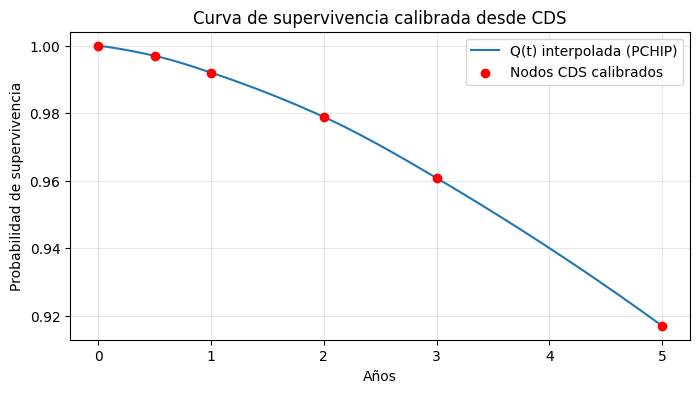

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ---------- 1. Motor Monte Carlo  ----------
def pfe_forward(S0, K, r, q, sigma, T, time_grid, n_paths=100_000, pct=99, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r - q if mu is None else mu

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = S*np.exp(-q*(T - time_grid[i])) - K*np.exp(-r*(T - time_grid[i]))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


# ---------- 2. Calibración de la curva de PD/supervivencia desde CDS ----------
def calibrate_survival_curve(cds_tenors, cds_spreads_bps, RR=0.25):
    """
    Aproximación simple: lambda_t = s_t / (1-RR)  (hazard rate promedio acumulado a t)
    Q(t) = exp(-lambda_t * t)
    Ancla Q(0)=1 para poder interpolar/extrapolar antes del primer tenor.
    """
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0   # bps -> decimal

    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)

    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))

    # PCHIP sobre ln(Q) preserva monotonicidad y evita que la interpolación
    # produzca supervivencias > 1 o con forma no decreciente
    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)

    def Q(t):
        t = np.asarray(t, float)
        return np.exp(log_Q_interp(t))

    return Q, tenors_anchored, Q_anchored


# ---------- 3. CVA a partir del perfil de EE ----------
def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    """
    CVA ≈ (1-RR) * sum_i  EE_promedio(i) * [Q(t_{i-1}) - Q(t_i)] * DF(t_i)
    - EE_promedio: promedio del EE en los extremos del intervalo (regla trapezoidal simple)
    - DF: descuento con la tasa libre de riesgo (flat aquí; podrías pasar una curva)
    """
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)                       # probabilidad marginal de default en cada intervalo
    DF = np.exp(-r * time_grid)                   # descuento al final de cada intervalo

    epe_ext = np.concatenate(([0.0], epe))         # EE en t=0 es 0 (aún no hay exposición)
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])   # EE promedio del intervalo

    cva_contributions = (1 - RR) * epe_avg * dPD * DF
    cva_total = cva_contributions.sum()

    return cva_total, dPD, cva_contributions


# ================= Uso =================

# --- Monte Carlo del forward ---
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
t, pfe, epe = pfe_forward(S0=5000, K=5000, r=0.045, q=0.013, sigma=0.18, T=1.0, time_grid=grid)

# --- Curva CDS ilustrativa (reemplaza con datos reales de mercado) ---
cds_tenors  = [0.5, 1, 2, 3, 5]          # años
cds_spreads = [45, 60, 80, 100, 130]      # en basis points
RR = 0.25

Q, tenors_anchored, Q_anchored = calibrate_survival_curve(cds_tenors, cds_spreads, RR=RR)

# --- CVA ---
r_flat = 0.045
cva, dPD, contrib = compute_cva(t, epe, Q, r=r_flat, RR=RR)

print("Supervivencia en tenors CDS:", dict(zip(cds_tenors, Q(cds_tenors))))
print("Supervivencia en nodos del grid de exposición:", Q(t))
print("Probabilidad marginal de default por intervalo:", dPD)
print("Contribución de CVA por intervalo:", contrib)
print(f"\nCVA total ≈ {cva:,.2f} $")

# --- Plot de curva de supervivencia ---
t_fine = np.linspace(0, 5, 200)
plt.figure(figsize=(8,4))
plt.plot(t_fine, Q(t_fine), label='Q(t) interpolada (PCHIP)')
plt.scatter(tenors_anchored, Q_anchored, color='red', zorder=5, label='Nodos CDS calibrados')
plt.xlabel('Años'); plt.ylabel('Probabilidad de supervivencia')
plt.title('Curva de supervivencia calibrada desde CDS')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

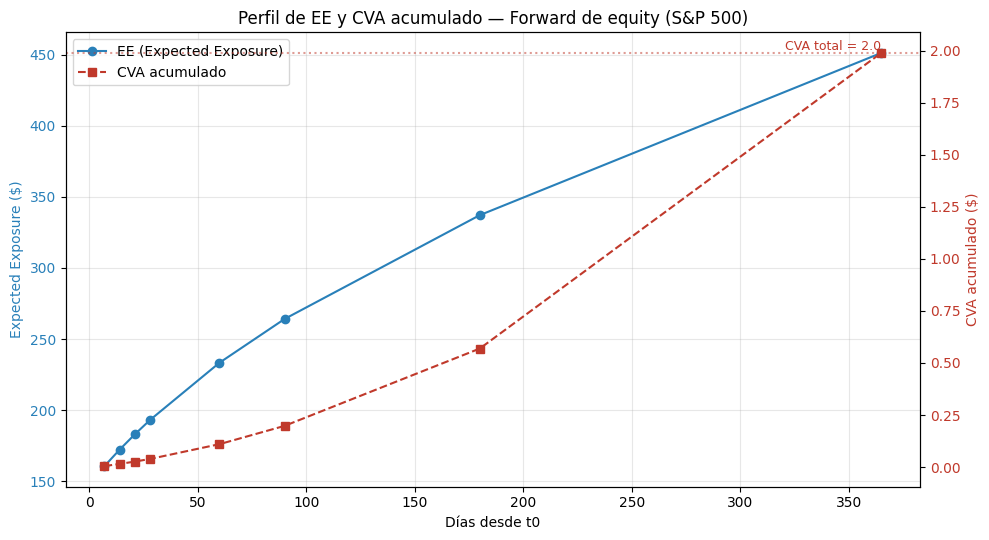

In [ ]:
def plot_ee_and_cva(time_grid, epe, contrib, cva_total):
    days = time_grid * 365
    cva_cumulative = np.cumsum(contrib)

    fig, ax1 = plt.subplots(figsize=(10, 5.5))

    # --- Eje izquierdo: EE ---
    color_ee = '#2980b9'
    ax1.plot(days, epe, marker='o', color=color_ee, label='EE (Expected Exposure)')
    ax1.set_xlabel('Días desde t0')
    ax1.set_ylabel('Expected Exposure ($)', color=color_ee)
    ax1.tick_params(axis='y', labelcolor=color_ee)
    ax1.grid(True, alpha=0.3)

    # --- Eje derecho: CVA acumulado ---
    ax2 = ax1.twinx()
    color_cva = '#c0392b'
    ax2.plot(days, cva_cumulative, marker='s', linestyle='--', color=color_cva,
              label='CVA acumulado')
    ax2.set_ylabel('CVA acumulado ($)', color=color_cva)
    ax2.tick_params(axis='y', labelcolor=color_cva)

    # Línea horizontal marcando el CVA total (para verificar que el acumulado converge ahí)
    ax2.axhline(cva_total, color=color_cva, linestyle=':', alpha=0.5)
    ax2.text(days[-1], cva_total, f'  CVA total = {cva_total:,.1f}',
              va='bottom', ha='right', color=color_cva, fontsize=9)

    # --- Leyenda combinada ---
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc='upper left')

    plt.title('Perfil de EE y CVA acumulado — Forward de equity (S&P 500)')
    fig.tight_layout()
    plt.show()


# Uso, después de calcular cva, dPD, contrib con compute_cva(...):
plot_ee_and_cva(t, epe, contrib, cva)

## Monte Carlo con Sobol (QMC) + Greeks

CVA base (Sobol): 1.99
Delta CVA/dS0: 0.003703   |   Delta por 1% de S0: 0.19
CS01 0.5Y: -0.0074 $/bp
CS01 1Y: 0.0386 $/bp
CS01 2Y: 0.0000 $/bp
CS01 3Y: 0.0000 $/bp
CS01 5Y: 0.0000 $/bp
CS01 paralelo (aprox.): 0.0312 $


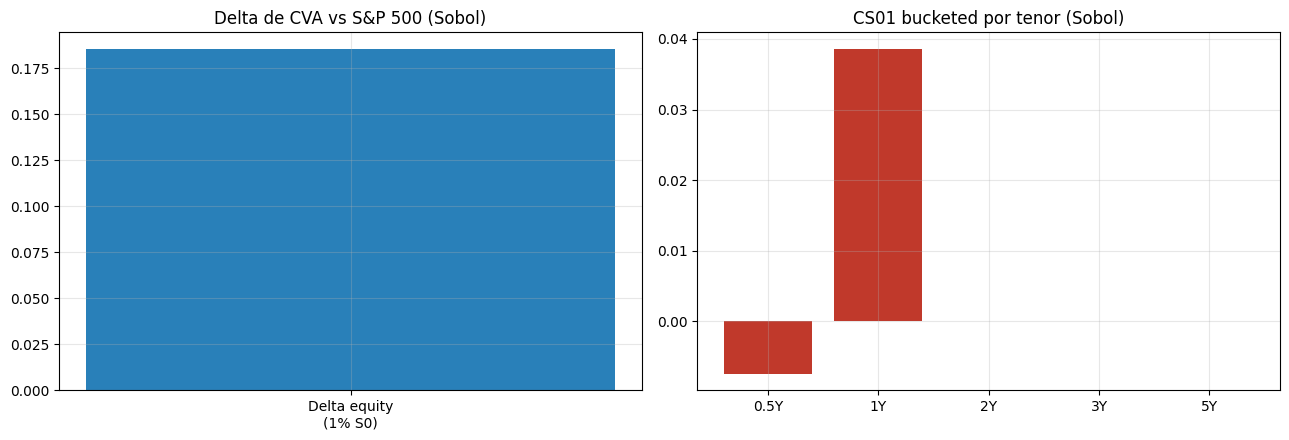

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.stats import qmc, norm

# ============================================================
# 1. Motor Monte Carlo con Sobol (quasi-Monte Carlo)
# ============================================================
def pfe_forward_sobol(S0, K, r, q, sigma, T, time_grid, n_paths=100_000, pct=99,
                       mu=None, seed=1, return_paths=False):
    mu = r - q if mu is None else mu
    time_grid = np.sort(np.asarray(time_grid, float))
    n_steps = len(time_grid)
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    # --- Sobol scrambled: una dimensión por paso temporal ---
    m = int(np.ceil(np.log2(n_paths)))
    n_eff = 2**m                                   # Sobol quiere potencias de 2
    sampler = qmc.Sobol(d=n_steps, scramble=True, seed=seed)
    U = sampler.random_base2(m=m)                  # (n_eff, n_steps) en (0,1)
    U = np.clip(U, 1e-10, 1 - 1e-10)                # evita norm.ppf(0)=-inf, ppf(1)=inf
    Z = norm.ppf(U)                                 # normales estándar vía inversa de la CDF

    S = np.full(n_eff, S0, dtype=float)
    pfe = np.empty(n_steps)
    epe = np.empty(n_steps)
    S_paths = np.empty((n_eff, n_steps)) if return_paths else None

    for i, step in enumerate(dt):
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z[:, i])
        V = S*np.exp(-q*(T - time_grid[i])) - K*np.exp(-r*(T - time_grid[i]))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()
        if return_paths:
            S_paths[:, i] = S

    if return_paths:
        return time_grid, pfe, epe, S_paths
    return time_grid, pfe, epe


# ============================================================
# 2. Curva de supervivencia desde CDS (igual que antes)
# ============================================================
def calibrate_survival_curve(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)
    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))
    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)
    return lambda t: np.exp(log_Q_interp(np.asarray(t, float)))


def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)
    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])
    contrib = (1 - RR) * epe_avg * dPD * DF
    return contrib.sum(), contrib


def full_cva_pipeline_sobol(S0, K, r, q, sigma, T, time_grid, cds_tenors, cds_spreads,
                             RR=0.25, n_paths=100_000, seed=1):
    t, pfe, epe = pfe_forward_sobol(S0, K, r, q, sigma, T, time_grid, n_paths=n_paths, seed=seed)
    Q = calibrate_survival_curve(cds_tenors, cds_spreads, RR=RR)
    cva, contrib = compute_cva(t, epe, Q, r=r, RR=RR)
    return cva, contrib, epe, pfe, t


# ============================================================
# 3. Setup base
# ============================================================
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
S0, K, r, q, sigma, T = 5000.0, 5000.0, 0.045, 0.013, 0.18, 1.0
cds_tenors  = [0.5, 1, 2, 3, 5]
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])
RR = 0.25
N_PATHS = 65_536     # 2**16, ya es potencia de 2 -> Sobol exacto sin desperdicio
SEED = 42            # mismo seed/scramble en todos los escenarios -> common random numbers

kwargs = dict(K=K, r=r, q=q, sigma=sigma, T=T, time_grid=grid,
              cds_tenors=cds_tenors, RR=RR, n_paths=N_PATHS, seed=SEED)

cva_base, contrib_base, epe_base, pfe_base, t = full_cva_pipeline_sobol(S0=S0, cds_spreads=cds_spreads, **kwargs)
print(f"CVA base (Sobol): {cva_base:,.2f}")


# ============================================================
# 4. Delta de equity (bump-and-reprice con common random numbers)
# ============================================================
def cva_equity_delta_sobol(S0, dS_pct=0.01, **kwargs):
    dS = S0 * dS_pct
    cva_up,   *_ = full_cva_pipeline_sobol(S0=S0+dS, cds_spreads=cds_spreads, **kwargs)
    cva_down, *_ = full_cva_pipeline_sobol(S0=S0-dS, cds_spreads=cds_spreads, **kwargs)
    delta = (cva_up - cva_down) / (2*dS)
    return delta, cva_up, cva_down

delta_cva, cva_up, cva_down = cva_equity_delta_sobol(S0, dS_pct=0.01, **kwargs)
print(f"Delta CVA/dS0: {delta_cva:.6f}   |   Delta por 1% de S0: {delta_cva*S0*0.01:,.2f}")


# ============================================================
# 5. CS01 bucketed (no requiere resimular el spot, solo la curva de crédito)
# ============================================================
def cs01_bucketed_sobol(epe, t, cds_spreads, r, RR=0.25, bump_bps=1.0):
    n = len(cds_spreads)
    cs01 = np.empty(n)
    for k in range(n):
        bumped = cds_spreads.copy()
        bumped[k] += bump_bps
        Q_bumped = calibrate_survival_curve(cds_tenors, bumped, RR=RR)
        cva_bumped, _ = compute_cva(t, epe, Q_bumped, r=r, RR=RR)
        cs01[k] = cva_bumped - cva_base
    return cs01

cs01 = cs01_bucketed_sobol(epe_base, t, cds_spreads, r=r, RR=RR, bump_bps=1.0)
for tenor, sens in zip(cds_tenors, cs01):
    print(f"CS01 {tenor}Y: {sens:,.4f} $/bp")

cs01_parallel = cs01.sum()   # aprox. paralelo = suma de bucketed (lineal en spreads pequeños)
print(f"CS01 paralelo (aprox.): {cs01_parallel:,.4f} $")


# ============================================================
# 6. Plot
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].bar(['Delta equity\n(1% S0)'], [delta_cva*S0*0.01], color='#2980b9')
axes[0].set_title('Delta de CVA vs S&P 500 (Sobol)')
axes[0].grid(alpha=0.3)

axes[1].bar([f'{tt}Y' for tt in cds_tenors], cs01, color='#c0392b')
axes[1].set_title('CS01 bucketed por tenor (Sobol)')
axes[1].grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Sobol + Control Variates

CVA base (Sobol + Control Variate): 1.99
EE sin CV:  [161.27762997 172.68257331 183.83327276 194.22917671 234.1629583
 264.82713899 337.76565483 451.43292147]
EE con CV:  [161.27820461 172.68333838 183.83413455 194.23010839 234.16403447
 264.82726081 337.76494271 451.42553667]
Betas por nodo: [0.89317968 0.81685297 0.77402271 0.74644456 0.68799933 0.66621148
 0.64348122 0.63969723]

Delta CVA/dS0 (con CV): 0.003703  |  por 1% de S0: 0.19
CS01 0.5Y: -0.0074 $/bp
CS01 1Y: 0.0386 $/bp
CS01 2Y: 0.0000 $/bp
CS01 3Y: 0.0000 $/bp
CS01 5Y: 0.0000 $/bp


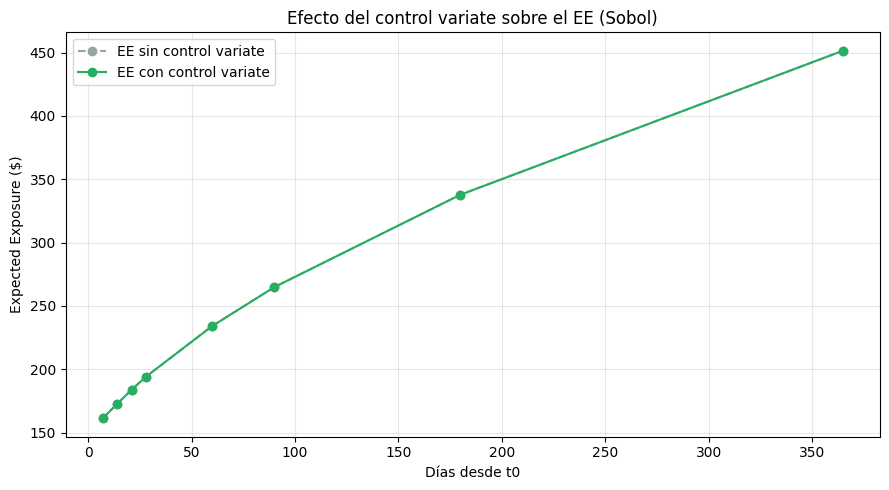

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator
from scipy.stats import qmc, norm

# ============================================================
# 1. Motor Sobol que además devuelve los paths de S (necesario para el CV)
# ============================================================
def simulate_paths_sobol(S0, sigma, time_grid, n_paths=100_000, mu=0.0, seed=1):
    time_grid = np.sort(np.asarray(time_grid, float))
    n_steps = len(time_grid)
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    m = int(np.ceil(np.log2(n_paths)))
    n_eff = 2**m
    sampler = qmc.Sobol(d=n_steps, scramble=True, seed=seed)
    U = np.clip(sampler.random_base2(m=m), 1e-10, 1 - 1e-10)
    Z = norm.ppf(U)

    S = np.full(n_eff, S0, dtype=float)
    S_paths = np.empty((n_eff, n_steps))
    for i, step in enumerate(dt):
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z[:, i])
        S_paths[:, i] = S
    return time_grid, S_paths


# ============================================================
# 2. EE/PFE con control variate (control = S(t_i), media exacta conocida)
# ============================================================
def pfe_forward_sobol_cv(S0, K, r, q, sigma, T, time_grid, n_paths=100_000, pct=99, mu=None, seed=1):
    mu = r - q if mu is None else mu
    time_grid, S_paths = simulate_paths_sobol(S0, sigma, time_grid, n_paths=n_paths, mu=mu, seed=seed)
    n_steps = len(time_grid)

    pfe = np.empty(n_steps)
    epe_raw = np.empty(n_steps)     # sin CV, para comparar
    epe_cv = np.empty(n_steps)      # con CV
    betas = np.empty(n_steps)

    for i in range(n_steps):
        S_i = S_paths[:, i]
        V = S_i*np.exp(-q*(T - time_grid[i])) - K*np.exp(-r*(T - time_grid[i]))
        exposure = np.maximum(V, 0.0)

        # --- Control variate: S(t_i), media analítica conocida ---
        control_mean_analytic = S0*np.exp(mu*time_grid[i])
        cov_matrix = np.cov(exposure, S_i)
        beta = cov_matrix[0, 1] / cov_matrix[1, 1]     # regresión: beta = Cov(X,Y)/Var(Y)

        epe_raw[i] = exposure.mean()
        epe_cv[i]  = exposure.mean() - beta*(S_i.mean() - control_mean_analytic)
        betas[i] = beta

        pfe[i] = np.percentile(exposure, pct)   # el percentil no se beneficia igual del CV; se deja igual

    return time_grid, pfe, epe_cv, epe_raw, betas


# ============================================================
# 3. Resto del pipeline (idéntico a Script 1)
# ============================================================
def calibrate_survival_curve(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)
    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))
    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)
    return lambda t: np.exp(log_Q_interp(np.asarray(t, float)))


def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)
    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])
    contrib = (1 - RR) * epe_avg * dPD * DF
    return contrib.sum(), contrib


def full_cva_pipeline_cv(S0, K, r, q, sigma, T, time_grid, cds_tenors, cds_spreads,
                          RR=0.25, n_paths=100_000, seed=1):
    t, pfe, epe_cv, epe_raw, betas = pfe_forward_sobol_cv(S0, K, r, q, sigma, T, time_grid,
                                                            n_paths=n_paths, seed=seed)
    Q = calibrate_survival_curve(cds_tenors, cds_spreads, RR=RR)
    cva, contrib = compute_cva(t, epe_cv, Q, r=r, RR=RR)
    return cva, contrib, epe_cv, epe_raw, pfe, t, betas


# ============================================================
# 4. Setup y comparación de varianza (CV vs sin CV)
# ============================================================
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
S0, K, r, q, sigma, T = 5000.0, 5000.0, 0.045, 0.013, 0.18, 1.0
cds_tenors  = [0.5, 1, 2, 3, 5]
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])
RR = 0.25
N_PATHS = 65_536
SEED = 42

kwargs = dict(K=K, r=r, q=q, sigma=sigma, T=T, time_grid=grid,
              cds_tenors=cds_tenors, RR=RR, n_paths=N_PATHS, seed=SEED)

cva_base, contrib_base, epe_cv, epe_raw, pfe_base, t, betas = full_cva_pipeline_cv(S0=S0, cds_spreads=cds_spreads, **kwargs)

print(f"CVA base (Sobol + Control Variate): {cva_base:,.2f}")
print(f"EE sin CV:  {epe_raw}")
print(f"EE con CV:  {epe_cv}")
print(f"Betas por nodo: {betas}")


# ============================================================
# 5. Greeks (mismo enfoque, ahora con CV)
# ============================================================
def cva_equity_delta_cv(S0, dS_pct=0.01, **kwargs):
    dS = S0 * dS_pct
    cva_up,   *_ = full_cva_pipeline_cv(S0=S0+dS, cds_spreads=cds_spreads, **kwargs)
    cva_down, *_ = full_cva_pipeline_cv(S0=S0-dS, cds_spreads=cds_spreads, **kwargs)
    return (cva_up - cva_down) / (2*dS), cva_up, cva_down

delta_cva, cva_up, cva_down = cva_equity_delta_cv(S0, dS_pct=0.01, **kwargs)
print(f"\nDelta CVA/dS0 (con CV): {delta_cva:.6f}  |  por 1% de S0: {delta_cva*S0*0.01:,.2f}")


def cs01_bucketed_cv(epe, t, cds_spreads, r, RR=0.25, bump_bps=1.0):
    n = len(cds_spreads)
    cs01 = np.empty(n)
    for k in range(n):
        bumped = cds_spreads.copy()
        bumped[k] += bump_bps
        Q_bumped = calibrate_survival_curve(cds_tenors, bumped, RR=RR)
        cva_bumped, _ = compute_cva(t, epe, Q_bumped, r=r, RR=RR)
        cs01[k] = cva_bumped - cva_base
    return cs01

cs01 = cs01_bucketed_cv(epe_cv, t, cds_spreads, r=r, RR=RR, bump_bps=1.0)
for tenor, sens in zip(cds_tenors, cs01):
    print(f"CS01 {tenor}Y: {sens:,.4f} $/bp")


# ============================================================
# 6. Plot: EE con y sin control variate, para ver la reducción de ruido
# ============================================================
days = t*365
plt.figure(figsize=(9,5))
plt.plot(days, epe_raw, 'o--', color='#95a5a6', label='EE sin control variate')
plt.plot(days, epe_cv,  'o-',  color='#27ae60', label='EE con control variate')
plt.xlabel('Días desde t0'); plt.ylabel('Expected Exposure ($)')
plt.title('Efecto del control variate sobre el EE (Sobol)')
plt.legend(); plt.grid(alpha=0.3)
plt.tight_layout(); plt.show()

## Metodo semi-analítico vs. Monte Carlo

In [ ]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

def pfe_forward(S0, K, r, q, sigma, T, time_grid, n_paths=100_000, pct=99, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r - q if mu is None else mu          # drift real-world vs risk-neutral

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))   # pasos entre nodos consecutivos

    S = np.full(n_paths, S0, dtype=float)     # <- fix: forzar float
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = S*np.exp(-q*(T - time_grid[i])) - K*np.exp(-r*(T - time_grid[i]))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


def plot_pfe(time_grid, epe, pct=99):
    days = time_grid * 365

    fig, ax = plt.subplots(figsize=(9, 5))
    #ax.plot(days, pfe, marker='o', color='#c0392b', label=f'PFE (percentil {pct})')
    ax.plot(days, epe, marker='o', color='#2980b9', linestyle='--', label='EPE (esperado)')

    ax.set_xlabel('Días desde t0')
    ax.set_ylabel('Exposición ($)')
    ax.set_title('Perfil de PFE — Forward de equity (S&P 500)')
    ax.set_xscale('linear')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
t, pfe, epe = pfe_forward(S0=5000, K=5000, r=0.045, q=0.013, sigma=0.18, T=1.0, time_grid=grid)

print(epe)

#plot_pfe(t, epe)

[160.61256651 172.20397354 182.97469515 193.0503716  233.30949104
 264.08843877 337.15288354 451.24390522]


In [ ]:
import numpy as np
from scipy.stats import norm

def bs_call(S0, K, r, q, sigma, t):
    """Precio Black-Scholes de call europea, y su delta."""
    if t <= 0:
        return max(S0 - K, 0.0), (1.0 if S0 > K else 0.0)
    d1 = (np.log(S0/K) + (r - q + 0.5*sigma**2)*t) / (sigma*np.sqrt(t))
    d2 = d1 - sigma*np.sqrt(t)
    price = S0*np.exp(-q*t)*norm.cdf(d1) - K*np.exp(-r*t)*norm.cdf(d2)
    delta = np.exp(-q*t)*norm.cdf(d1)
    return price, delta


def ee_semianalytic(S0, K, r, q, sigma, T, time_grid):
    """EE(t) exacto de un forward, vía réplica con call europea (Black-Scholes)."""
    time_grid = np.asarray(time_grid, float)
    ee = np.empty_like(time_grid)
    delta_ee = np.empty_like(time_grid)   # dEE(t)/dS0, útil para la delta del CVA

    for i, t in enumerate(time_grid):
        K_prime = K * np.exp(-(r - q)*(T - t))          # strike ajustado
        call_price, call_delta = bs_call(S0, K_prime, r, q, sigma, t)
        scale = np.exp(-q*(T - t) + r*t)                 # factor de conversión precio -> EE
        ee[i] = scale * call_price
        delta_ee[i] = scale * call_delta

    return time_grid, ee, delta_ee


# --- Comparación contra tu Monte Carlo ---
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
S0, K, r, q, sigma, T = 5000.0, 5000.0, 0.045, 0.013, 0.18, 1.0

t_sa, ee_sa, delta_ee_sa = ee_semianalytic(S0, K, r, q, sigma, T, grid)

print("EE semi-analítico (exacto):\n", ee_sa)
print("Delta de cada 'call' (por nodo):", delta_ee_sa)

# Compara ee_sa contra el epe que obtuviste con pfe_forward(...) del script Monte Carlo:
# deberían coincidir dentro del error de muestreo MC (usa mu = r - q en el MC para consistencia)

EE semi-analítico (exacto):
 [161.27774148 172.68323716 183.83377624 194.22957586 234.2137141
 264.76860947 337.72197055 451.41459318]
Delta de cada 'call' (por nodo): [0.89165824 0.81338941 0.76914485 0.74044457 0.6787815  0.65516937
 0.62989792 0.62525627]


In [ ]:
from scipy.interpolate import PchipInterpolator

def calibrate_survival_curve(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)
    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))
    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)
    return lambda t: np.exp(log_Q_interp(np.asarray(t, float)))


def cva_semianalytic(S0, K, r, q, sigma, T, time_grid, cds_tenors, cds_spreads, RR=0.25):
    t, ee, delta_ee = ee_semianalytic(S0, K, r, q, sigma, T, time_grid)
    Q = calibrate_survival_curve(cds_tenors, cds_spreads, RR=RR)

    t_ext = np.concatenate(([0.0], t))
    dPD = -np.diff(Q(t_ext))
    DF = np.exp(-r * t)

    weights = (1 - RR) * dPD * DF          # peso de cada "call" en el portafolio replicante
    cva = np.sum(weights * ee)
    delta_cva = np.sum(weights * delta_ee)  # <- delta analítica del CVA, SIN bump-and-reprice

    return cva, delta_cva, weights, ee, delta_ee


cds_tenors  = [0.5, 1, 2, 3, 5]
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])

cva, delta_cva, weights, ee, delta_ee = cva_semianalytic(
    S0, K, r, q, sigma, T, grid, cds_tenors, cds_spreads, RR=0.25
)

print(f"\nCVA (semi-analítico): {cva:,.2f}")
print(f"Delta de equity del CVA (analítica, sin bump-and-reprice): {delta_cva:.6f}")
print(f"Delta por 1% de movimiento en S0: {delta_cva*S0*0.01:,.2f}")

print("\nPortafolio replicante de coberturas (delta-unidades de call por nodo):")
for tt, w, d in zip(grid, weights, delta_ee):
    print(f"  t={tt*365:.0f}d | peso={w:.6f} | delta call={d:.4f} | contribución delta={w*d:.6f}")


CVA (semi-analítico): 2.26
Delta de equity del CVA (analítica, sin bump-and-reprice): 0.003689
Delta por 1% de movimiento en S0: 0.18

Portafolio replicante de coberturas (delta-unidades de call por nodo):
  t=7d | peso=0.000059 | delta call=0.8917 | contribución delta=0.000052
  t=14d | peso=0.000061 | delta call=0.8134 | contribución delta=0.000050
  t=21d | peso=0.000064 | delta call=0.7691 | contribución delta=0.000049
  t=28d | peso=0.000067 | delta call=0.7404 | contribución delta=0.000049
  t=60d | peso=0.000334 | delta call=0.6788 | contribución delta=0.000226
  t=90d | peso=0.000353 | delta call=0.6552 | contribución delta=0.000231
  t=180d | peso=0.001236 | delta call=0.6299 | contribución delta=0.000778
  t=365d | peso=0.003602 | delta call=0.6253 | contribución delta=0.002252


## FX Forward Case

Spot EUR/USD (t0): 1.1622
Forward rate K (1Y, ATM): 1.1845
Notional: 10,000,000 USD  ->  8,604,371 EUR

EPE (USD): [ 40249.51  57245.79  69993.07  80741.01 119027.69 146796.44 209541.3
 304757.25]
PFE (USD): [ 238849.88  338765.92  416763.06  481959.29  717678.89  888731.42
 1282256.99 1912204.74]

MPFE (máximo PFE en la vida del trade): 1,912,204.74 USD


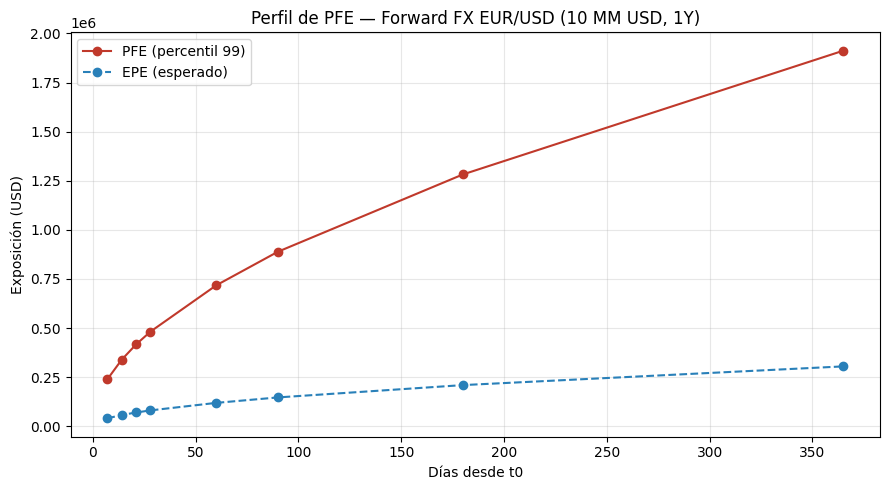

In [ ]:
import numpy as np
from scipy.stats import norm
import matplotlib.pyplot as plt

# ============================================================
# Parámetros de mercado (referencia: spot EUR/USD ~1.1622, Sep 2026)
# ============================================================
S0          = 1.1622          # spot EUR/USD (USD por 1 EUR) — última cotización disponible
r_usd       = 0.039           # tasa doméstica USD (SOFR 12M ~3.9%)
r_eur       = 0.020           # tasa extranjera EUR (€STR/ECB depo ~2.0%)
sigma_fx    = 0.075           # vol ATM 1Y EUR/USD (típica; ajustar con cotización real de mercado)
T           = 1.0             # 1 año
notional_usd = 10_000_000.0   # 10 MM USD de notional

# Forward rate ATM pactado en t0 (fair value forward, cubierto por paridad de tasas)
K = S0 * np.exp((r_usd - r_eur) * T)

# Notional convertido a unidades de EUR (porque S se cotiza en USD por EUR)
N_EUR = notional_usd / S0

print(f"Spot EUR/USD (t0): {S0:.4f}")
print(f"Forward rate K (1Y, ATM): {K:.4f}")
print(f"Notional: {notional_usd:,.0f} USD  ->  {N_EUR:,.0f} EUR")


def pfe_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                    n_paths=100_000, pct=99, mu=None, seed=1):
    """
    FX forward EUR/USD, valuado con Garman-Kohlhagen:
    V(t) = N * [S(t)*exp(-r_for*(T-t)) - K*exp(-r_dom*(T-t))]
    r_dom = tasa doméstica (USD, descuenta el strike)
    r_for = tasa extranjera (EUR, juega el rol de 'dividend yield')
    N     = notional en unidades de la divisa base (EUR)
    """
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu   # drift real-world vs risk-neutral (interest rate parity)

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


def plot_pfe_fx(time_grid, pfe, epe, pct=99):
    days = time_grid * 365

    fig, ax = plt.subplots(figsize=(9, 5))
    ax.plot(days, pfe, marker='o', color='#c0392b', label=f'PFE (percentil {pct})')
    ax.plot(days, epe, marker='o', color='#2980b9', linestyle='--', label='EPE (esperado)')

    ax.set_xlabel('Días desde t0')
    ax.set_ylabel('Exposición (USD)')
    ax.set_title('Perfil de PFE — Forward FX EUR/USD (10 MM USD, 1Y)')
    ax.set_xscale('linear')
    ax.grid(True, which='both', alpha=0.3)
    ax.legend()
    fig.tight_layout()
    plt.show()


# ============================================================
# Ejecución
# ============================================================
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365

t, pfe, epe = pfe_fx_forward(
    S0=S0, K=K, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx,
    T=T, time_grid=grid, N=N_EUR, n_paths=100_000, pct=99, seed=1
)

print("\nEPE (USD):", np.round(epe, 2))
print("PFE (USD):", np.round(pfe, 2))
print(f"\nMPFE (máximo PFE en la vida del trade): {pfe.max():,.2f} USD")

plot_pfe_fx(t, pfe, epe)

## CVA para FX forward

Spot EUR/USD: 1.1622  |  Forward K: 1.1845  |  Notional: 8,604,371 EUR

EPE (USD): [ 40249.51  57245.79  69993.07  80741.01 119027.69 146796.44 209541.3
 304757.25]
PFE (USD): [ 238849.88  338765.92  416763.06  481959.29  717678.89  888731.42
 1282256.99 1912204.74]

Supervivencia en tenors CDS: {0.5: np.float64(0.997004495503373), 1: np.float64(0.9920319148370607), 2: np.float64(0.9788926126429459), 3: np.float64(0.9607894391523232), 5: np.float64(0.9169827055971943)}
Probabilidad marginal de default por intervalo: [8.00e-05 8.00e-05 9.00e-05 9.00e-05 4.50e-04 4.80e-04 1.68e-03 5.02e-03]
Contribución de CVA por intervalo (USD): [  1.18   3.     4.08   5.02  33.36  47.   220.85 931.82]

CVA total ≈ 1,246.31 USD


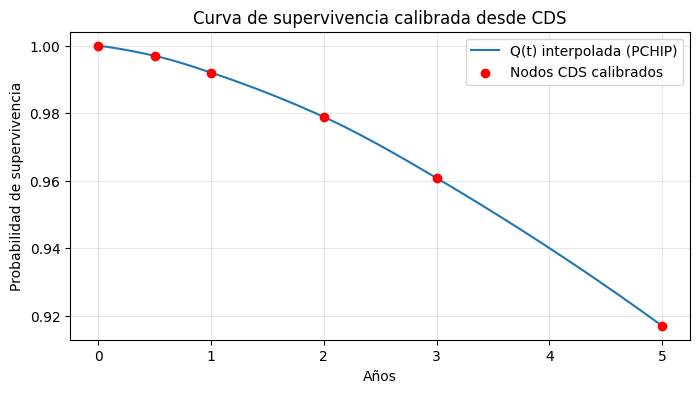

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo — FX forward EUR/USD (Garman-Kohlhagen)
# ============================================================
def pfe_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                    n_paths=100_000, pct=99, mu=None, seed=1):
    """
    V(t) = N * [S(t)*exp(-r_for*(T-t)) - K*exp(-r_dom*(T-t))]
    r_dom = tasa doméstica (USD, descuenta el strike)
    r_for = tasa extranjera (EUR, juega el rol de 'dividend yield')
    N     = notional en unidades de la divisa base (EUR)
    """
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


# ============================================================
# 2. Calibración de la curva de PD/supervivencia desde CDS (sin cambios)
# ============================================================
def calibrate_survival_curve(cds_tenors, cds_spreads_bps, RR=0.25):
    """
    Aproximación simple: lambda_t = s_t / (1-RR)  (hazard rate promedio acumulado a t)
    Q(t) = exp(-lambda_t * t)
    Ancla Q(0)=1 para poder interpolar/extrapolar antes del primer tenor.
    """
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0

    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)

    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))

    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)

    def Q(t):
        t = np.asarray(t, float)
        return np.exp(log_Q_interp(t))

    return Q, tenors_anchored, Q_anchored


# ============================================================
# 3. CVA a partir del perfil de EE (sin cambios en la mecánica)
# ============================================================
def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    """
    CVA ≈ (1-RR) * sum_i  EE_promedio(i) * [Q(t_{i-1}) - Q(t_i)] * DF(t_i)
    r aquí debe ser la tasa de descuento en la MISMA moneda en que quieres el CVA
    (USD en este caso, porque el notional y la exposición están en USD).
    """
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)

    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])

    cva_contributions = (1 - RR) * epe_avg * dPD * DF
    cva_total = cva_contributions.sum()

    return cva_total, dPD, cva_contributions


# ================= Uso =================

# --- Parámetros de mercado del FX forward ---
S0          = 1.1622          # spot EUR/USD (USD por 1 EUR)
r_usd       = 0.039           # tasa doméstica USD (SOFR 12M ~3.9%)
r_eur       = 0.020           # tasa extranjera EUR (€STR/ECB depo ~2.0%)
sigma_fx    = 0.075           # vol ATM 1Y EUR/USD
T           = 1.0
notional_usd = 10_000_000.0

K = S0 * np.exp((r_usd - r_eur) * T)     # forward ATM, paridad de tasas
N_EUR = notional_usd / S0                # notional convertido a unidades de EUR

print(f"Spot EUR/USD: {S0:.4f}  |  Forward K: {K:.4f}  |  Notional: {N_EUR:,.0f} EUR")

# --- Monte Carlo del FX forward ---
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
t, pfe, epe = pfe_fx_forward(
    S0=S0, K=K, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx,
    T=T, time_grid=grid, N=N_EUR, n_paths=100_000, pct=99, seed=1
)

# --- Curva CDS de la contraparte (misma que usamos para el equity forward) ---
cds_tenors  = [0.5, 1, 2, 3, 5]
cds_spreads = [45, 60, 80, 100, 130]
RR = 0.25

Q, tenors_anchored, Q_anchored = calibrate_survival_curve(cds_tenors, cds_spreads, RR=RR)

# --- CVA, descontado con la tasa USD (misma moneda en que está expresada la exposición) ---
cva, dPD, contrib = compute_cva(t, epe, Q, r=r_usd, RR=RR)

print("\nEPE (USD):", np.round(epe, 2))
print("PFE (USD):", np.round(pfe, 2))
print("\nSupervivencia en tenors CDS:", dict(zip(cds_tenors, Q(cds_tenors))))
print("Probabilidad marginal de default por intervalo:", np.round(dPD, 5))
print("Contribución de CVA por intervalo (USD):", np.round(contrib, 2))
print(f"\nCVA total ≈ {cva:,.2f} USD")

# --- Plot de la curva de supervivencia ---
t_fine = np.linspace(0, 5, 200)
plt.figure(figsize=(8,4))
plt.plot(t_fine, Q(t_fine), label='Q(t) interpolada (PCHIP)')
plt.scatter(tenors_anchored, Q_anchored, color='red', zorder=5, label='Nodos CDS calibrados')
plt.xlabel('Años'); plt.ylabel('Probabilidad de supervivencia')
plt.title('Curva de supervivencia calibrada desde CDS')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

In [ ]:
cva_spread= 1246.31 / 10_000_000
print(cva_spread*10_000)

1.24631


In [ ]:
def cva_running_spread(time_grid, Q_func, r, cva_total):
    """
    Convierte el CVA (valor presente, en $) a un spread anualizado (running),
    análogo a convertir un upfront de CDS en running spread.
    """
    t_ext = np.concatenate(([0.0], time_grid))
    dt = np.diff(t_ext)                          # duración de cada intervalo
    Q_mid = Q_func(time_grid)                     # supervivencia al final de cada intervalo (aprox. simple)
    DF = np.exp(-r * time_grid)

    annuity = np.sum(DF * Q_mid * dt)             # risky annuity (RPV01-like)
    s_cva = cva_total / annuity                   # $ por año

    return s_cva, annuity


s_cva, annuity = cva_running_spread(t, Q, r_usd, cva)

print(f"Annuity (risky PV01): {annuity:.6f}")
print(f"CVA running spread: {s_cva:,.2f} USD/año")

# Expresado como spread sobre el notional, en basis points (convención de mercado)
s_cva_bps = (s_cva / notional_usd) * 10_000
print(f"CVA spread anualizado: {s_cva_bps:.2f} bps sobre notional")

Annuity (risky PV01): 0.969643
CVA running spread: 1,285.33 USD/año
CVA spread anualizado: 1.29 bps sobre notional


## DVA

Spot EUR/USD: 1.1622  |  Forward K: 1.1845  |  Notional: 8,604,371 EUR

EPE (USD): [ 40249.51  57245.79  69993.07  80741.01 119027.69 146796.44 209541.3
 304757.25]
ENE (USD): [ -40720.84  -57752.24  -70912.83  -81896.43 -120143.24 -147331.97
 -210328.75 -304865.54]

CVA total ≈ 1,246.31 USD  (riesgo de que la contraparte quiebre)
DVA total ≈ 295.77 USD  (beneficio si el banco propio quebrara)
Bilateral XVA (CVA - DVA) ≈ 950.54 USD


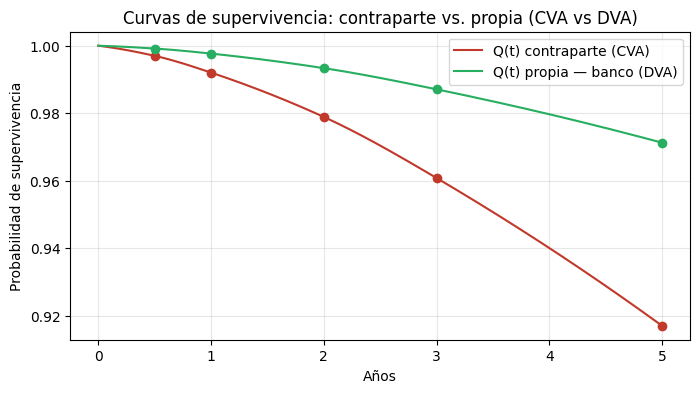

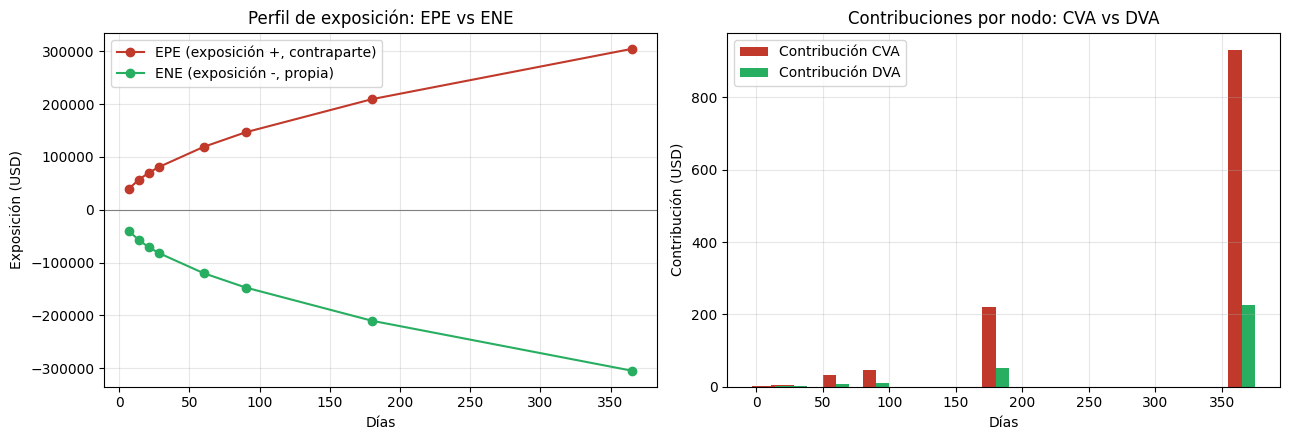

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo — FX forward EUR/USD (Garman-Kohlhagen)
#    Ahora devuelve también ENE (Expected Negative Exposure), necesaria para DVA
# ============================================================
def exposure_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                         n_paths=100_000, pct=99, mu=None, seed=1):
    """
    V(t) = N * [S(t)*exp(-r_for*(T-t)) - K*exp(-r_dom*(T-t))]
    Devuelve:
      pfe : percentil 99 de la exposición positiva  -> usado para CVA
      epe : Expected Positive Exposure               -> usado para CVA
      ene : Expected Negative Exposure (negativo)     -> usado para DVA
    """
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))
    ene = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))

        exposure_pos = np.maximum(V, 0.0)
        exposure_neg = np.minimum(V, 0.0)     # <- negativa, para DVA

        pfe[i] = np.percentile(exposure_pos, pct)
        epe[i] = exposure_pos.mean()
        ene[i] = exposure_neg.mean()           # queda como número negativo o cero

    return time_grid, pfe, epe, ene


# ============================================================
# 2. Calibración de la curva de PD/supervivencia desde CDS (sin cambios)
# ============================================================
def calibrate_survival_curve(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0

    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)

    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))

    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)

    def Q(t):
        t = np.asarray(t, float)
        return np.exp(log_Q_interp(t))

    return Q, tenors_anchored, Q_anchored


# ============================================================
# 3. CVA (contraparte) y DVA (propio) — misma estructura, distinta exposición y curva
# ============================================================
def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    """CVA ≈ (1-RR) * sum EE_avg * dPD_contraparte * DF"""
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)

    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])

    contrib = (1 - RR) * epe_avg * dPD * DF
    return contrib.sum(), dPD, contrib


def compute_dva(time_grid, ene, Q_func_own, r, RR_own=0.40):
    """
    DVA ≈ (1-RR_own) * sum |ENE_avg| * dPD_propio * DF
    ene llega en negativo; se reporta como magnitud positiva (convención estándar).
    Q_func_own = curva de supervivencia PROPIA del banco (no la de la contraparte).
    """
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func_own(t)
    dPD_own = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)

    ene_ext = np.concatenate(([0.0], ene))
    ene_avg = 0.5 * (ene_ext[:-1] + ene_ext[1:])   # sigue negativo

    contrib = (1 - RR_own) * np.abs(ene_avg) * dPD_own * DF
    return contrib.sum(), dPD_own, contrib


# ================= Uso =================

# --- Parámetros de mercado del FX forward ---
S0          = 1.1622
r_usd       = 0.039
r_eur       = 0.020
sigma_fx    = 0.075
T           = 1.0
notional_usd = 10_000_000.0

K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

print(f"Spot EUR/USD: {S0:.4f}  |  Forward K: {K:.4f}  |  Notional: {N_EUR:,.0f} EUR")

# --- Monte Carlo del FX forward (con EPE y ENE) ---
grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
t, pfe, epe, ene = exposure_fx_forward(
    S0=S0, K=K, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx,
    T=T, time_grid=grid, N=N_EUR, n_paths=100_000, pct=99, seed=1
)

# --- Curva CDS de la CONTRAPARTE (igual que antes, para el CVA) ---
cds_tenors_cpty  = [0.5, 1, 2, 3, 5]
cds_spreads_cpty = [45, 60, 80, 100, 130]
RR_cpty = 0.25

Q_cpty, _, _ = calibrate_survival_curve(cds_tenors_cpty, cds_spreads_cpty, RR=RR_cpty)

# --- Curva de crédito PROPIA (banco, menor riesgo -> spreads mucho más bajos) ---
cds_tenors_own  = [0.5, 1, 2, 3, 5]
cds_spreads_own = [10, 14, 20, 26, 35]     # ilustrativo: banco IG de alta calidad (AA/AA-)
RR_own = 0.40                               # RR típicamente más alto para deuda bancaria senior

Q_own, tenors_own_anchored, Q_own_anchored = calibrate_survival_curve(
    cds_tenors_own, cds_spreads_own, RR=RR_own
)

# --- CVA (usa curva de la contraparte) y DVA (usa curva propia) ---
cva, dPD_cpty, contrib_cva = compute_cva(t, epe, Q_cpty, r=r_usd, RR=RR_cpty)
dva, dPD_own, contrib_dva = compute_dva(t, ene, Q_own, r=r_usd, RR_own=RR_own)

bilateral_xva = cva - dva

print("\nEPE (USD):", np.round(epe, 2))
print("ENE (USD):", np.round(ene, 2))
print(f"\nCVA total ≈ {cva:,.2f} USD  (riesgo de que la contraparte quiebre)")
print(f"DVA total ≈ {dva:,.2f} USD  (beneficio si el banco propio quebrara)")
print(f"Bilateral XVA (CVA - DVA) ≈ {bilateral_xva:,.2f} USD")

# --- Plot: comparación de ambas curvas de supervivencia ---
t_fine = np.linspace(0, 5, 200)
plt.figure(figsize=(8,4))
plt.plot(t_fine, Q_cpty(t_fine), color='#c0392b', label='Q(t) contraparte (CVA)')
plt.plot(t_fine, Q_own(t_fine), color='#27ae60', label='Q(t) propia — banco (DVA)')
plt.scatter(cds_tenors_cpty, Q_cpty(cds_tenors_cpty), color='#c0392b', zorder=5)
plt.scatter(cds_tenors_own, Q_own(cds_tenors_own), color='#27ae60', zorder=5)
plt.xlabel('Años'); plt.ylabel('Probabilidad de supervivencia')
plt.title('Curvas de supervivencia: contraparte vs. propia (CVA vs DVA)')
plt.legend(); plt.grid(alpha=0.3)
plt.show()

# --- Plot: EPE vs ENE, y contribuciones de CVA vs DVA por nodo ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
days = t * 365

axes[0].plot(days, epe, 'o-', color='#c0392b', label='EPE (exposición +, contraparte)')
axes[0].plot(days, ene, 'o-', color='#27ae60', label='ENE (exposición -, propia)')
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_xlabel('Días'); axes[0].set_ylabel('Exposición (USD)')
axes[0].set_title('Perfil de exposición: EPE vs ENE')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].bar(days - 5, contrib_cva, width=10, color='#c0392b', label='Contribución CVA')
axes[1].bar(days + 5, contrib_dva, width=10, color='#27ae60', label='Contribución DVA')
axes[1].set_xlabel('Días'); axes[1].set_ylabel('Contribución (USD)')
axes[1].set_title('Contribuciones por nodo: CVA vs DVA')
axes[1].legend(); axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

EPE sin colateral: [ 40495.49  57615.34  70973.85  82226.54 120270.91 147840.95 211127.27
 307171.51]
EPE con VM diario: [0. 0. 0. 0. 0. 0. 0. 0.]
EPE con VM semanal: [    0.       0.       0.       0.   30736.29 37995.85 34715.34 15923.08]

ENE sin colateral: [ -40839.7   -57786.07  -70395.37  -81305.05 -118763.15 -145524.31
 -208892.4  -303558.98]
ENE con VM diario: [0. 0. 0. 0. 0. 0. 0. 0.]
ENE con VM semanal: [     0.        0.        0.        0.   -30841.04 -37630.67 -35085.99
 -15873.13]


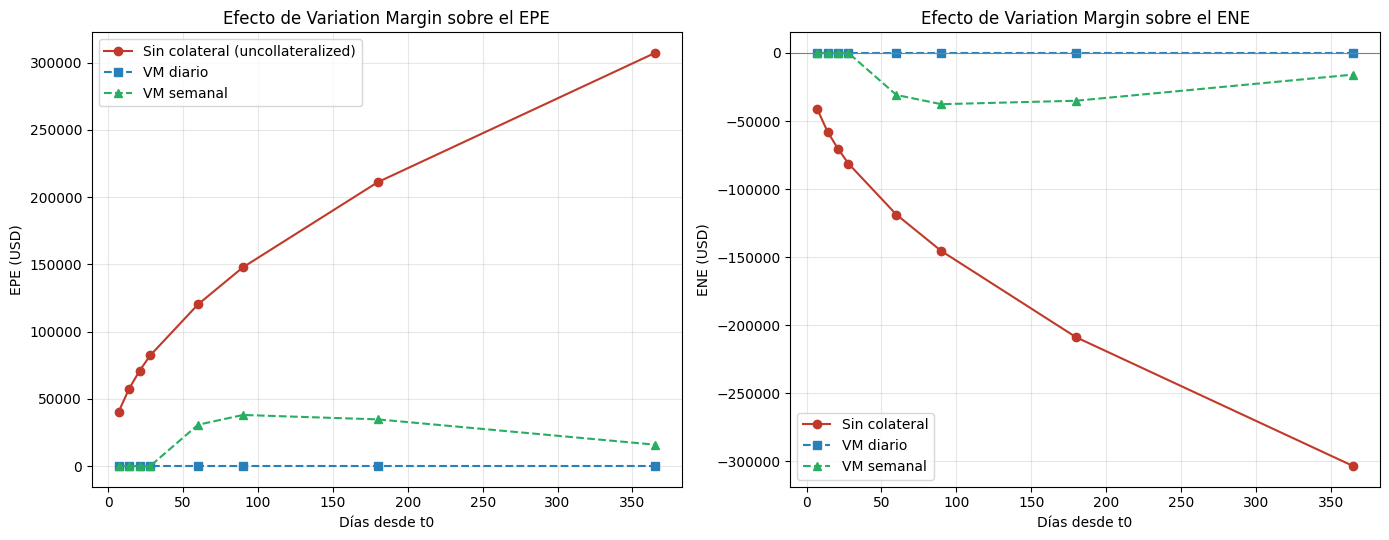

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Motor Monte Carlo con trayectoria diaria completa
#    (necesario para simular colateral que se resetea periódicamente)
# ============================================================
def simulate_fx_paths_daily(S0, r_dom, r_for, sigma, T, n_paths=100_000, mu=None, seed=1):
    """Simula la trayectoria diaria completa de S(t) durante toda la vida del trade."""
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu

    n_days = int(round(T * 365))
    dt = T / n_days                      # paso diario uniforme

    S = np.full(n_paths, S0, dtype=float)
    S_path = np.empty((n_paths, n_days + 1))
    S_path[:, 0] = S0

    for i in range(1, n_days + 1):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
        S_path[:, i] = S

    day_grid = np.arange(n_days + 1) * dt   # en años
    return day_grid, S_path


def mtm_fx_forward(S_path, K, r_dom, r_for, T, day_grid, N):
    """V(t) para cada path y cada día, vectorizado."""
    tau = np.clip(T - day_grid, 0, None)                     # tiempo restante a vencimiento
    V = N * (S_path * np.exp(-r_for * tau) - K * np.exp(-r_dom * tau))
    return V


# ============================================================
# 2. Efecto de Variation Margin: colateral se resetea cada 'freq_days'
# ============================================================
def apply_variation_margin(V, day_grid, freq_days):
    """
    Colateral C(t): se actualiza al MtM exacto en cada fecha de margin call
    (cada 'freq_days' días), permanece fijo entre llamadas.
    Exposición neta de colateral: V(t) - C(t).
    Umbral = 0, MTA = 0 (colateralización completa en cada reset).
    """
    n_days = V.shape[1]
    call_dates = np.arange(0, n_days, freq_days)   # índices donde se resetea el colateral

    C = np.zeros_like(V)
    for idx, call_idx in enumerate(call_dates):
        end_idx = call_dates[idx+1] if idx+1 < len(call_dates) else n_days
        C[:, call_idx:end_idx] = V[:, call_idx:call_idx+1]   # colateral fijo = MtM en la última llamada

    V_net = V - C
    return V_net


def epe_ene_from_paths(V, day_grid, coarse_grid, pct=99):
    """Extrae EE, ENE, PFE en los nodos del grid original (coarse) desde la malla diaria."""
    idx = np.array([np.argmin(np.abs(day_grid - t)) for t in coarse_grid])
    V_at_nodes = V[:, idx]

    exposure_pos = np.maximum(V_at_nodes, 0.0)
    exposure_neg = np.minimum(V_at_nodes, 0.0)

    epe = exposure_pos.mean(axis=0)
    ene = exposure_neg.mean(axis=0)
    pfe = np.percentile(exposure_pos, pct, axis=0)

    return epe, ene, pfe


# ================= Uso =================

# --- Parámetros de mercado (los mismos del FX forward) ---
S0          = 1.1622
r_usd       = 0.039
r_eur       = 0.020
sigma_fx    = 0.075
T           = 1.0
notional_usd = 10_000_000.0

K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

# --- Simulación diaria completa (una sola vez, se reutiliza para todos los escenarios) ---
day_grid, S_path = simulate_fx_paths_daily(
    S0=S0, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T,
    n_paths=100_000, seed=1
)
V_full = mtm_fx_forward(S_path, K, r_dom=r_usd, r_for=r_eur, T=T, day_grid=day_grid, N=N_EUR)

# --- Nodos de comparación (mismo grid usado en scripts anteriores) ---
coarse_grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365

# --- Escenario 1: SIN colateral (uncollateralized) ---
epe_unc, ene_unc, pfe_unc = epe_ene_from_paths(V_full, day_grid, coarse_grid)

# --- Escenario 2: VM diario ---
V_daily = apply_variation_margin(V_full, day_grid, freq_days=1)
epe_daily, ene_daily, pfe_daily = epe_ene_from_paths(V_daily, day_grid, coarse_grid)

# --- Escenario 3: VM semanal ---
V_weekly = apply_variation_margin(V_full, day_grid, freq_days=7)
epe_weekly, ene_weekly, pfe_weekly = epe_ene_from_paths(V_weekly, day_grid, coarse_grid)

print("EPE sin colateral:", np.round(epe_unc, 2))
print("EPE con VM diario:", np.round(epe_daily, 2))
print("EPE con VM semanal:", np.round(epe_weekly, 2))
print()
print("ENE sin colateral:", np.round(ene_unc, 2))
print("ENE con VM diario:", np.round(ene_daily, 2))
print("ENE con VM semanal:", np.round(ene_weekly, 2))


# ============================================================
# 3. Plots: EE y ENE, con y sin efecto de Variation Margin
# ============================================================
days_plot = coarse_grid * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# --- Panel izquierdo: EPE ---
axes[0].plot(days_plot, epe_unc,    'o-',  color='#c0392b', label='Sin colateral (uncollateralized)')
axes[0].plot(days_plot, epe_daily,  's--', color='#2980b9', label='VM diario')
axes[0].plot(days_plot, epe_weekly, '^--', color='#27ae60', label='VM semanal')
axes[0].set_xlabel('Días desde t0'); axes[0].set_ylabel('EPE (USD)')
axes[0].set_title('Efecto de Variation Margin sobre el EPE')
axes[0].legend(); axes[0].grid(alpha=0.3)

# --- Panel derecho: ENE ---
axes[1].plot(days_plot, ene_unc,    'o-',  color='#c0392b', label='Sin colateral')
axes[1].plot(days_plot, ene_daily,  's--', color='#2980b9', label='VM diario')
axes[1].plot(days_plot, ene_weekly, '^--', color='#27ae60', label='VM semanal')
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set_xlabel('Días desde t0'); axes[1].set_ylabel('ENE (USD)')
axes[1].set_title('Efecto de Variation Margin sobre el ENE')
axes[1].legend(); axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

EPE sin colateral:       [ 40495.49  57615.34  70973.85  82226.54 120270.91 147840.95 211127.27
 307171.51]
EPE VM semanal + MTA20k: [  782.21   761.08   770.8    758.34 30787.13 38027.38 34764.06 16023.04]

ENE sin colateral:       [ -40839.7   -57786.07  -70395.37  -81305.05 -118763.15 -145524.31
 -208892.4  -303558.98]
ENE VM semanal + MTA20k: [  -774.24   -779.78   -797.16   -777.83 -30903.92 -37676.2  -35138.67
 -15973.46]


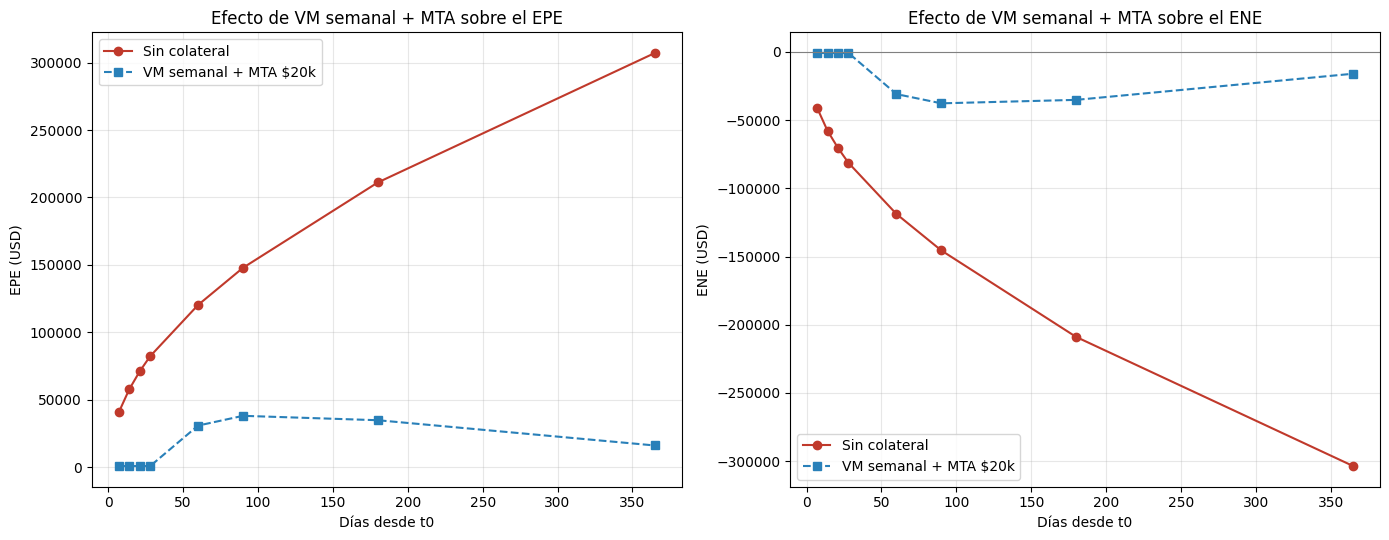

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Motor Monte Carlo con trayectoria diaria completa (igual que antes)
# ============================================================
def simulate_fx_paths_daily(S0, r_dom, r_for, sigma, T, n_paths=100_000, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu

    n_days = int(round(T * 365))
    dt = T / n_days

    S = np.full(n_paths, S0, dtype=float)
    S_path = np.empty((n_paths, n_days + 1))
    S_path[:, 0] = S0

    for i in range(1, n_days + 1):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
        S_path[:, i] = S

    day_grid = np.arange(n_days + 1) * dt
    return day_grid, S_path


def mtm_fx_forward(S_path, K, r_dom, r_for, T, day_grid, N):
    tau = np.clip(T - day_grid, 0, None)
    V = N * (S_path * np.exp(-r_for * tau) - K * np.exp(-r_dom * tau))
    return V


# ============================================================
# 2. Variation Margin semanal CON Minimum Transfer Amount (MTA)
#    El colateral solo se mueve si |V(t) - C_actual| > MTA
# ============================================================
def apply_variation_margin_mta(V, day_grid, freq_days, mta):
    """
    En cada fecha de llamada (cada 'freq_days'), se compara el MtM contra
    el colateral vigente. Si la diferencia supera el MTA, se transfiere
    colateral hasta igualar el MtM (colateral se actualiza). Si no supera
    el MTA, el colateral queda igual que antes (no hay transferencia).
    """
    n_paths, n_days = V.shape
    call_dates = np.arange(0, n_days, freq_days)

    C = np.zeros(n_paths)                 # colateral vigente, arranca en 0
    V_net = np.empty_like(V)
    V_net[:, 0] = V[:, 0] - C

    prev_idx = 0
    for call_idx in call_dates[1:]:
        # colateral se mantiene igual desde la última llamada hasta ahora
        V_net[:, prev_idx:call_idx] = V[:, prev_idx:call_idx] - C[:, None]

        # en la fecha de llamada: decide si se transfiere colateral
        gap = V[:, call_idx] - C
        transfer = np.abs(gap) > mta
        C = np.where(transfer, V[:, call_idx], C)   # solo actualiza donde se cruzó el MTA

        prev_idx = call_idx

    # último tramo hasta el final del trade
    V_net[:, prev_idx:] = V[:, prev_idx:] - C[:, None]

    return V_net


def epe_ene_from_paths(V, day_grid, coarse_grid, pct=99):
    idx = np.array([np.argmin(np.abs(day_grid - t)) for t in coarse_grid])
    V_at_nodes = V[:, idx]

    exposure_pos = np.maximum(V_at_nodes, 0.0)
    exposure_neg = np.minimum(V_at_nodes, 0.0)

    epe = exposure_pos.mean(axis=0)
    ene = exposure_neg.mean(axis=0)
    pfe = np.percentile(exposure_pos, pct, axis=0)

    return epe, ene, pfe


# ================= Uso =================

S0          = 1.1622
r_usd       = 0.039
r_eur       = 0.020
sigma_fx    = 0.075
T           = 1.0
notional_usd = 10_000_000.0
MTA         = 20_000.0        # USD

K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

day_grid, S_path = simulate_fx_paths_daily(
    S0=S0, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T,
    n_paths=100_000, seed=1
)
V_full = mtm_fx_forward(S_path, K, r_dom=r_usd, r_for=r_eur, T=T, day_grid=day_grid, N=N_EUR)

coarse_grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365

# --- Sin colateral ---
epe_unc, ene_unc, pfe_unc = epe_ene_from_paths(V_full, day_grid, coarse_grid)

# --- VM semanal, con MTA = 20k ---
V_weekly_mta = apply_variation_margin_mta(V_full, day_grid, freq_days=7, mta=MTA)
epe_mta, ene_mta, pfe_mta = epe_ene_from_paths(V_weekly_mta, day_grid, coarse_grid)

print("EPE sin colateral:      ", np.round(epe_unc, 2))
print("EPE VM semanal + MTA20k:", np.round(epe_mta, 2))
print()
print("ENE sin colateral:      ", np.round(ene_unc, 2))
print("ENE VM semanal + MTA20k:", np.round(ene_mta, 2))


# ============================================================
# 3. Plots
# ============================================================
days_plot = coarse_grid * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(days_plot, epe_unc, 'o-', color='#c0392b', label='Sin colateral')
axes[0].plot(days_plot, epe_mta, 's--', color='#2980b9', label='VM semanal + MTA $20k')
axes[0].set_xlabel('Días desde t0'); axes[0].set_ylabel('EPE (USD)')
axes[0].set_title('Efecto de VM semanal + MTA sobre el EPE')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(days_plot, ene_unc, 'o-', color='#c0392b', label='Sin colateral')
axes[1].plot(days_plot, ene_mta, 's--', color='#2980b9', label='VM semanal + MTA $20k')
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set_xlabel('Días desde t0'); axes[1].set_ylabel('ENE (USD)')
axes[1].set_title('Efecto de VM semanal + MTA sobre el ENE')
axes[1].legend(); axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

EPE sin colateral:       [ 40495.49  57615.34  70973.85  82226.54 123274.62 148663.4  212272.95
 306698.04]
EPE VM semanal+MTA20k:   [782.21 761.08 770.8  758.34 768.55 765.43 773.23 744.76]
ENE sin colateral:       [ -40839.7   -57786.07  -70395.37  -81305.05 -121724.03 -146427.8
 -210228.78 -303135.46]
ENE VM semanal+MTA20k:   [-774.24 -779.78 -797.16 -777.83 -787.87 -769.01 -775.45 -745.14]


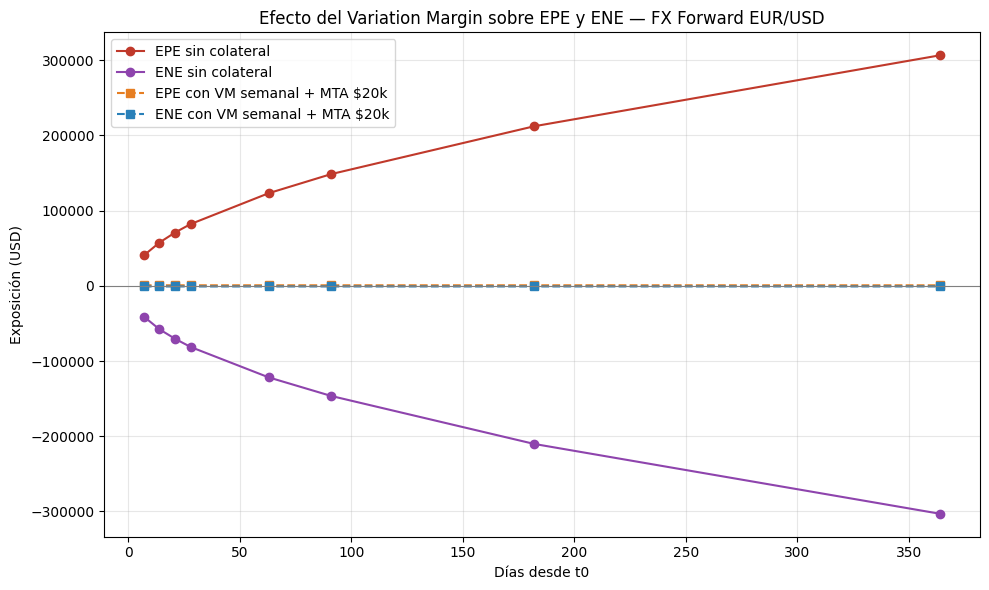

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def simulate_fx_paths_daily(S0, r_dom, r_for, sigma, T, n_paths=100_000, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    n_days = int(round(T * 365))
    dt = T / n_days

    S = np.full(n_paths, S0, dtype=float)
    S_path = np.empty((n_paths, n_days + 1))
    S_path[:, 0] = S0
    for i in range(1, n_days + 1):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
        S_path[:, i] = S

    day_grid = np.arange(n_days + 1) * dt
    return day_grid, S_path


def mtm_fx_forward(S_path, K, r_dom, r_for, T, day_grid, N):
    tau = np.clip(T - day_grid, 0, None)
    return N * (S_path * np.exp(-r_for * tau) - K * np.exp(-r_dom * tau))


def apply_variation_margin_mta(V, day_grid, freq_days, mta):
    n_paths, n_days = V.shape
    call_dates = np.arange(0, n_days, freq_days)

    C = np.zeros(n_paths)
    V_net = np.empty_like(V)
    V_net[:, 0] = V[:, 0] - C

    prev_idx = 0
    for call_idx in call_dates[1:]:
        V_net[:, prev_idx:call_idx] = V[:, prev_idx:call_idx] - C[:, None]
        gap = V[:, call_idx] - C
        transfer = np.abs(gap) > mta
        C = np.where(transfer, V[:, call_idx], C)
        prev_idx = call_idx
    V_net[:, prev_idx:] = V[:, prev_idx:] - C[:, None]
    return V_net


def epe_ene_from_paths(V, day_grid, coarse_grid, pct=99):
    idx = np.array([np.argmin(np.abs(day_grid - t)) for t in coarse_grid])
    V_at_nodes = V[:, idx]
    exposure_pos = np.maximum(V_at_nodes, 0.0)
    exposure_neg = np.minimum(V_at_nodes, 0.0)
    return exposure_pos.mean(axis=0), exposure_neg.mean(axis=0), np.percentile(exposure_pos, pct, axis=0)


# ================= Parámetros =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd, MTA = 10_000_000.0, 20_000.0

K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

day_grid, S_path = simulate_fx_paths_daily(S0, r_usd, r_eur, sigma_fx, T, n_paths=100_000, seed=1)
V_full = mtm_fx_forward(S_path, K, r_usd, r_eur, T, day_grid, N_EUR)

# --- Grid alineado a múltiplos de 7 (consistente con la frecuencia de reset) ---
coarse_grid = np.array([7, 14, 21, 28, 63, 91, 182, 364]) / 365   # <- ajustado: todos múltiplos de 7

epe_unc, ene_unc, _ = epe_ene_from_paths(V_full, day_grid, coarse_grid)

V_weekly_mta = apply_variation_margin_mta(V_full, day_grid, freq_days=7, mta=MTA)
epe_mta, ene_mta, _ = epe_ene_from_paths(V_weekly_mta, day_grid, coarse_grid)

print("EPE sin colateral:      ", np.round(epe_unc, 2))
print("EPE VM semanal+MTA20k:  ", np.round(epe_mta, 2))
print("ENE sin colateral:      ", np.round(ene_unc, 2))
print("ENE VM semanal+MTA20k:  ", np.round(ene_mta, 2))

# ================= Plot único =================
days_plot = coarse_grid * 365

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(days_plot, epe_unc, 'o-', color='#c0392b', label='EPE sin colateral')
ax.plot(days_plot, ene_unc, 'o-', color='#8e44ad', label='ENE sin colateral')
ax.plot(days_plot, epe_mta, 's--', color='#e67e22', label='EPE con VM semanal + MTA $20k')
ax.plot(days_plot, ene_mta, 's--', color='#2980b9', label='ENE con VM semanal + MTA $20k')

ax.axhline(0, color='gray', linewidth=0.8)
ax.set_xlabel('Días desde t0')
ax.set_ylabel('Exposición (USD)')
ax.set_title('Efecto del Variation Margin sobre EPE y ENE — FX Forward EUR/USD')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [ ]:
import numpy as np
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo -- FX forward EUR/USD (Garman-Kohlhagen)
# ============================================================
def exposure_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                         n_paths=100_000, pct=99, mu=None, seed=1):
    """
    V(t) = N * [S(t)*exp(-r_for*(T-t)) - K*exp(-r_dom*(T-t))]
    r_dom = tasa doméstica (USD)   r_for = tasa extranjera (EUR)
    N     = notional en unidades de la divisa base (EUR)
    """
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu

    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


# ============================================================
# 2. Curva de supervivencia desde CDS
#    Dos variantes: PCHIP (suave, pero con fuga entre buckets)
#    y piecewise-constante (hazard aislado por bucket, para CS01 limpio)
# ============================================================
def calibrate_survival_curve_pchip(cds_tenors, cds_spreads_bps, RR=0.25):
    """Interpolación PCHIP sobre ln(Q). Suave, pero un bump en un nodo
    puede filtrarse ligeramente a intervalos vecinos vía las tangentes."""
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    Q_tenor = np.exp(-lam_cum * tenors)

    tenors_anchored = np.concatenate(([0.0], tenors))
    Q_anchored = np.concatenate(([1.0], Q_tenor))
    log_Q_interp = PchipInterpolator(tenors_anchored, np.log(Q_anchored), extrapolate=True)

    def Q(t):
        return np.exp(log_Q_interp(np.asarray(t, float)))
    return Q, tenors_anchored, Q_anchored


def calibrate_survival_curve_piecewise(cds_tenors, cds_spreads_bps, RR=0.25):
    """Hazard rate piecewise-constante entre tenors -- cada bucket queda
    aislado, sin fuga hacia intervalos vecinos (mejor para CS01 bucketed)."""
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    tenors_ext = np.concatenate(([0.0], tenors))

    def Q(t):
        t = np.atleast_1d(np.asarray(t, float))
        out = np.empty_like(t)
        for i, tt in enumerate(t):
            idx = np.searchsorted(tenors_ext, tt, side='right') - 1
            idx = np.clip(idx, 0, len(lam_cum) - 1)
            lam_prev = lam_cum[idx - 1] if idx > 0 else 0.0
            t_prev = tenors_ext[idx]
            lam_here = lam_cum[idx]
            cum_hazard = lam_prev * t_prev + lam_here * (tt - t_prev)
            out[i] = np.exp(-cum_hazard)
        return out
    return Q


# ============================================================
# 3. CVA a partir del perfil de EE
# ============================================================
def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)

    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])

    contrib = (1 - RR) * epe_avg * dPD * DF
    return contrib.sum(), contrib


def full_cva_pipeline_fx(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                          cds_tenors, cds_spreads, RR=0.25, n_paths=100_000,
                          seed=1, curve_type="pchip"):
    t, pfe, epe = exposure_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                                       n_paths=n_paths, seed=seed)
    if curve_type == "pchip":
        Q, _, _ = calibrate_survival_curve_pchip(cds_tenors, cds_spreads, RR=RR)
    else:
        Q = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)

    cva, contrib = compute_cva(t, epe, Q, r=r_dom, RR=RR)
    return cva, contrib, epe, t


# ================= Setup base =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
cds_tenors  = [0.5, 1, 2, 3, 5]
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])
RR = 0.25
N_PATHS = 200_000
SEED = 42     # common random numbers en todos los escenarios -> reduce ruido en las Greeks

kwargs = dict(K=K, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T, time_grid=grid,
              N=N_EUR, cds_tenors=cds_tenors, RR=RR, n_paths=N_PATHS, seed=SEED)

print(f"Spot EUR/USD: {S0:.4f}  |  Forward K: {K:.4f}  |  Notional: {N_EUR:,.0f} EUR")

cva_base, contrib_base, epe_base, t_grid = full_cva_pipeline_fx(
    S0=S0, cds_spreads=cds_spreads, curve_type="pchip", **kwargs
)
print(f"\nCVA base: {cva_base:,.2f} USD")


# ============================================================
# 4. Delta FX del CVA (bump-and-reprice, common random numbers)
# ============================================================
def cva_fx_delta(S0, dS_pct=0.01, **kwargs):
    dS = S0 * dS_pct
    cva_up, *_   = full_cva_pipeline_fx(S0=S0+dS, cds_spreads=cds_spreads, curve_type="pchip", **kwargs)
    cva_down, *_ = full_cva_pipeline_fx(S0=S0-dS, cds_spreads=cds_spreads, curve_type="pchip", **kwargs)
    delta = (cva_up - cva_down) / (2*dS)
    return delta, cva_up, cva_down

delta_cva, cva_up, cva_down = cva_fx_delta(S0, dS_pct=0.01, **kwargs)

print(f"\nCVA(S0+1%) = {cva_up:,.2f}   CVA(S0-1%) = {cva_down:,.2f}")
print(f"Delta FX del CVA (dCVA/dS0): {delta_cva:,.4f}")
print(f"Delta FX por 1% de movimiento en EUR/USD: {delta_cva*S0*0.01:,.2f} USD")


# ============================================================
# 5. CS01 bucketed -- curva piecewise-constante (aísla cada bucket)
#    No requiere resimular el spot: reusa epe_base ya calculado
# ============================================================
def cs01_bucketed(epe, t, cds_spreads, r_dom, RR=0.25, bump_bps=1.0):
    n = len(cds_spreads)
    cs01 = np.empty(n)

    Q_base = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)
    cva_base_pw, _ = compute_cva(t, epe, Q_base, r=r_dom, RR=RR)

    for k in range(n):
        bumped = cds_spreads.copy()
        bumped[k] += bump_bps
        Q_bumped = calibrate_survival_curve_piecewise(cds_tenors, bumped, RR=RR)
        cva_bumped, _ = compute_cva(t, epe, Q_bumped, r=r_dom, RR=RR)
        cs01[k] = cva_bumped - cva_base_pw

    return cs01, cva_base_pw


cs01, cva_base_pw = cs01_bucketed(epe_base, t_grid, cds_spreads, r_dom=r_usd, RR=RR, bump_bps=1.0)

print(f"\nCVA base (curva piecewise, referencia para CS01): {cva_base_pw:,.2f} USD")
print("\nCS01 bucketed por tenor:")
for tenor, sens in zip(cds_tenors, cs01):
    print(f"  {tenor}Y: {sens:,.4f} USD/bp")

cs01_parallel = cs01.sum()
print(f"\nCS01 paralelo (suma de bucketed): {cs01_parallel:,.4f} USD")

# --- Verificación directa del CS01 paralelo (bump simultáneo de todos los tenors) ---
cds_spreads_parallel = cds_spreads + 1.0
Q_par = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads_parallel, RR=RR)
cva_parallel, _ = compute_cva(t_grid, epe_base, Q_par, r=r_usd, RR=RR)
cs01_parallel_direct = cva_parallel - cva_base_pw
print(f"CS01 paralelo (bump directo, verificación): {cs01_parallel_direct:,.4f} USD")


# ============================================================
# 6. Resumen final
# ============================================================
print("\n" + "="*55)
print("RESUMEN DE GREEKS -- CVA del FX forward EUR/USD")
print("="*55)
print(f"CVA base:                     {cva_base:,.2f} USD")
print(f"Delta FX (por 1% de spot):    {delta_cva*S0*0.01:,.2f} USD")
for tenor, sens in zip(cds_tenors, cs01):
    print(f"CS01 {tenor}Y:                    {sens:,.4f} USD/bp")
print(f"CS01 paralelo:                 {cs01_parallel_direct:,.4f} USD")

Spot EUR/USD: 1.1622  |  Forward K: 1.1845  |  Notional: 8,604,371 EUR

CVA base: 1,254.16 USD

CVA(S0+1%) = 1,575.06   CVA(S0-1%) = 982.89
Delta FX del CVA (dCVA/dS0): 25,476.4767
Delta FX por 1% de movimiento en EUR/USD: 296.09 USD

CVA base (curva piecewise, referencia para CS01): 1,236.84 USD

CS01 bucketed por tenor:
  0.5Y: -5.5560 USD/bp
  1Y: 24.6853 USD/bp
  2Y: 0.0000 USD/bp
  3Y: 0.0000 USD/bp
  5Y: 0.0000 USD/bp

CS01 paralelo (suma de bucketed): 19.1293 USD
CS01 paralelo (bump directo, verificación): 19.1293 USD

RESUMEN DE GREEKS -- CVA del FX forward EUR/USD
CVA base:                     1,254.16 USD
Delta FX (por 1% de spot):    296.09 USD
CS01 0.5Y:                    -5.5560 USD/bp
CS01 1Y:                    24.6853 USD/bp
CS01 2Y:                    0.0000 USD/bp
CS01 3Y:                    0.0000 USD/bp
CS01 5Y:                    0.0000 USD/bp
CS01 paralelo:                 19.1293 USD


## Delta Hedge

CVA base: 1,236.84 USD
Delta FX del CVA: 25,412.19 EUR (notional equivalente)
CS01 bucketed CVA: [-5.556  24.6853  0.      0.      0.    ]

Notional de CDS por tenor (sin restricción, puede ser negativo = vender protección):
  0.5Y: -113,009 USD notional
  1.0Y: 254,030 USD notional
  2.0Y: 0 USD notional
  3.0Y: 0 USD notional
  5.0Y: 0 USD notional

Notional de CDS por tenor (NNLS, solo comprar protección, x>=0):
  0.5Y: 0 USD notional
  1.0Y: 254,030 USD notional
  2.0Y: 0 USD notional
  3.0Y: 0 USD notional
  5.0Y: 0 USD notional

CS01 residual neto (sin restricción): [0. 0. 0. 0. 0.]
CS01 residual neto (NNLS, solo compra): [-5.555983  0.        0.        0.        0.      ]

Notional FX hedge (posición corta en forward/spot EUR): 25,412 EUR
Delta FX neta después del hedge: 0.0000 EUR (debería ser ~0)


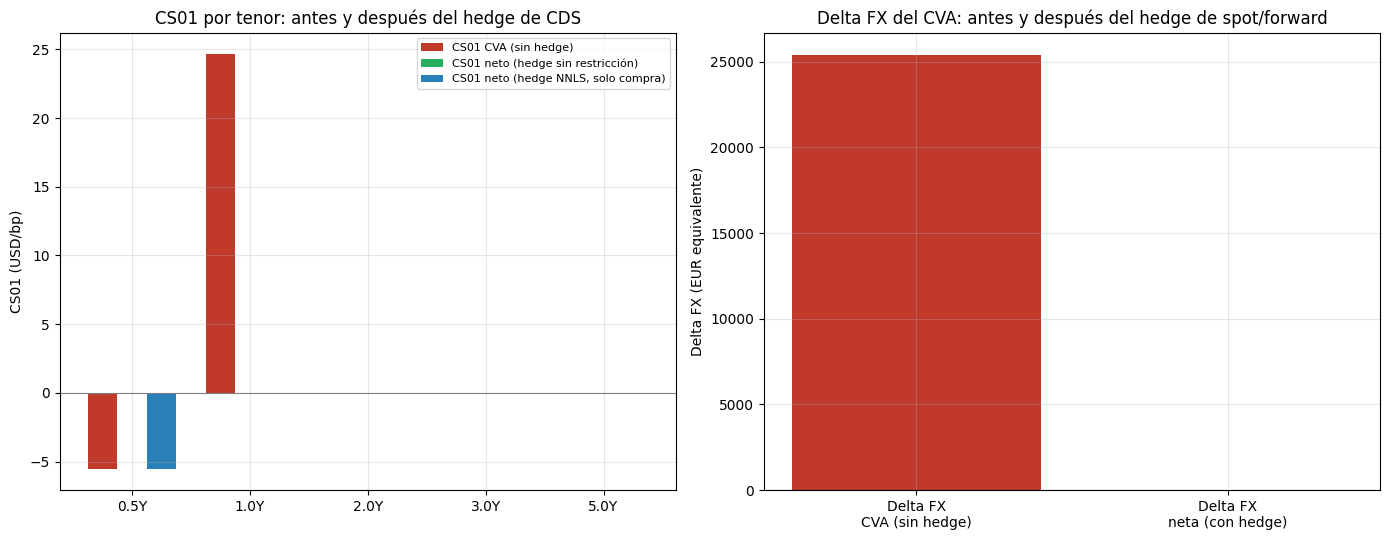

In [ ]:
import numpy as np
from scipy.interpolate import PchipInterpolator
from scipy.optimize import nnls
import matplotlib.pyplot as plt

# ============================================================
# 1. Motor Monte Carlo -- FX forward EUR/USD (Garman-Kohlhagen)
# ============================================================
def exposure_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                         n_paths=100_000, pct=99, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))
    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()
    return time_grid, pfe, epe


def calibrate_survival_curve_piecewise(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    tenors_ext = np.concatenate(([0.0], tenors))

    def Q(t):
        t = np.atleast_1d(np.asarray(t, float))
        out = np.empty_like(t)
        for i, tt in enumerate(t):
            idx = np.searchsorted(tenors_ext, tt, side='right') - 1
            idx = np.clip(idx, 0, len(lam_cum) - 1)
            lam_prev = lam_cum[idx - 1] if idx > 0 else 0.0
            t_prev = tenors_ext[idx]
            lam_here = lam_cum[idx]
            cum_hazard = lam_prev * t_prev + lam_here * (tt - t_prev)
            out[i] = np.exp(-cum_hazard)
        return out
    return Q


def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)
    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])
    contrib = (1 - RR) * epe_avg * dPD * DF
    return contrib.sum(), contrib


def rpv01(T, Q_func, r, freq=0.25):
    """Risky annuity (RPV01): valor presente de recibir $1/año, ponderado
    por supervivencia, con pagos trimestrales (convención estándar CDS)."""
    times = np.arange(freq, T + 1e-9, freq)
    if len(times) == 0 or times[-1] < T - 1e-9:
        times = np.append(times, T)
    DF = np.exp(-r * times)
    Qv = Q_func(times)
    dt_pay = np.diff(np.concatenate(([0.0], times)))
    return np.sum(DF * Qv * dt_pay)


# ================= Setup base (mismo trade FX del ejercicio anterior) =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365
cds_tenors  = np.array([0.5, 1, 2, 3, 5])
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])
RR = 0.25
N_PATHS = 200_000
SEED = 42

t_grid, pfe_base, epe_base = exposure_fx_forward(
    S0=S0, K=K, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T,
    time_grid=grid, N=N_EUR, n_paths=N_PATHS, seed=SEED
)

Q_base = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)
cva_base, _ = compute_cva(t_grid, epe_base, Q_base, r=r_usd, RR=RR)

# --- CS01 bucketed del CVA ---
def cs01_bucketed(epe, t, cds_spreads, r_dom, RR=0.25, bump_bps=1.0):
    n = len(cds_spreads)
    cs01 = np.empty(n)
    Q0 = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)
    cva0, _ = compute_cva(t, epe, Q0, r=r_dom, RR=RR)
    for k in range(n):
        bumped = cds_spreads.copy()
        bumped[k] += bump_bps
        Qb = calibrate_survival_curve_piecewise(cds_tenors, bumped, RR=RR)
        cvab, _ = compute_cva(t, epe, Qb, r=r_dom, RR=RR)
        cs01[k] = cvab - cva0
    return cs01

cs01_cva = cs01_bucketed(epe_base, t_grid, cds_spreads, r_dom=r_usd, RR=RR)

# --- Delta FX del CVA ---
def full_cva_fx(S0_):
    t_, pfe_, epe_ = exposure_fx_forward(S0=S0_, K=K, r_dom=r_usd, r_for=r_eur,
                                          sigma=sigma_fx, T=T, time_grid=grid,
                                          N=N_EUR, n_paths=N_PATHS, seed=SEED)
    Q_ = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)
    cva_, _ = compute_cva(t_, epe_, Q_, r=r_usd, RR=RR)
    return cva_

dS = S0 * 0.01
cva_up = full_cva_fx(S0 + dS)
cva_down = full_cva_fx(S0 - dS)
delta_cva = (cva_up - cva_down) / (2*dS)     # EUR de notional equivalente

print(f"CVA base: {cva_base:,.2f} USD")
print(f"Delta FX del CVA: {delta_cva:,.2f} EUR (notional equivalente)")
print("CS01 bucketed CVA:", np.round(cs01_cva, 4))


# ============================================================
# 2. OPTIMIZACIÓN: notional de CDS por tenor para neutralizar CS01
# ============================================================
cs01_per_unit_cds = np.array([
    rpv01(tn, Q_base, r_usd) * 0.0001 for tn in cds_tenors
])

M = np.diag(cs01_per_unit_cds)
target = cs01_cva.copy()

# --- (a) Solución sin restricciones (cerrada, permite vender protección) ---
notional_unconstrained = target / cs01_per_unit_cds

# --- (b) Solución con NNLS: solo se permite COMPRAR protección (x >= 0) ---
notional_nnls, residual_norm = nnls(M, target)

print("\nNotional de CDS por tenor (sin restricción, puede ser negativo = vender protección):")
for tn, n in zip(cds_tenors, notional_unconstrained):
    print(f"  {tn}Y: {n:,.0f} USD notional")

print("\nNotional de CDS por tenor (NNLS, solo comprar protección, x>=0):")
for tn, n in zip(cds_tenors, notional_nnls):
    print(f"  {tn}Y: {n:,.0f} USD notional")

cs01_hedge_unconstrained = M @ notional_unconstrained
cs01_hedge_nnls = M @ notional_nnls

cs01_net_unconstrained = cs01_cva - cs01_hedge_unconstrained
cs01_net_nnls = cs01_cva - cs01_hedge_nnls

print("\nCS01 residual neto (sin restricción):", np.round(cs01_net_unconstrained, 6))
print("CS01 residual neto (NNLS, solo compra):", np.round(cs01_net_nnls, 6))


# ============================================================
# 3. Hedge de FX delta: notional de spot/forward corto en EUR
# ============================================================
N_fx_hedge = delta_cva
print(f"\nNotional FX hedge (posición corta en forward/spot EUR): {N_fx_hedge:,.0f} EUR")

delta_neta = delta_cva - N_fx_hedge
print(f"Delta FX neta después del hedge: {delta_neta:,.4f} EUR (debería ser ~0)")


# ============================================================
# 4. Plots
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

x = np.arange(len(cds_tenors))
width = 0.25

axes[0].bar(x - width, cs01_cva, width, label='CS01 CVA (sin hedge)', color='#c0392b')
axes[0].bar(x, cs01_net_unconstrained, width, label='CS01 neto (hedge sin restricción)', color='#27ae60')
axes[0].bar(x + width, cs01_net_nnls, width, label='CS01 neto (hedge NNLS, solo compra)', color='#2980b9')
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_xticks(x)
axes[0].set_xticklabels([f'{tn}Y' for tn in cds_tenors])
axes[0].set_ylabel('CS01 (USD/bp)')
axes[0].set_title('CS01 por tenor: antes y después del hedge de CDS')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.3)

axes[1].bar(['Delta FX\nCVA (sin hedge)'], [delta_cva], color='#c0392b')
axes[1].bar(['Delta FX\nneta (con hedge)'], [delta_neta], color='#27ae60')
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].set_ylabel('Delta FX (EUR equivalente)')
axes[1].set_title('Delta FX del CVA: antes y después del hedge de spot/forward')
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## FVA

Spot EUR/USD: 1.1622  |  Notional: 8,604,371 EUR

EPE (USD): [ 40683.63  57480.79  70300.9   81481.23 119941.84 147489.8  211120.53
 306377.64]
ENE (USD): [ -40757.91  -57476.54  -70666.9   -81685.65 -119593.89 -146789.83
 -208808.61 -304708.05]

Funding spread por nodo (bps): [14.64 15.04 15.44 15.84 17.7  19.47 24.85 35.  ]

FCA (costo de fondeo, EPE): 592.1283 USD
FBA (beneficio de fondeo, ENE): 587.7485 USD
FVA = FCA - FBA: 4.3798 USD

Contribución FCA por nodo: [  0.5707   1.4133   1.887    2.298   15.5257  21.1955 107.7812 441.4568]
Contribución FBA por nodo: [  0.5718   1.4143   1.8924   2.3066  15.5146  21.1125 106.8759 438.0604]


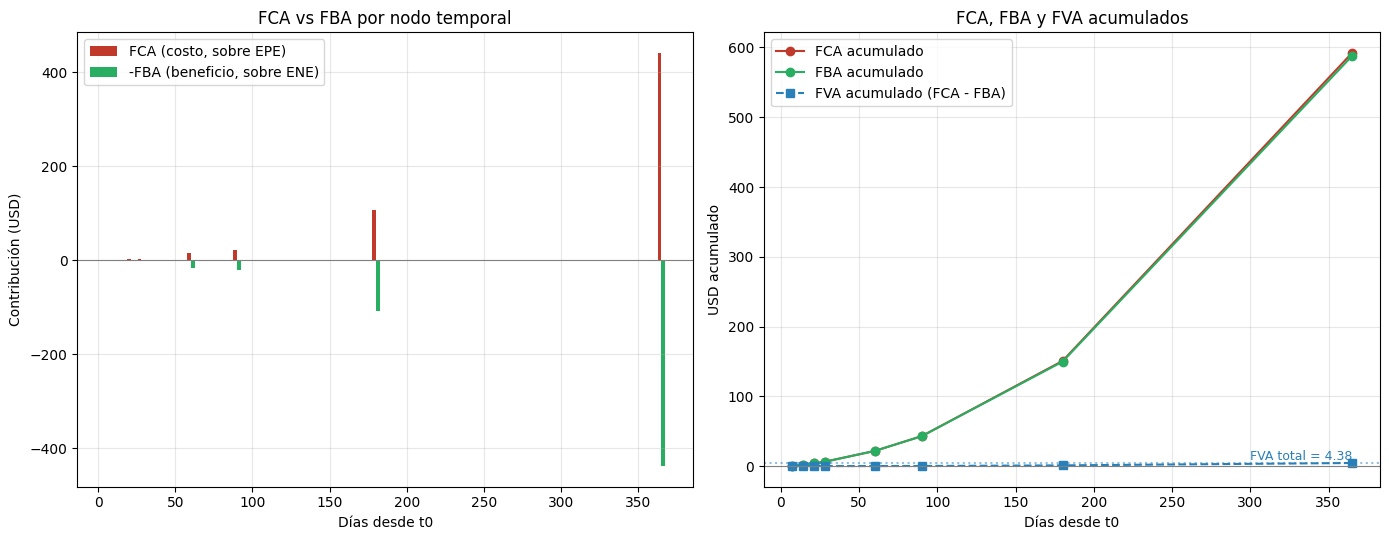

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo -- FX forward EUR/USD, con EPE y ENE
# ============================================================
def exposure_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                         n_paths=100_000, pct=99, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))
    ene = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))
        exposure_pos = np.maximum(V, 0.0)
        exposure_neg = np.minimum(V, 0.0)
        pfe[i] = np.percentile(exposure_pos, pct)
        epe[i] = exposure_pos.mean()
        ene[i] = exposure_neg.mean()

    return time_grid, pfe, epe, ene


# ============================================================
# 2. Curva de funding spread propio (término estructura simple)
# ============================================================
def calibrate_funding_curve(tenors, spreads_bps):
    """Interpola el funding spread propio (bps sobre risk-free) por tenor."""
    tenors = np.asarray(tenors, float)
    spreads = np.asarray(spreads_bps, float) / 10_000.0
    interp = PchipInterpolator(tenors, spreads, extrapolate=True)
    return lambda t: interp(np.asarray(t, float))


# ============================================================
# 3. FCA y FBA
# ============================================================
def compute_fca(time_grid, epe, sf_func, r):
    t = np.concatenate(([0.0], time_grid))
    dt = np.diff(t)
    sf = sf_func(time_grid)
    DF = np.exp(-r * time_grid)

    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])

    contrib = sf * epe_avg * DF * dt
    return contrib.sum(), contrib


def compute_fba(time_grid, ene, sf_func, r):
    t = np.concatenate(([0.0], time_grid))
    dt = np.diff(t)
    sf = sf_func(time_grid)
    DF = np.exp(-r * time_grid)

    ene_ext = np.concatenate(([0.0], ene))
    ene_avg = 0.5 * (ene_ext[:-1] + ene_ext[1:])   # negativo

    contrib = sf * np.abs(ene_avg) * DF * dt
    return contrib.sum(), contrib


# ================= Setup: mismo FX forward de siempre =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365

t, pfe, epe, ene = exposure_fx_forward(
    S0=S0, K=K, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T,
    time_grid=grid, N=N_EUR, n_paths=200_000, seed=42
)

# --- Curva de funding spread propio (ILUSTRATIVA -- reemplazar con la
#     curva real de Treasury/Funding si está disponible) ---
funding_tenors  = [0.5, 1, 2, 3, 5]
funding_spreads = [25, 35, 50, 65, 85]     # bps sobre risk-free (crédito propio + liquidez)

sf_func = calibrate_funding_curve(funding_tenors, funding_spreads)

fca, contrib_fca = compute_fca(t, epe, sf_func, r=r_usd)
fba, contrib_fba = compute_fba(t, ene, sf_func, r=r_usd)
fva = fca - fba

print(f"Spot EUR/USD: {S0:.4f}  |  Notional: {N_EUR:,.0f} EUR")
print(f"\nEPE (USD): {np.round(epe, 2)}")
print(f"ENE (USD): {np.round(ene, 2)}")
print(f"\nFunding spread por nodo (bps): {np.round(sf_func(t)*10000, 2)}")
print(f"\nFCA (costo de fondeo, EPE): {fca:,.4f} USD")
print(f"FBA (beneficio de fondeo, ENE): {fba:,.4f} USD")
print(f"FVA = FCA - FBA: {fva:,.4f} USD")

print("\nContribución FCA por nodo:", np.round(contrib_fca, 4))
print("Contribución FBA por nodo:", np.round(contrib_fba, 4))


# ============================================================
# 4. Plot: FCA vs FBA por nodo, y FVA acumulado
# ============================================================
days = t * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

width = (days[1]-days[0]) * 0.35 if len(days) > 1 else 5
axes[0].bar(days - width/2, contrib_fca, width=width, color='#c0392b', label='FCA (costo, sobre EPE)')
axes[0].bar(days + width/2, -contrib_fba, width=width, color='#27ae60', label='-FBA (beneficio, sobre ENE)')
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_xlabel('Días desde t0')
axes[0].set_ylabel('Contribución (USD)')
axes[0].set_title('FCA vs FBA por nodo temporal')
axes[0].legend()
axes[0].grid(alpha=0.3)

fca_cum = np.cumsum(contrib_fca)
fba_cum = np.cumsum(contrib_fba)
fva_cum = fca_cum - fba_cum

axes[1].plot(days, fca_cum, 'o-', color='#c0392b', label='FCA acumulado')
axes[1].plot(days, fba_cum, 'o-', color='#27ae60', label='FBA acumulado')
axes[1].plot(days, fva_cum, 's--', color='#2980b9', label='FVA acumulado (FCA - FBA)')
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].axhline(fva, color='#2980b9', linestyle=':', alpha=0.5)
axes[1].text(days[-1], fva, f'  FVA total = {fva:.2f}', va='bottom', ha='right',
             color='#2980b9', fontsize=9)
axes[1].set_xlabel('Días desde t0')
axes[1].set_ylabel('USD acumulado')
axes[1].set_title('FCA, FBA y FVA acumulados')
axes[1].legend()
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## MVA

Spot EUR/USD: 1.1622  |  Notional: 8,604,371 EUR  |  MPOR: 10 días

IM(t) estimado (percentil 99, USD): [315737.1  315731.35 314060.12 316504.74 314468.21 316883.97 322354.1
 326665.94]
Funding spread por nodo (bps): [14.64 15.04 15.44 15.84 17.7  19.47 24.85 31.7 ]

Contribución MVA por nodo: [  4.4293   9.0913   9.3006   9.5468  48.6354  50.0384 192.1245 327.5008]

MVA total: 650.6670 USD


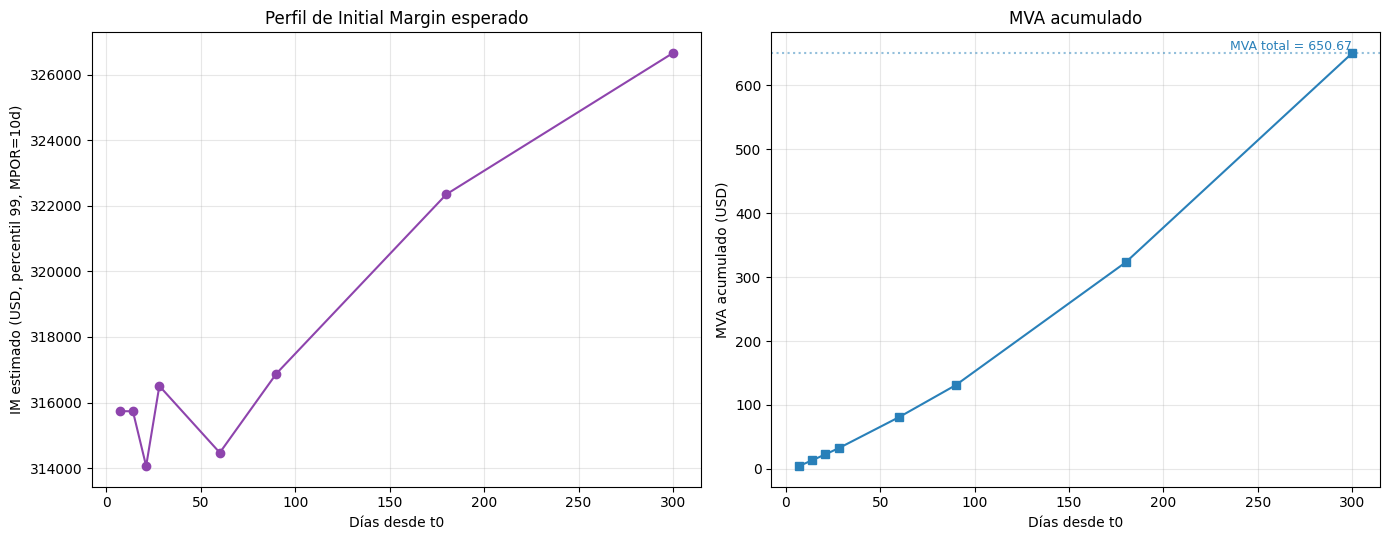

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo diario (necesario para estimar IM via MPOR rodante)
# ============================================================
def simulate_fx_paths_daily(S0, r_dom, r_for, sigma, T, n_paths=100_000, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    n_days = int(round(T * 365))
    dt = T / n_days

    S = np.full(n_paths, S0, dtype=float)
    S_path = np.empty((n_paths, n_days + 1))
    S_path[:, 0] = S0
    for i in range(1, n_days + 1):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
        S_path[:, i] = S

    day_grid = np.arange(n_days + 1) * dt
    return day_grid, S_path


def mtm_fx_forward(S_path, K, r_dom, r_for, T, day_grid, N):
    tau = np.clip(T - day_grid, 0, None)
    return N * (S_path * np.exp(-r_for * tau) - K * np.exp(-r_dom * tau))


# ============================================================
# 2. Estimar IM(t) -- percentil 99 del movimiento absoluto del MtM
#    en una ventana MPOR hacia adelante, condicional a estar en t
# ============================================================
def estimate_im_profile(V_full, day_grid, coarse_grid, mpor_days=10, pct=99):
    """
    IM(t_i) = percentil_99 [ |V(t_i + MPOR) - V(t_i)| ]
    Estimado directamente de las trayectorias ya simuladas: para cada nodo
    del grid, se compara el MtM en ese día contra el MtM 'mpor_days' después,
    en la MISMA trayectoria (par natural, sin necesidad de resimular).
    """
    n_days = V_full.shape[1]
    day_idx = np.array([np.argmin(np.abs(day_grid - t)) for t in coarse_grid])

    im = np.empty(len(coarse_grid))
    for k, idx in enumerate(day_idx):
        idx_fwd = min(idx + mpor_days, n_days - 1)   # no te pases del final del trade
        delta_V = V_full[:, idx_fwd] - V_full[:, idx]
        im[k] = np.percentile(np.abs(delta_V), pct)

    return im


# ============================================================
# 3. Curva de funding y cálculo de MVA (misma cuadratura que FCA/FBA)
# ============================================================
def calibrate_funding_curve(tenors, spreads_bps):
    tenors = np.asarray(tenors, float)
    spreads = np.asarray(spreads_bps, float) / 10_000.0
    interp = PchipInterpolator(tenors, spreads, extrapolate=True)
    return lambda t: interp(np.asarray(t, float))


def compute_mva(time_grid, im_profile, sf_func, r):
    t = np.concatenate(([0.0], time_grid))
    dt = np.diff(t)
    sf = sf_func(time_grid)
    DF = np.exp(-r * time_grid)

    im_ext = np.concatenate(([0.0], im_profile))          # IM(0) = 0 (recién se abre el trade)
    im_avg = 0.5 * (im_ext[:-1] + im_ext[1:])              # trapecio, igual que en FCA/FBA

    contrib = sf * im_avg * DF * dt
    return contrib.sum(), contrib


# ================= Setup: mismo FX forward de siempre =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

MPOR_DAYS = 10   # horizonte de riesgo estándar (SIMM / Basel)

day_grid, S_path = simulate_fx_paths_daily(
    S0=S0, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T,
    n_paths=100_000, seed=1
)
V_full = mtm_fx_forward(S_path, K, r_dom=r_usd, r_for=r_eur, T=T, day_grid=day_grid, N=N_EUR)

# Grid hasta 300 días (no 365): se necesita margen de MPOR hacia adelante
# para poder medir el movimiento a 10 días desde el último nodo
coarse_grid = np.array([7, 14, 21, 28, 60, 90, 180, 300]) / 365

im_profile = estimate_im_profile(V_full, day_grid, coarse_grid, mpor_days=MPOR_DAYS, pct=99)

# --- Curva de funding propio (misma que usamos para FVA) ---
funding_tenors  = [0.5, 1, 2, 3, 5]
funding_spreads = [25, 35, 50, 65, 85]     # bps sobre risk-free
sf_func = calibrate_funding_curve(funding_tenors, funding_spreads)

mva, contrib_mva = compute_mva(coarse_grid, im_profile, sf_func, r=r_usd)

print(f"Spot EUR/USD: {S0:.4f}  |  Notional: {N_EUR:,.0f} EUR  |  MPOR: {MPOR_DAYS} días")
print(f"\nIM(t) estimado (percentil 99, USD): {np.round(im_profile, 2)}")
print(f"Funding spread por nodo (bps): {np.round(sf_func(coarse_grid)*10000, 2)}")
print(f"\nContribución MVA por nodo: {np.round(contrib_mva, 4)}")
print(f"\nMVA total: {mva:,.4f} USD")


# ============================================================
# 4. Plot: perfil de IM y MVA acumulado
# ============================================================
days_plot = coarse_grid * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(days_plot, im_profile, 'o-', color='#8e44ad')
axes[0].set_xlabel('Días desde t0')
axes[0].set_ylabel('IM estimado (USD, percentil 99, MPOR=10d)')
axes[0].set_title('Perfil de Initial Margin esperado')
axes[0].grid(alpha=0.3)

mva_cum = np.cumsum(contrib_mva)
axes[1].plot(days_plot, mva_cum, 's-', color='#2980b9')
axes[1].axhline(mva, color='#2980b9', linestyle=':', alpha=0.5)
axes[1].text(days_plot[-1], mva, f'  MVA total = {mva:.2f}', va='bottom', ha='right',
             color='#2980b9', fontsize=9)
axes[1].set_xlabel('Días desde t0')
axes[1].set_ylabel('MVA acumulado (USD)')
axes[1].set_title('MVA acumulado')
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## ColVA

Spot EUR/USD: 1.1622  |  Notional: 8,604,371 EUR  |  MTA: $20,000

E[C(t)] -- balance de colateral esperado, con signo (USD):
[-352.17 -152.03  604.85  940.98 1569.91 2239.18 2046.39 3562.96]

Basis de remuneración (bps): [5. 5. 5. 5. 5. 5. 5. 5.]

Contribución ColVA por nodo: [-0.0017 -0.0024  0.0022  0.0074  0.0598  0.0723  0.262   0.6726]

ColVA total: 1.0721 USD


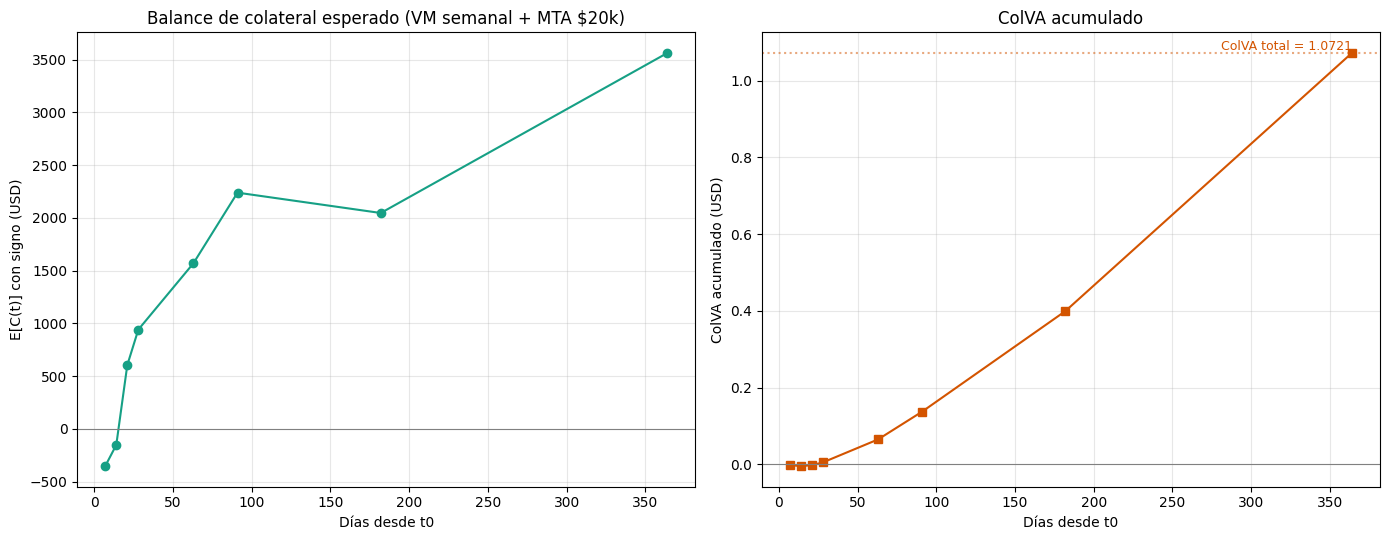

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo diario (igual que en el ejercicio de VM)
# ============================================================
def simulate_fx_paths_daily(S0, r_dom, r_for, sigma, T, n_paths=100_000, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    n_days = int(round(T * 365))
    dt = T / n_days

    S = np.full(n_paths, S0, dtype=float)
    S_path = np.empty((n_paths, n_days + 1))
    S_path[:, 0] = S0
    for i in range(1, n_days + 1):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
        S_path[:, i] = S

    day_grid = np.arange(n_days + 1) * dt
    return day_grid, S_path


def mtm_fx_forward(S_path, K, r_dom, r_for, T, day_grid, N):
    tau = np.clip(T - day_grid, 0, None)
    return N * (S_path * np.exp(-r_for * tau) - K * np.exp(-r_dom * tau))


# ============================================================
# 2. Variation Margin semanal con MTA -- devuelve también el
#    balance de colateral C(t) por path (input directo del ColVA)
# ============================================================
def apply_variation_margin_mta(V, day_grid, freq_days, mta):
    n_paths, n_days = V.shape
    call_dates = np.arange(0, n_days, freq_days)

    C = np.zeros(n_paths)
    V_net = np.empty_like(V)
    C_full = np.empty_like(V)          # balance de colateral vigente, día a día

    V_net[:, 0] = V[:, 0] - C
    C_full[:, 0] = C

    prev_idx = 0
    for call_idx in call_dates[1:]:
        V_net[:, prev_idx:call_idx] = V[:, prev_idx:call_idx] - C[:, None]
        C_full[:, prev_idx:call_idx] = C[:, None]

        gap = V[:, call_idx] - C
        transfer = np.abs(gap) > mta
        C = np.where(transfer, V[:, call_idx], C)

        prev_idx = call_idx

    V_net[:, prev_idx:] = V[:, prev_idx:] - C[:, None]
    C_full[:, prev_idx:] = C[:, None]

    return V_net, C_full


# ============================================================
# 3. Curva de basis de remuneración de colateral, y cálculo de ColVA
#    (misma cuadratura trapezoidal que FCA/FBA/MVA)
# ============================================================
def calibrate_basis_curve(tenors, basis_bps):
    tenors = np.asarray(tenors, float)
    basis = np.asarray(basis_bps, float) / 10_000.0
    interp = PchipInterpolator(tenors, basis, extrapolate=True)
    return lambda t: interp(np.asarray(t, float))


def compute_colva(time_grid, C_avg_profile, sc_func, r):
    t = np.concatenate(([0.0], time_grid))
    dt = np.diff(t)
    sc = sc_func(time_grid)
    DF = np.exp(-r * time_grid)

    C_ext = np.concatenate(([0.0], C_avg_profile))
    C_avg = 0.5 * (C_ext[:-1] + C_ext[1:])         # trapecio, CON signo (no valor absoluto)

    contrib = sc * C_avg * DF * dt
    return contrib.sum(), contrib


# ================= Setup: mismo FX forward, mismo VM que antes =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
MTA = 20_000.0

K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

day_grid, S_path = simulate_fx_paths_daily(
    S0=S0, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T, n_paths=100_000, seed=1
)
V_full = mtm_fx_forward(S_path, K, r_dom=r_usd, r_for=r_eur, T=T, day_grid=day_grid, N=N_EUR)

V_net, C_full = apply_variation_margin_mta(V_full, day_grid, freq_days=7, mta=MTA)

# --- Grid alineado a múltiplos de 7 (igual que en el ejercicio de VM) ---
coarse_grid = np.array([7, 14, 21, 28, 63, 91, 182, 364]) / 365
day_idx = np.array([np.argmin(np.abs(day_grid - t)) for t in coarse_grid])

C_avg_profile = C_full[:, day_idx].mean(axis=0)    # E[C(t)] en cada nodo, CON signo

# --- Basis de remuneración de colateral (r_d - r_c). ILUSTRATIVO: 5 bps,
#     típico de la diferencia SOFR vs Fed Funds Effective, o de un CSA
#     que remunera a un índice ligeramente distinto de tu curva de descuento.
#     Reemplazar con el basis real del CSA si está disponible. ---
basis_tenors = [0.5, 1, 2, 3, 5]
basis_bps    = [5, 5, 5, 5, 5]      # flat, simplificación
sc_func = calibrate_basis_curve(basis_tenors, basis_bps)

colva, contrib_colva = compute_colva(coarse_grid, C_avg_profile, sc_func, r=r_usd)

print(f"Spot EUR/USD: {S0:.4f}  |  Notional: {N_EUR:,.0f} EUR  |  MTA: ${MTA:,.0f}")
print(f"\nE[C(t)] -- balance de colateral esperado, con signo (USD):")
print(np.round(C_avg_profile, 2))
print(f"\nBasis de remuneración (bps): {np.round(sc_func(coarse_grid)*10000, 2)}")
print(f"\nContribución ColVA por nodo: {np.round(contrib_colva, 4)}")
print(f"\nColVA total: {colva:,.4f} USD")


# ============================================================
# 4. Plot: balance de colateral esperado y ColVA acumulado
# ============================================================
days_plot = coarse_grid * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(days_plot, C_avg_profile, 'o-', color='#16a085')
axes[0].axhline(0, color='gray', linewidth=0.8)
axes[0].set_xlabel('Días desde t0')
axes[0].set_ylabel('E[C(t)] con signo (USD)')
axes[0].set_title('Balance de colateral esperado (VM semanal + MTA $20k)')
axes[0].grid(alpha=0.3)

colva_cum = np.cumsum(contrib_colva)
axes[1].plot(days_plot, colva_cum, 's-', color='#d35400')
axes[1].axhline(colva, color='#d35400', linestyle=':', alpha=0.5)
axes[1].axhline(0, color='gray', linewidth=0.8)
axes[1].text(days_plot[-1], colva, f'  ColVA total = {colva:.4f}', va='bottom', ha='right',
             color='#d35400', fontsize=9)
axes[1].set_xlabel('Días desde t0')
axes[1].set_ylabel('ColVA acumulado (USD)')
axes[1].set_title('ColVA acumulado')
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## KVA para 1 FX Forward

Spot EUR/USD: 1.1622  |  Notional: 8,604,371 EUR

EPE (USD): [ 40683.63  57480.79  70300.9   81481.23 119941.84 147489.8  211120.53
 306377.64]
EAD (USD): [ 56957.09  80473.11  98421.26 114073.72 167918.57 206485.72 295568.75
 428928.7 ]
K(t) -- capital regulatorio (USD): [ 5980.49  8449.68 10334.23 11977.74 17631.45 21681.   31034.72 45037.51]

Contribución KVA por nodo: [   5.7304   13.8165   17.9716   21.3311  128.9643  160.0118  637.5394
 1854.1187]

KVA total: 2,839.4839 USD


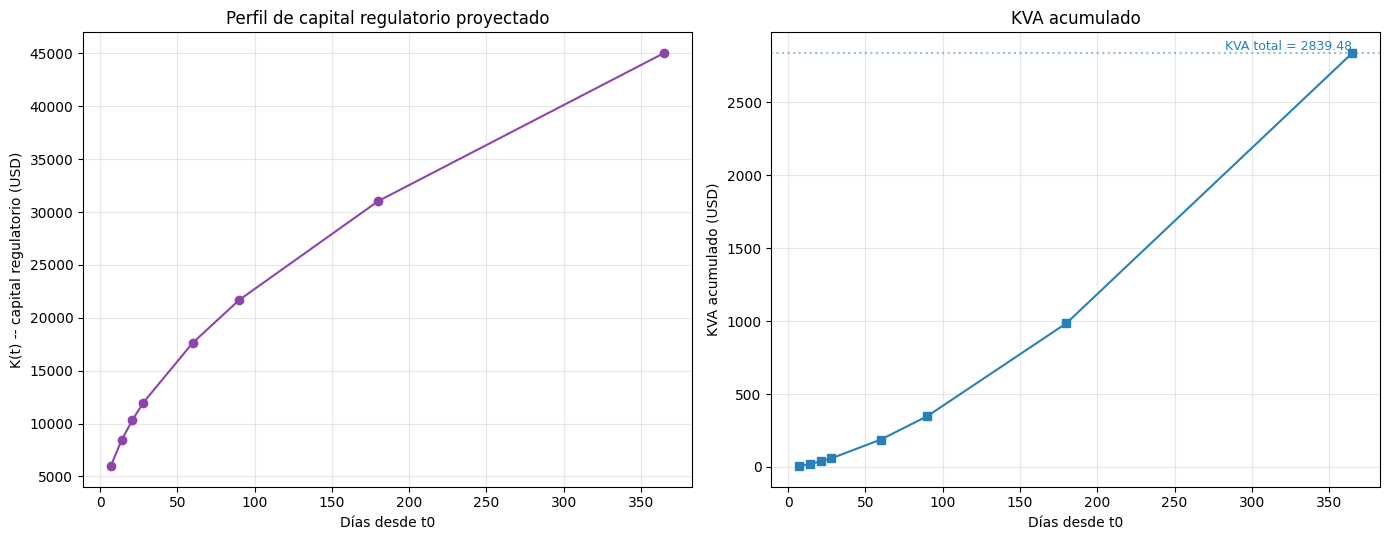

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Motor Monte Carlo -- FX forward EUR/USD (mismo de siempre)
# ============================================================
def exposure_fx_forward(S0, K, r_dom, r_for, sigma, T, time_grid, N,
                         n_paths=100_000, pct=99, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    time_grid = np.sort(np.asarray(time_grid, float))
    dt = np.diff(np.concatenate(([0.0], time_grid)))

    S = np.full(n_paths, S0, dtype=float)
    pfe = np.empty(len(time_grid))
    epe = np.empty(len(time_grid))

    for i, step in enumerate(dt):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*step + sigma*np.sqrt(step)*Z)
        V = N * (S*np.exp(-r_for*(T - time_grid[i])) - K*np.exp(-r_dom*(T - time_grid[i])))
        exposure = np.maximum(V, 0.0)
        pfe[i] = np.percentile(exposure, pct)
        epe[i] = exposure.mean()

    return time_grid, pfe, epe


# ============================================================
# 2. Capital regulatorio proyectado K(t) a partir del EPE
#    (EAD = alpha * EPE, misma lógica de Basel IMM usada en la sesión de EPE)
# ============================================================
def capital_profile(epe, alpha=1.4, risk_weight=1.0, capital_ratio=0.105):
    """
    EAD(t) = alpha * EPE(t)         (Basel IMM, alpha regulatorio ~1.4)
    K(t)   = capital_ratio * RW * EAD(t)
    """
    ead = alpha * epe
    K = capital_ratio * risk_weight * ead
    return K, ead


# ============================================================
# 3. KVA -- misma cuadratura trapezoidal que FCA/FBA/MVA/ColVA
# ============================================================
def compute_kva(time_grid, K_profile, hurdle_rate, r):
    t = np.concatenate(([0.0], time_grid))
    dt = np.diff(t)
    DF = np.exp(-r * time_grid)

    K_ext = np.concatenate(([0.0], K_profile))
    K_avg = 0.5 * (K_ext[:-1] + K_ext[1:])        # trapecio

    contrib = hurdle_rate * K_avg * DF * dt
    return contrib.sum(), contrib


# ================= Setup: mismo FX forward de siempre =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
K_strike = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

grid = np.array([7, 14, 21, 28, 60, 90, 180, 365]) / 365

t, pfe, epe = exposure_fx_forward(
    S0=S0, K=K_strike, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T,
    time_grid=grid, N=N_EUR, n_paths=200_000, seed=42
)

# --- Parámetros de capital regulatorio (ILUSTRATIVOS, ajustar a tu marco real) ---
ALPHA = 1.4              # multiplicador regulatorio Basel IMM (EAD = alpha * EPE)
RISK_WEIGHT = 1.00        # 100% -- ilustrativo para contraparte corporativa IG
CAPITAL_RATIO = 0.105     # 10.5% -- CET1 + buffers (Basel III, ilustrativo)
HURDLE_RATE = 0.10        # 10% anual -- spread de retorno objetivo sobre el capital

K_profile, ead_profile = capital_profile(epe, alpha=ALPHA, risk_weight=RISK_WEIGHT,
                                          capital_ratio=CAPITAL_RATIO)

kva, contrib_kva = compute_kva(t, K_profile, hurdle_rate=HURDLE_RATE, r=r_usd)

print(f"Spot EUR/USD: {S0:.4f}  |  Notional: {N_EUR:,.0f} EUR")
print(f"\nEPE (USD): {np.round(epe, 2)}")
print(f"EAD (USD): {np.round(ead_profile, 2)}")
print(f"K(t) -- capital regulatorio (USD): {np.round(K_profile, 2)}")
print(f"\nContribución KVA por nodo: {np.round(contrib_kva, 4)}")
print(f"\nKVA total: {kva:,.4f} USD")


# ============================================================
# 4. Plot: perfil de capital K(t) y KVA acumulado
# ============================================================
days = t * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(days, K_profile, 'o-', color='#8e44ad')
axes[0].set_xlabel('Días desde t0')
axes[0].set_ylabel('K(t) -- capital regulatorio (USD)')
axes[0].set_title('Perfil de capital regulatorio proyectado')
axes[0].grid(alpha=0.3)

kva_cum = np.cumsum(contrib_kva)
axes[1].plot(days, kva_cum, 's-', color='#2980b9')
axes[1].axhline(kva, color='#2980b9', linestyle=':', alpha=0.5)
axes[1].text(days[-1], kva, f'  KVA total = {kva:.2f}', va='bottom', ha='right',
             color='#2980b9', fontsize=9)
axes[1].set_xlabel('Días desde t0')
axes[1].set_ylabel('KVA acumulado (USD)')
axes[1].set_title('KVA acumulado')
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

EE(t) cruda (USD):         [ 95850.52 135893.78 192001.74 234994.11 271819.56 304990.81 329612.72
 336250.62 209952.28 214184.08 225368.18 241994.19 257883.33 272612.54
 285955.5  302355.18]
Effective EE(t) (USD):     [ 95850.52 135893.78 192001.74 234994.11 271819.56 304990.81 329612.72
 336250.62 336250.62 336250.62 336250.62 336250.62 336250.62 336250.62
 336250.62 336250.62]

CVA (usa EE cruda):                  1,449.12 USD
KVA si (incorrectamente) usara EE cruda: 3,447.72 USD
KVA correcto (usa Effective EE):         4,004.96 USD
Diferencia por el piso regulatorio:       557.23 USD


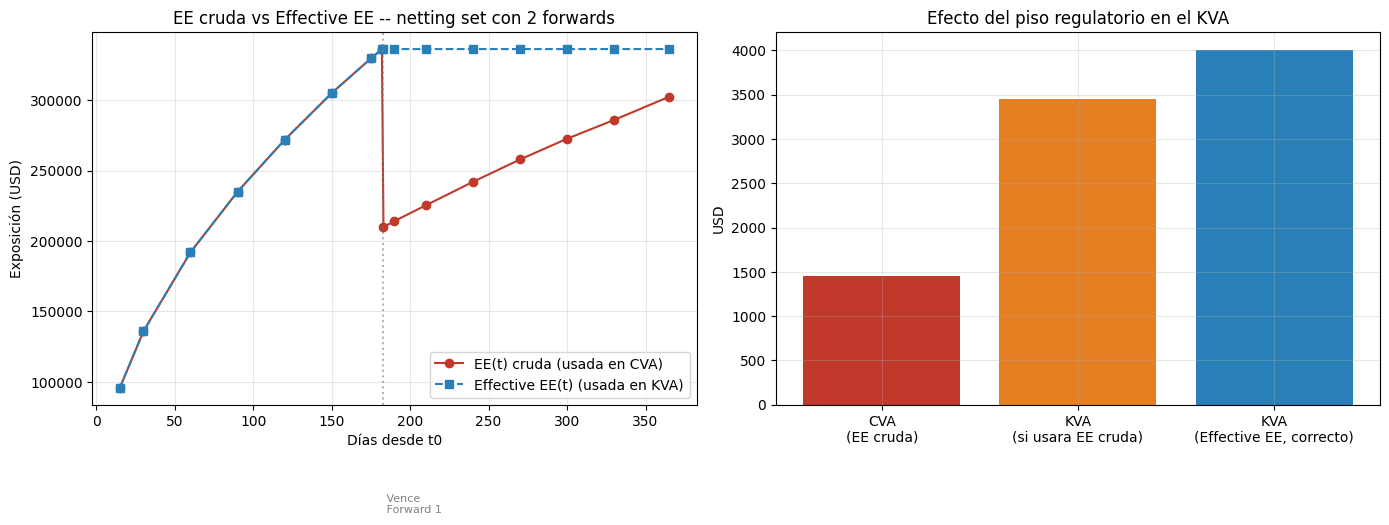

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.interpolate import PchipInterpolator

# ============================================================
# 1. Motor Monte Carlo diario -- un solo spot compartido por ambos forwards
# ============================================================
def simulate_fx_paths_daily(S0, r_dom, r_for, sigma, T, n_paths=100_000, mu=None, seed=1):
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for if mu is None else mu
    n_days = int(round(T * 365))
    dt = T / n_days

    S = np.full(n_paths, S0, dtype=float)
    S_path = np.empty((n_paths, n_days + 1))
    S_path[:, 0] = S0
    for i in range(1, n_days + 1):
        Z = rng.standard_normal(n_paths)
        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z)
        S_path[:, i] = S

    day_grid = np.arange(n_days + 1) * dt
    return day_grid, S_path


def mtm_fx_forward(S_path, K, r_dom, r_for, T_mat, day_grid, N):
    """MTM de un forward individual; 0 después de su propio vencimiento T_mat."""
    tau = T_mat - day_grid
    active = tau >= 0
    tau_clip = np.clip(tau, 0, None)
    V = N * (S_path * np.exp(-r_for * tau_clip) - K * np.exp(-r_dom * tau_clip))
    V = V * active[None, :]     # 0 tras el vencimiento de ESTE forward específico
    return V


# ============================================================
# 2. Curva de supervivencia (misma de siempre)
# ============================================================
def calibrate_survival_curve_piecewise(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    tenors_ext = np.concatenate(([0.0], tenors))

    def Q(t):
        t = np.atleast_1d(np.asarray(t, float))
        out = np.empty_like(t)
        for i, tt in enumerate(t):
            idx = np.searchsorted(tenors_ext, tt, side='right') - 1
            idx = np.clip(idx, 0, len(lam_cum) - 1)
            lam_prev = lam_cum[idx - 1] if idx > 0 else 0.0
            t_prev = tenors_ext[idx]
            lam_here = lam_cum[idx]
            cum_hazard = lam_prev * t_prev + lam_here * (tt - t_prev)
            out[i] = np.exp(-cum_hazard)
        return out
    return Q


def compute_cva(time_grid, epe, Q_func, r, RR=0.25):
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r * time_grid)
    epe_ext = np.concatenate(([0.0], epe))
    epe_avg = 0.5 * (epe_ext[:-1] + epe_ext[1:])
    contrib = (1 - RR) * epe_avg * dPD * DF
    return contrib.sum(), contrib


def compute_kva(time_grid, K_profile, hurdle_rate, r):
    t = np.concatenate(([0.0], time_grid))
    dt = np.diff(t)
    DF = np.exp(-r * time_grid)
    K_ext = np.concatenate(([0.0], K_profile))
    K_avg = 0.5 * (K_ext[:-1] + K_ext[1:])
    contrib = hurdle_rate * K_avg * DF * dt
    return contrib.sum(), contrib


# ================= Setup: netting set con DOS forwards de distinto vencimiento =================
S0, r_usd, r_eur, sigma_fx = 1.1622, 0.039, 0.020, 0.075
T_total = 1.0
T1, T2 = 0.5, 1.0                      # vencimientos de cada forward

notional1_usd, notional2_usd = 6_000_000.0, 10_000_000.0
K1 = S0 * np.exp((r_usd - r_eur) * T1)  # ATM propio de cada forward
K2 = S0 * np.exp((r_usd - r_eur) * T2)
N1_EUR = notional1_usd / S0
N2_EUR = notional2_usd / S0

day_grid, S_path = simulate_fx_paths_daily(
    S0=S0, r_dom=r_usd, r_for=r_eur, sigma=sigma_fx, T=T_total, n_paths=150_000, seed=7
)

V1 = mtm_fx_forward(S_path, K1, r_usd, r_eur, T1, day_grid, N1_EUR)
V2 = mtm_fx_forward(S_path, K2, r_usd, r_eur, T2, day_grid, N2_EUR)
V_netting = V1 + V2                     # netting: se suman los MtM de ambos trades

# --- Grid fino, con nodos justo antes y justo después de T1 (182 y 183 días) ---
grid_days = np.array([15, 30, 60, 90, 120, 150, 175, 182, 183, 190, 210,
                       240, 270, 300, 330, 365])
coarse_grid = grid_days / 365
day_idx = np.array([np.argmin(np.abs(day_grid - t)) for t in coarse_grid])

exposure = np.maximum(V_netting[:, day_idx], 0.0)
EE = exposure.mean(axis=0)                       # EE(t) cruda -- puede bajar
Effective_EE = np.maximum.accumulate(EE)          # Effective EE: máximo acumulado

print("EE(t) cruda (USD):        ", np.round(EE, 2))
print("Effective EE(t) (USD):    ", np.round(Effective_EE, 2))


# --- Curva de crédito de la contraparte (misma de siempre) ---
cds_tenors  = np.array([0.5, 1, 2, 3, 5])
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])
RR = 0.25
Q_func = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)

# --- CVA: usa la EE cruda (refleja la caída real de exposición) ---
cva, contrib_cva = compute_cva(coarse_grid, EE, Q_func, r=r_usd, RR=RR)

# --- KVA: usa la Effective EE (piso regulatorio conservador, no baja) ---
ALPHA, RW, CAPITAL_RATIO, HURDLE = 1.4, 1.0, 0.105, 0.10
K_from_raw_EE       = CAPITAL_RATIO * RW * ALPHA * EE
K_from_effective_EE = CAPITAL_RATIO * RW * ALPHA * Effective_EE

kva_raw, _        = compute_kva(coarse_grid, K_from_raw_EE, HURDLE, r=r_usd)
kva_effective, _  = compute_kva(coarse_grid, K_from_effective_EE, HURDLE, r=r_usd)

print(f"\nCVA (usa EE cruda):                  {cva:,.2f} USD")
print(f"KVA si (incorrectamente) usara EE cruda: {kva_raw:,.2f} USD")
print(f"KVA correcto (usa Effective EE):         {kva_effective:,.2f} USD")
print(f"Diferencia por el piso regulatorio:       {kva_effective - kva_raw:,.2f} USD")


# ============================================================
# 3. Plots
# ============================================================
days_plot = coarse_grid * 365

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

axes[0].plot(days_plot, EE, 'o-', color='#c0392b', label='EE(t) cruda (usada en CVA)')
axes[0].plot(days_plot, Effective_EE, 's--', color='#2980b9', label='Effective EE(t) (usada en KVA)')
axes[0].axvline(T1*365, color='gray', linestyle=':', alpha=0.6)
axes[0].text(T1*365, axes[0].get_ylim()[1]*0.02, ' Vence\n Forward 1', fontsize=8, color='gray')
axes[0].set_xlabel('Días desde t0')
axes[0].set_ylabel('Exposición (USD)')
axes[0].set_title('EE cruda vs Effective EE -- netting set con 2 forwards')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(['CVA\n(EE cruda)'], [cva], color='#c0392b')
axes[1].bar(['KVA\n(si usara EE cruda)'], [kva_raw], color='#e67e22')
axes[1].bar(['KVA\n(Effective EE, correcto)'], [kva_effective], color='#2980b9')
axes[1].set_ylabel('USD')
axes[1].set_title('Efecto del piso regulatorio en el KVA')
axes[1].grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Wrong Way Risk

Spot EUR/USD: 1.1622  |  Notional: 8,604,371 EUR  |  hazard base: 0.0080
rho = -0.7  ->  CVA = 493.33 USD   |   P(default) = 0.7845%
rho = +0.0  ->  CVA = 1,129.62 USD   |   P(default) = 0.7930%
rho = +0.7  ->  CVA = 2,075.95 USD   |   P(default) = 0.8020%

CVA con WWR (rho=+0.7) vs independiente: +946.34 USD (+83.8%)
CVA con RWR (rho=-0.7) vs independiente: -636.28 USD (-56.3%)


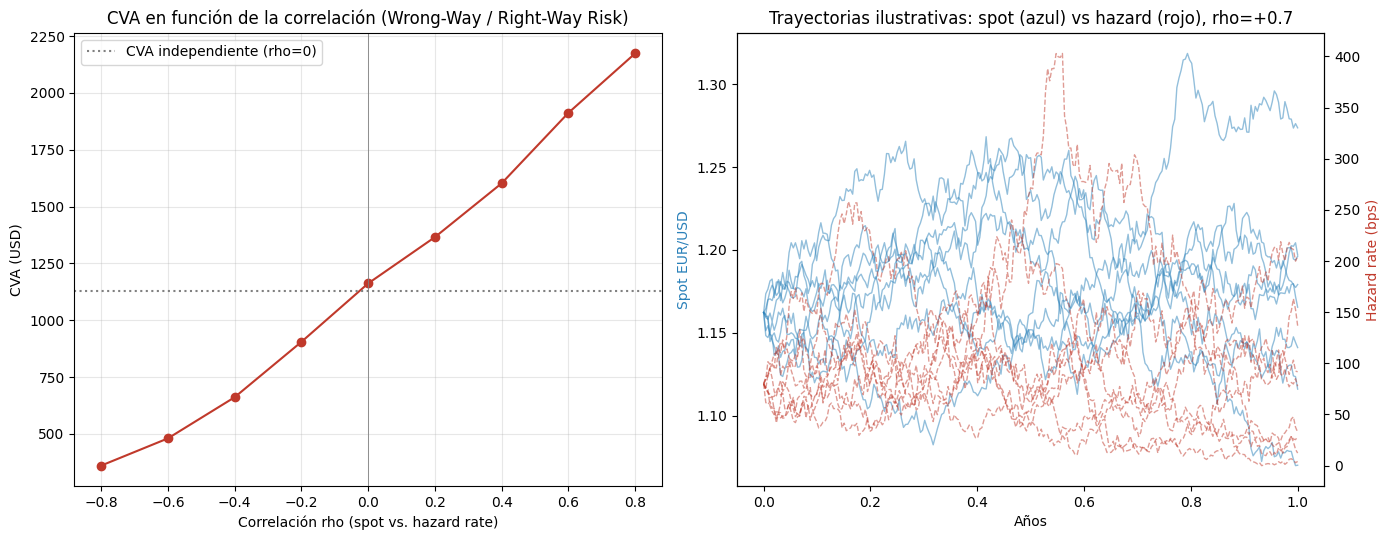

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Simulación conjunta: spot (GBM) + hazard rate (CIR) correlacionados
# ============================================================
def simulate_wwr_paths(S0, r_dom, r_for, sigma, lam0, a, b, sigma_lam, rho,
                        T, n_paths=100_000, n_steps=252, seed=1):
    """
    dS      = mu*S*dt + sigma*S*dW_S
    dlambda = a*(b - lambda)*dt + sigma_lam*sqrt(lambda)*dW_lambda
    dW_lambda = rho*dW_S + sqrt(1-rho^2)*dW_perp     <- correlación = WWR
    """
    rng = np.random.default_rng(seed)
    mu = r_dom - r_for
    dt = T / n_steps

    S = np.full(n_paths, S0, dtype=float)
    lam = np.full(n_paths, lam0, dtype=float)
    H = np.zeros(n_paths)                    # hazard acumulado (integral de lambda)

    S_path = np.empty((n_paths, n_steps + 1)); S_path[:, 0] = S0
    lam_path = np.empty((n_paths, n_steps + 1)); lam_path[:, 0] = lam0
    H_path = np.empty((n_paths, n_steps + 1)); H_path[:, 0] = 0.0

    for i in range(1, n_steps + 1):
        Z_S = rng.standard_normal(n_paths)
        Z_perp = rng.standard_normal(n_paths)
        Z_lam = rho * Z_S + np.sqrt(1 - rho**2) * Z_perp     # <- correlación aplicada aquí

        S *= np.exp((mu - 0.5*sigma**2)*dt + sigma*np.sqrt(dt)*Z_S)

        lam_pos = np.maximum(lam, 0.0)                        # full truncation CIR
        lam = lam + a*(b - lam_pos)*dt + sigma_lam*np.sqrt(lam_pos*dt)*Z_lam
        lam = np.maximum(lam, 0.0)

        H += lam_pos * dt

        S_path[:, i] = S
        lam_path[:, i] = lam
        H_path[:, i] = H

    time_grid = np.linspace(0, T, n_steps + 1)
    return time_grid, S_path, lam_path, H_path


def simulate_default_times(H_path, time_grid, seed=2):
    """Construcción de Cox process: default en el primer t donde H_t >= E ~ Exp(1)."""
    rng = np.random.default_rng(seed)
    n_paths = H_path.shape[0]
    E = rng.exponential(1.0, size=n_paths)

    default_idx = np.array([
        np.searchsorted(H_path[p, :], E[p], side='left') for p in range(n_paths)
    ])
    survived = default_idx >= H_path.shape[1]     # nunca cruzó H(T)

    tau = np.where(survived, np.inf, time_grid[np.clip(default_idx, 0, len(time_grid)-1)])
    return tau, survived


# ============================================================
# 2. CVA por Monte Carlo directo (necesario con hazard estocástico)
# ============================================================
def mtm_fx_forward_at(S_vals, K, r_dom, r_for, T, t_vals, N):
    tau_rem = np.clip(T - t_vals, 0, None)
    return N * (S_vals * np.exp(-r_for * tau_rem) - K * np.exp(-r_dom * tau_rem))


def compute_cva_mc(time_grid, S_path, tau, survived, K, r_dom, r_for, T, N, RR=0.25):
    n_paths = S_path.shape[0]
    tau_idx = np.array([
        np.argmin(np.abs(time_grid - tt)) if np.isfinite(tt) else -1
        for tt in tau
    ])

    losses = np.zeros(n_paths)
    defaulted = ~survived
    idx_def = tau_idx[defaulted]
    S_at_default = S_path[defaulted, idx_def]
    t_at_default = time_grid[idx_def]

    V_at_default = mtm_fx_forward_at(S_at_default, K, r_dom, r_for, T, t_at_default, N)
    exposure_at_default = np.maximum(V_at_default, 0.0)
    DF_at_default = np.exp(-r_dom * t_at_default)

    losses[defaulted] = (1 - RR) * exposure_at_default * DF_at_default
    cva = losses.mean()
    return cva, defaulted.mean()


# ================= Setup: mismo FX forward de siempre =================
S0, r_usd, r_eur, sigma_fx, T = 1.1622, 0.039, 0.020, 0.075, 1.0
notional_usd = 10_000_000.0
K = S0 * np.exp((r_usd - r_eur) * T)
N_EUR = notional_usd / S0

# --- Parámetros del hazard rate (CIR), calibrados a un spread base ~60bps ---
RR = 0.25
base_spread = 0.0060
lam0 = base_spread / (1 - RR)
a_meanrev = 1.5
b_longrun = lam0
sigma_lam = 0.15

N_PATHS = 200_000
N_STEPS = 252

print(f"Spot EUR/USD: {S0:.4f}  |  Notional: {N_EUR:,.0f} EUR  |  hazard base: {lam0:.4f}")

# --- Comparar CVA bajo distintos niveles de correlación (WWR) ---
rhos = [-0.7, 0.0, 0.7]
results = {}

for rho in rhos:
    t_grid, S_path, lam_path, H_path = simulate_wwr_paths(
        S0, r_usd, r_eur, sigma_fx, lam0, a_meanrev, b_longrun, sigma_lam, rho,
        T, n_paths=N_PATHS, n_steps=N_STEPS, seed=1
    )
    tau, survived = simulate_default_times(H_path, t_grid, seed=2)
    cva, default_prob = compute_cva_mc(t_grid, S_path, tau, survived, K, r_usd, r_eur, T, N_EUR, RR=RR)
    results[rho] = (cva, default_prob)
    print(f"rho = {rho:+.1f}  ->  CVA = {cva:,.2f} USD   |   P(default) = {default_prob:.4%}")

cva_independent = results[0.0][0]
print(f"\nCVA con WWR (rho=+0.7) vs independiente: {results[0.7][0] - cva_independent:+,.2f} USD "
      f"({(results[0.7][0]/cva_independent - 1)*100:+.1f}%)")
print(f"CVA con RWR (rho=-0.7) vs independiente: {results[-0.7][0] - cva_independent:+,.2f} USD "
      f"({(results[-0.7][0]/cva_independent - 1)*100:+.1f}%)")


# ============================================================
# 3. Plot: CVA vs rho, y trayectorias ilustrativas de spot/hazard correlacionados
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

rho_fine = np.linspace(-0.8, 0.8, 9)
cva_fine = []
for rho in rho_fine:
    t_grid, S_path, lam_path, H_path = simulate_wwr_paths(
        S0, r_usd, r_eur, sigma_fx, lam0, a_meanrev, b_longrun, sigma_lam, rho,
        T, n_paths=100_000, n_steps=N_STEPS, seed=1
    )
    tau, survived = simulate_default_times(H_path, t_grid, seed=2)
    cva_r, _ = compute_cva_mc(t_grid, S_path, tau, survived, K, r_usd, r_eur, T, N_EUR, RR=RR)
    cva_fine.append(cva_r)

axes[0].plot(rho_fine, cva_fine, 'o-', color='#c0392b')
axes[0].axhline(cva_independent, color='gray', linestyle=':', label='CVA independiente (rho=0)')
axes[0].axvline(0, color='gray', linewidth=0.6)
axes[0].set_xlabel('Correlación rho (spot vs. hazard rate)')
axes[0].set_ylabel('CVA (USD)')
axes[0].set_title('CVA en función de la correlación (Wrong-Way / Right-Way Risk)')
axes[0].legend()
axes[0].grid(alpha=0.3)

# --- Panel derecho: un puñado de trayectorias de spot y hazard, rho=+0.7 ---
t_grid, S_path, lam_path, H_path = simulate_wwr_paths(
    S0, r_usd, r_eur, sigma_fx, lam0, a_meanrev, b_longrun, sigma_lam, 0.7,
    T, n_paths=8, n_steps=N_STEPS, seed=3
)
ax2 = axes[1]
ax2b = ax2.twinx()
for p in range(8):
    ax2.plot(t_grid, S_path[p], color='#2980b9', alpha=0.5, linewidth=1)
    ax2b.plot(t_grid, lam_path[p]*10000, color='#c0392b', alpha=0.5, linewidth=1, linestyle='--')
ax2.set_xlabel('Años')
ax2.set_ylabel('Spot EUR/USD', color='#2980b9')
ax2b.set_ylabel('Hazard rate (bps)', color='#c0392b')
ax2.set_title('Trayectorias ilustrativas: spot (azul) vs hazard (rojo), rho=+0.7')

fig.tight_layout()
plt.show()

## Calibracion de HW-1F from scratch

Mean reversion (a):              0.001000
Sigma por bucket [0-1,1-2,2-5,5-10]Y (bps): [92.28 82.15 79.39 73.32]
Costo residual (SSE):            0.0000062334

Vol de mercado (bps):
 [[85 88 92 95]
 [80 83 87 90]
 [75 78 82 85]
 [70 73 77 80]]

Vol del modelo (sigma piecewise) (bps):
 [[94.19 94.14 94.01 93.9 ]
 [89.17 89.13 89.02 88.9 ]
 [84.25 84.2  84.08 83.88]
 [79.35 79.3  79.15 78.85]]

Error (bps):
 [[ 9.19  6.14  2.01 -1.1 ]
 [ 9.17  6.13  2.02 -1.1 ]
 [ 9.25  6.2   2.08 -1.12]
 [ 9.35  6.3   2.15 -1.15]]


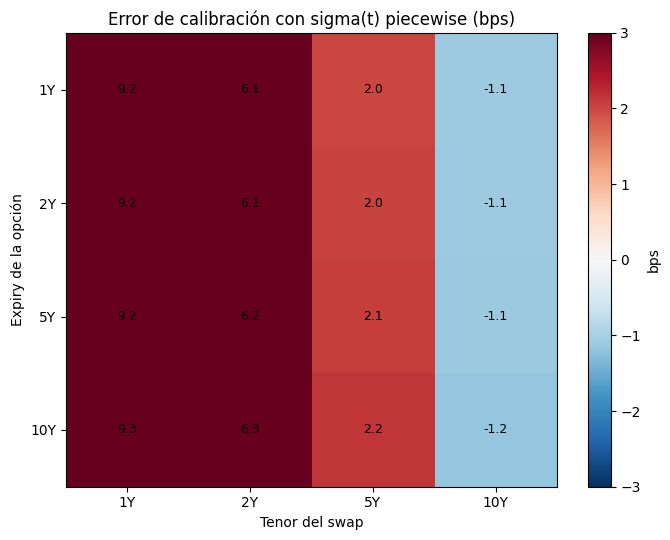

In [ ]:
import numpy as np
from scipy.stats import norm
from scipy.optimize import least_squares, brentq
from scipy.integrate import quad
import matplotlib.pyplot as plt

# ============================================================
# 1. Curva cero-cupón sintética (Nelson-Siegel) -- USD
# ============================================================
def nelson_siegel(t, beta0, beta1, beta2, tau):
    t = np.asarray(t, float)
    t_safe = np.where(t == 0, 1e-6, t)
    term1 = beta0
    term2 = beta1 * (1 - np.exp(-t_safe/tau)) / (t_safe/tau)
    term3 = beta2 * ((1 - np.exp(-t_safe/tau)) / (t_safe/tau) - np.exp(-t_safe/tau))
    return term1 + term2 + term3

ns_params = dict(beta0=0.042, beta1=-0.004, beta2=0.010, tau=2.5)
def zero_rate(t): return nelson_siegel(t, **ns_params)
def P0(t):
    t = np.asarray(t, float)
    return np.exp(-zero_rate(t) * t)
def fwd_rate_inst(t, eps=1e-4):
    return -(np.log(P0(t+eps)) - np.log(P0(t-eps))) / (2*eps)


# ============================================================
# 2. Matriz sintética de vol normal (Bachelier) ATM de swaptions
# ============================================================
expiries = np.array([1, 2, 5, 10])
tenors   = np.array([1, 2, 5, 10])
vol_matrix_bps = np.array([
    [85, 88, 92, 95],
    [80, 83, 87, 90],
    [75, 78, 82, 85],
    [70, 73, 77, 80],
])
vol_matrix = vol_matrix_bps / 10_000.0

def swap_annuity_and_forward(T0, tenor, freq=0.5):
    pay_times = T0 + np.arange(freq, tenor + 1e-9, freq)
    DFs = P0(pay_times)
    annuity = freq * DFs.sum()
    fwd_swap_rate = (P0(T0) - P0(T0 + tenor)) / annuity
    return annuity, fwd_swap_rate, pay_times, DFs

def bachelier_atm_price(annuity, sigma_N, T0):
    return annuity * sigma_N * np.sqrt(T0) / np.sqrt(2*np.pi)

market_prices = np.empty((len(expiries), len(tenors)))
annuities = np.empty_like(market_prices)
for i, T0 in enumerate(expiries):
    for j, tenor in enumerate(tenors):
        ann, fwd, _, _ = swap_annuity_and_forward(T0, tenor)
        annuities[i, j] = ann
        market_prices[i, j] = bachelier_atm_price(ann, vol_matrix[i, j], T0)


# ============================================================
# 3. sigma(t) piecewise-constante, y la función de varianza I(t)
# ============================================================
sigma_breakpoints = np.array([0.0, 1.0, 2.0, 5.0, 10.0])   # buckets: [0,1],[1,2],[2,5],[5,10]

def sigma_of_t(t, sigma_values):
    """sigma(t): constante por tramos, según sigma_breakpoints."""
    idx = np.searchsorted(sigma_breakpoints, t, side='right') - 1
    idx = np.clip(idx, 0, len(sigma_values) - 1)
    return sigma_values[idx]

def I_function(t, a, sigma_values):
    """I(t) = integral_0^t sigma(s)^2 * exp(-2a(t-s)) ds -- integración numérica."""
    if t <= 1e-8:
        return 0.0
    integrand = lambda s: sigma_of_t(s, sigma_values)**2 * np.exp(-2*a*(t-s))
    val, _ = quad(integrand, 0, t, limit=100)
    return val


# ============================================================
# 4. HW1F con sigma(t): A(t,T), bono, y precio de swaption (Jamshidian)
# ============================================================
def B_hw(a, t, T):
    return (1 - np.exp(-a*(T-t))) / a

def A_hw_t(a, sigma_values, t, T):
    Bt = B_hw(a, t, T)
    I_t = I_function(t, a, sigma_values)
    return (P0(T)/P0(t)) * np.exp(Bt*fwd_rate_inst(t) - 0.5*I_t*Bt**2)

def P_hw_t(a, sigma_values, t, T, r):
    return A_hw_t(a, sigma_values, t, T) * np.exp(-B_hw(a, t, T) * r)

def find_r_star_t(a, sigma_values, T0, cashflow_times, cashflows):
    def f(r):
        return np.sum(cashflows * P_hw_t(a, sigma_values, T0, cashflow_times, r)) - 1.0
    return brentq(f, -0.5, 0.5)

def swaption_price_hw_t(a, sigma_values, T0, tenor, freq=0.5, notional=1.0, payer=True):
    pay_times = T0 + np.arange(freq, tenor + 1e-9, freq)
    _, fwd_swap_rate, _, _ = swap_annuity_and_forward(T0, tenor, freq)
    K = fwd_swap_rate

    cashflows = np.full(len(pay_times), K*freq)
    cashflows[-1] += 1.0

    r_star = find_r_star_t(a, sigma_values, T0, pay_times, cashflows)
    I_T0 = I_function(T0, a, sigma_values)     # misma I(t), evaluada en T0, reusada para todas las Ti

    total = 0.0
    for Ti, ci in zip(pay_times, cashflows):
        sigma_P = np.sqrt(I_T0) * B_hw(a, T0, Ti)
        Xi = P_hw_t(a, sigma_values, T0, Ti, r_star)
        h = (1/sigma_P) * np.log(P0(Ti)/(P0(T0)*Xi)) + sigma_P/2

        if payer:
            zbo = Xi*P0(T0)*norm.cdf(-h+sigma_P) - P0(Ti)*norm.cdf(-h)
        else:
            zbo = P0(Ti)*norm.cdf(h) - Xi*P0(T0)*norm.cdf(h-sigma_P)
        total += ci * zbo

    return notional * total


# ============================================================
# 5. Calibración: a (global) + 4 sigmas piecewise = 5 parámetros
# ============================================================
def residuals_t(params):
    a = params[0]
    sigma_values = params[1:]
    res = []
    for i, T0 in enumerate(expiries):
        for j, tenor in enumerate(tenors):
            model_price = swaption_price_hw_t(a, sigma_values, T0, tenor)
            res.append(model_price - market_prices[i, j])
    return np.array(res)

x0 = [0.03, 0.009, 0.009, 0.008, 0.008]
lb = [0.001] + [0.0005]*4
ub = [1.0]   + [0.05]*4

result_t = least_squares(residuals_t, x0, bounds=(lb, ub), method='trf')
a_cal_t = result_t.x[0]
sigma_cal_t = result_t.x[1:]

print(f"Mean reversion (a):              {a_cal_t:.6f}")
print(f"Sigma por bucket [0-1,1-2,2-5,5-10]Y (bps): {np.round(sigma_cal_t*10000, 2)}")
print(f"Costo residual (SSE):            {np.sum(result_t.fun**2):.10f}")

model_prices_t = np.empty_like(market_prices)
for i, T0 in enumerate(expiries):
    for j, tenor in enumerate(tenors):
        model_prices_t[i, j] = swaption_price_hw_t(a_cal_t, sigma_cal_t, T0, tenor)

def implied_normal_vol(price, annuity, T0):
    return price * np.sqrt(2*np.pi) / (annuity * np.sqrt(T0))

model_vols_bps_t = np.empty_like(vol_matrix_bps, dtype=float)
for i, T0 in enumerate(expiries):
    for j, tenor in enumerate(tenors):
        model_vols_bps_t[i, j] = implied_normal_vol(model_prices_t[i,j], annuities[i,j], T0) * 10000

print("\nVol de mercado (bps):\n", vol_matrix_bps)
print("\nVol del modelo (sigma piecewise) (bps):\n", np.round(model_vols_bps_t, 2))
print("\nError (bps):\n", np.round(model_vols_bps_t - vol_matrix_bps, 2))


# ============================================================
# 6. Plot: comparación del ajuste
# ============================================================
fig, ax = plt.subplots(figsize=(7, 5.5))
im = ax.imshow(model_vols_bps_t - vol_matrix_bps, cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto')
ax.set_xticks(range(len(tenors))); ax.set_xticklabels([f'{t}Y' for t in tenors])
ax.set_yticks(range(len(expiries))); ax.set_yticklabels([f'{t}Y' for t in expiries])
ax.set_xlabel('Tenor del swap'); ax.set_ylabel('Expiry de la opción')
ax.set_title('Error de calibración con sigma(t) piecewise (bps)')
for i in range(len(expiries)):
    for j in range(len(tenors)):
        ax.text(j, i, f'{model_vols_bps_t[i,j]-vol_matrix_bps[i,j]:.1f}', ha='center', va='center', fontsize=9)
plt.colorbar(im, ax=ax, label='bps')
fig.tight_layout()
plt.show()

Par swap rate (K, ATM, 5Y semestral): 4.3622%
Parámetros HW1F: a=0.1 (forzado), sigma buckets (bps)=[92.28 82.15 79.39 73.32]

E[V(T1)] simulado (chequeo de consistencia MC): 18,958.31

EE(t) por nodo (USD): [ 94525.48 122967.56 128680.09 125670.09 115425.89 100286.78  80569.2
  57108.95  30220.12      0.  ]
PFE 99% por nodo (USD): [503979.37 638304.26 665642.27 650645.15 601219.27 525904.95 426768.33
 305425.49 164838.42      0.  ]


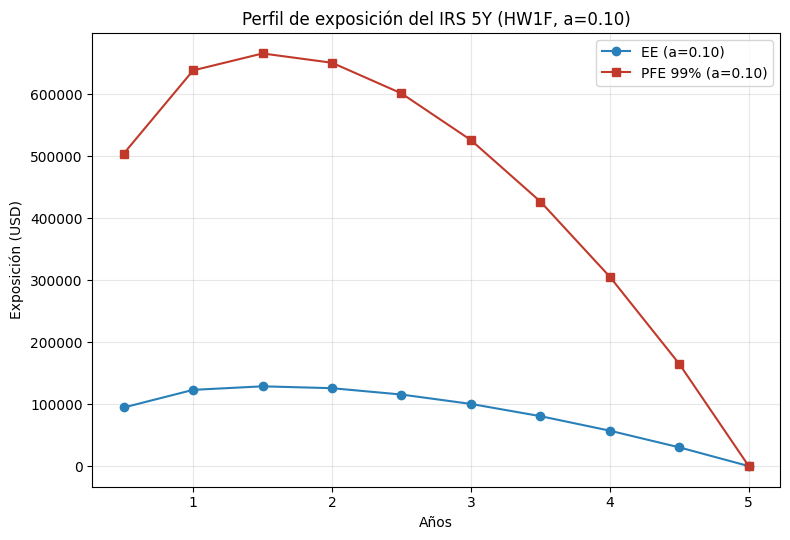

In [ ]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# ============================================================
# 1. Curva cero-cupón e I(t)
# ============================================================
def nelson_siegel(t, beta0, beta1, beta2, tau):
    t = np.asarray(t, float)
    t_safe = np.where(t == 0, 1e-6, t)
    return beta0 + beta1*(1-np.exp(-t_safe/tau))/(t_safe/tau) + \
           beta2*((1-np.exp(-t_safe/tau))/(t_safe/tau) - np.exp(-t_safe/tau))

ns_params = dict(beta0=0.042, beta1=-0.004, beta2=0.010, tau=2.5)
def zero_rate(t): return nelson_siegel(t, **ns_params)
def P0(t):
    t = np.asarray(t, float)
    return np.exp(-zero_rate(t) * t)

# --- Parámetros HW1F: mean reversion FORZADO a 0.10, sigma de la calibración ---
a_cal = 0.10
sigma_breakpoints = np.array([0.0, 1.0, 2.0, 5.0, 10.0])
sigma_cal = np.array([0.009228, 0.008215, 0.007939, 0.007332])

def sigma_of_t(t, sigma_values=sigma_cal):
    idx = np.searchsorted(sigma_breakpoints, t, side='right') - 1
    idx = np.clip(idx, 0, len(sigma_values) - 1)
    return sigma_values[idx]

def I_function(t, a=a_cal, sigma_values=sigma_cal):
    if t <= 1e-8:
        return 0.0
    integrand = lambda s: sigma_of_t(s, sigma_values)**2 * np.exp(-2*a*(t-s))
    val, _ = quad(integrand, 0, t, limit=100)
    return val

def B_hw(a, t, T):
    return (1 - np.exp(-a*(T-t))) / a

def P_hw_from_x(x, t, T, a=a_cal, sigma_values=sigma_cal):
    Bt = B_hw(a, t, T)
    I_t = I_function(t, a, sigma_values)
    A = (P0(T)/P0(t)) * np.exp(-0.5*I_t*Bt**2)
    return A * np.exp(-Bt * x)


# ============================================================
# 2. Simulación exacta de x(t) (OU, media cero)
# ============================================================
def simulate_x_paths(payment_dates, a=a_cal, sigma_values=sigma_cal, n_paths=100_000, seed=1):
    rng = np.random.default_rng(seed)
    t_grid = np.concatenate(([0.0], payment_dates))
    n_steps = len(t_grid) - 1

    x = np.zeros(n_paths)
    x_path = np.empty((n_paths, n_steps + 1)); x_path[:, 0] = 0.0

    I_vals = np.array([I_function(t, a, sigma_values) for t in t_grid])

    for k in range(n_steps):
        dt = t_grid[k+1] - t_grid[k]
        mean_mult = np.exp(-a*dt)
        var_step = I_vals[k+1] - np.exp(-2*a*dt)*I_vals[k]
        Z = rng.standard_normal(n_paths)
        x = x*mean_mult + np.sqrt(max(var_step, 0.0))*Z
        x_path[:, k+1] = x

    return t_grid, x_path


# ============================================================
# 3. Valuación del IRS vainilla en cada fecha de reset (telescoping)
# ============================================================
def price_irs_at_nodes(x_path, t_grid, payment_dates, K, notional, tau=0.5):
    n_paths = x_path.shape[0]
    n_dates = len(payment_dates)
    T_n = payment_dates[-1]

    V = np.zeros((n_paths, n_dates))
    for k in range(n_dates):
        Tk = payment_dates[k]
        idx_k = k + 1
        xk = x_path[:, idx_k]

        remaining = payment_dates[payment_dates > Tk + 1e-9]
        if len(remaining) == 0:
            V[:, k] = 0.0
            continue

        P_Tn = P_hw_from_x(xk, Tk, T_n)
        float_leg = 1.0 - P_Tn

        fixed_leg = np.zeros(n_paths)
        for Ti in remaining:
            fixed_leg += tau * P_hw_from_x(xk, Tk, Ti)
        fixed_leg *= K

        V[:, k] = notional * (float_leg - fixed_leg)

    return V


# ================= Setup: IRS 5Y, con a=0.10 =================
tenor_years = 5.0
tau = 0.5
payment_dates = np.arange(tau, tenor_years + 1e-9, tau)

notional = 10_000_000.0
K_par = (1 - P0(tenor_years)) / (tau * P0(payment_dates).sum())

print(f"Par swap rate (K, ATM, 5Y semestral): {K_par*100:.4f}%")
print(f"Parámetros HW1F: a={a_cal} (forzado), sigma buckets (bps)={np.round(sigma_cal*10000,2)}")

t_grid, x_path = simulate_x_paths(payment_dates, n_paths=100_000, seed=1)
V = price_irs_at_nodes(x_path, t_grid, payment_dates, K_par, notional, tau=tau)

exposure = np.maximum(V, 0.0)
EE = exposure.mean(axis=0)
PFE99 = np.percentile(exposure, 99, axis=0)
mean_V = V.mean(axis=0)

print(f"\nE[V(T1)] simulado (chequeo de consistencia MC): {mean_V[0]:,.2f}")
print(f"\nEE(t) por nodo (USD): {np.round(EE, 2)}")
print(f"PFE 99% por nodo (USD): {np.round(PFE99, 2)}")

# --- Plot ---
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.plot(payment_dates, EE, 'o-', color='#2980b9', label='EE (a=0.10)')
ax.plot(payment_dates, PFE99, 's-', color='#c0392b', label='PFE 99% (a=0.10)')
ax.set_xlabel('Años'); ax.set_ylabel('Exposición (USD)')
ax.set_title('Perfil de exposición del IRS 5Y (HW1F, a=0.10)')
ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

Par swap rates (ATM):
  2Y: 4.2036%
  3Y: 4.2874%
  5Y: 4.3622%

EE del netting set (USD): [     0.   197841.3  235921.47 219365.21 176820.21 143860.47 100578.85
  80887.55  57303.47  30312.08      0.  ]

CVA del netting set (3 IRS): 5,695.70 USD


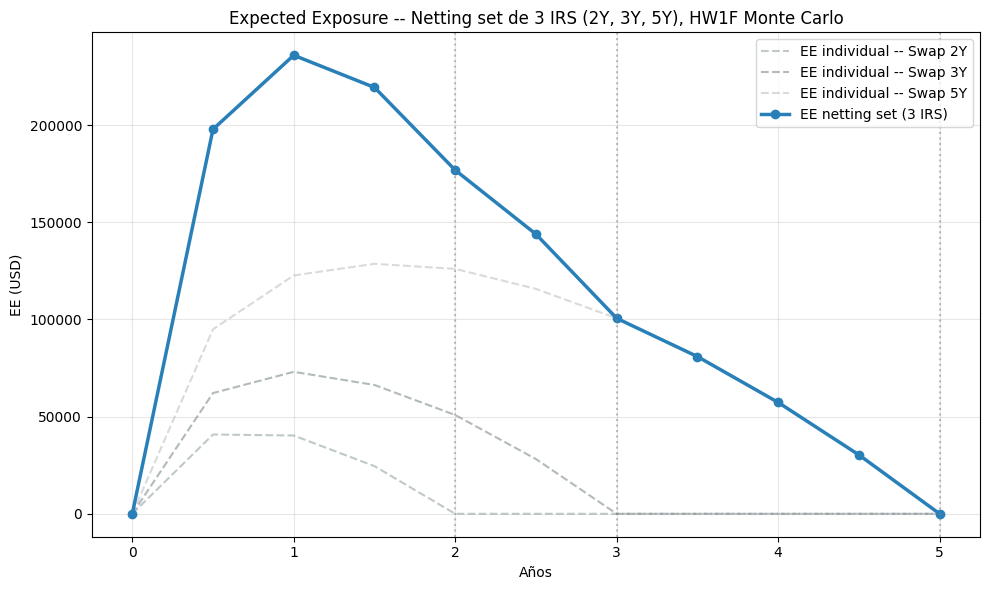

In [ ]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# ============================================================
# 1. Curva cero-cupón, HW1F calibrado (a=0.10)
# ============================================================
def nelson_siegel(t, beta0, beta1, beta2, tau):
    t = np.asarray(t, float)
    t_safe = np.where(t == 0, 1e-6, t)
    return beta0 + beta1*(1-np.exp(-t_safe/tau))/(t_safe/tau) + \
           beta2*((1-np.exp(-t_safe/tau))/(t_safe/tau) - np.exp(-t_safe/tau))

ns_params = dict(beta0=0.042, beta1=-0.004, beta2=0.010, tau=2.5)
def zero_rate(t): return nelson_siegel(t, **ns_params)
def P0(t):
    t = np.asarray(t, float)
    return np.exp(-zero_rate(t) * t)

a_cal = 0.10
sigma_breakpoints = np.array([0.0, 1.0, 2.0, 5.0, 10.0])
sigma_cal = np.array([0.009228, 0.008215, 0.007939, 0.007332])

def sigma_of_t(t, sigma_values=sigma_cal):
    idx = np.searchsorted(sigma_breakpoints, t, side='right') - 1
    idx = np.clip(idx, 0, len(sigma_values) - 1)
    return sigma_values[idx]

def I_function(t, a=a_cal, sigma_values=sigma_cal):
    if t <= 1e-8:
        return 0.0
    integrand = lambda s: sigma_of_t(s, sigma_values)**2 * np.exp(-2*a*(t-s))
    val, _ = quad(integrand, 0, t, limit=100)
    return val

def B_hw(a, t, T):
    return (1 - np.exp(-a*(T-t))) / a

def P_hw_from_x(x, t, T, a=a_cal, sigma_values=sigma_cal):
    Bt = B_hw(a, t, T)
    I_t = I_function(t, a, sigma_values)
    A = (P0(T)/P0(t)) * np.exp(-0.5*I_t*Bt**2)
    return A * np.exp(-Bt * x)


# ============================================================
# 2. Simulación de x(t) sobre el grid combinado de los 3 swaps
# ============================================================
def simulate_x_paths(t_grid, a=a_cal, sigma_values=sigma_cal, n_paths=100_000, seed=1):
    rng = np.random.default_rng(seed)
    n_steps = len(t_grid) - 1
    x = np.zeros(n_paths)
    x_path = np.empty((n_paths, n_steps + 1)); x_path[:, 0] = 0.0
    I_vals = np.array([I_function(t, a, sigma_values) for t in t_grid])
    for k in range(n_steps):
        dt = t_grid[k+1] - t_grid[k]
        mean_mult = np.exp(-a*dt)
        var_step = I_vals[k+1] - np.exp(-2*a*dt)*I_vals[k]
        Z = rng.standard_normal(n_paths)
        x = x*mean_mult + np.sqrt(max(var_step, 0.0))*Z
        x_path[:, k+1] = x
    return x_path


# ============================================================
# 3. Valuación de UN swap vainilla en cada nodo del grid combinado
# ============================================================
def price_irs(x_path, t_grid, own_payment_dates, K, notional, tau=0.5):
    n_paths = x_path.shape[0]
    T_n = own_payment_dates[-1]
    V = np.zeros((n_paths, len(t_grid)))

    for k, Tk in enumerate(t_grid):
        if Tk > T_n + 1e-9:
            continue
        idx_k = k
        xk = x_path[:, idx_k]

        remaining = own_payment_dates[own_payment_dates > Tk + 1e-9]
        if len(remaining) == 0:
            continue

        P_Tn = P_hw_from_x(xk, Tk, T_n)
        float_leg = 1.0 - P_Tn

        fixed_leg = np.zeros(n_paths)
        for Ti in remaining:
            fixed_leg += tau * P_hw_from_x(xk, Tk, Ti)
        fixed_leg *= K

        V[:, k] = notional * (float_leg - fixed_leg)

    return V


# ============================================================
# 4. Curva de crédito y CVA
# ============================================================
def calibrate_survival_curve_piecewise(cds_tenors, cds_spreads_bps, RR=0.25):
    tenors = np.asarray(cds_tenors, float)
    spreads = np.asarray(cds_spreads_bps, float) / 10_000.0
    lam_cum = spreads / (1 - RR)
    tenors_ext = np.concatenate(([0.0], tenors))
    def Q(t):
        t = np.atleast_1d(np.asarray(t, float))
        out = np.empty_like(t)
        for i, tt in enumerate(t):
            idx = np.searchsorted(tenors_ext, tt, side='right') - 1
            idx = np.clip(idx, 0, len(lam_cum) - 1)
            lam_prev = lam_cum[idx - 1] if idx > 0 else 0.0
            t_prev = tenors_ext[idx]
            lam_here = lam_cum[idx]
            cum_hazard = lam_prev * t_prev + lam_here * (tt - t_prev)
            out[i] = np.exp(-cum_hazard)
        return out
    return Q

def compute_cva(time_grid, EE, Q_func, r_zero_func, RR=0.25):
    t = np.concatenate(([0.0], time_grid))
    Q_nodes = Q_func(t)
    dPD = -np.diff(Q_nodes)
    DF = np.exp(-r_zero_func(time_grid) * time_grid)
    EE_ext = np.concatenate(([0.0], EE))
    EE_avg = 0.5 * (EE_ext[:-1] + EE_ext[1:])
    contrib = (1 - RR) * EE_avg * dPD * DF
    return contrib.sum(), contrib


# ================= Setup: 3 IRS, notional 10MM cada uno =================
notional = 10_000_000.0
tau = 0.5

maturities = {'2Y': 2.0, '3Y': 3.0, '5Y': 5.0}
payment_dates_by_swap = {name: np.arange(tau, T + 1e-9, tau) for name, T in maturities.items()}
K_by_swap = {name: (1 - P0(T)) / (tau * P0(pd).sum())
             for name, T, pd in zip(maturities.keys(), maturities.values(), payment_dates_by_swap.values())}

print("Par swap rates (ATM):")
for name, K in K_by_swap.items():
    print(f"  {name}: {K*100:.4f}%")

t_grid = np.arange(tau, 5.0 + 1e-9, tau)
t_grid_full = np.concatenate(([0.0], t_grid))

x_path = simulate_x_paths(t_grid_full, n_paths=150_000, seed=1)

V_total = np.zeros((x_path.shape[0], len(t_grid_full)))
V_by_swap = {}
for name, T in maturities.items():
    V_swap = price_irs(x_path, t_grid_full, payment_dates_by_swap[name], K_by_swap[name], notional, tau=tau)
    V_by_swap[name] = V_swap
    V_total += V_swap

EE_netting = np.maximum(V_total, 0.0).mean(axis=0)
EE_2Y = np.maximum(V_by_swap['2Y'], 0.0).mean(axis=0)
EE_3Y = np.maximum(V_by_swap['3Y'], 0.0).mean(axis=0)
EE_5Y = np.maximum(V_by_swap['5Y'], 0.0).mean(axis=0)

print(f"\nEE del netting set (USD): {np.round(EE_netting, 2)}")

cds_tenors  = np.array([0.5, 1, 2, 3, 5])
cds_spreads = np.array([45.0, 60.0, 80.0, 100.0, 130.0])
RR = 0.25
Q_func = calibrate_survival_curve_piecewise(cds_tenors, cds_spreads, RR=RR)

cva, contrib = compute_cva(t_grid, EE_netting[1:], Q_func, r_zero_func=zero_rate, RR=RR)
print(f"\nCVA del netting set (3 IRS): {cva:,.2f} USD")


# ============================================================
# 5. Plot -- SOLO el EE
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))

ax.plot(t_grid_full, EE_2Y, '--', color='#95a5a6', alpha=0.6, label='EE individual -- Swap 2Y')
ax.plot(t_grid_full, EE_3Y, '--', color='#7f8c8d', alpha=0.6, label='EE individual -- Swap 3Y')
ax.plot(t_grid_full, EE_5Y, '--', color='#bdc3c7', alpha=0.6, label='EE individual -- Swap 5Y')
ax.plot(t_grid_full, EE_netting, 'o-', color='#2980b9', linewidth=2.5, label='EE netting set (3 IRS)')

for name, T in maturities.items():
    ax.axvline(T, color='gray', linestyle=':', alpha=0.5)

ax.set_xlabel('Años')
ax.set_ylabel('EE (USD)')
ax.set_title('Expected Exposure -- Netting set de 3 IRS (2Y, 3Y, 5Y), HW1F Monte Carlo')
ax.legend()
ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

## Curvas con Hull White

t=0.5y | tasa 5Y forward: media=4.277%  std=0.323%  | tasa 10Y forward: media=4.272%  std=0.260%
t=1.0y | tasa 5Y forward: media=4.099%  std=0.542%  | tasa 10Y forward: media=4.117%  std=0.435%
t=2.0y | tasa 5Y forward: media=3.773%  std=0.641%  | tasa 10Y forward: media=3.843%  std=0.515%
t=5.0y | tasa 5Y forward: media=3.562%  std=0.968%  | tasa 10Y forward: media=3.680%  std=0.777%


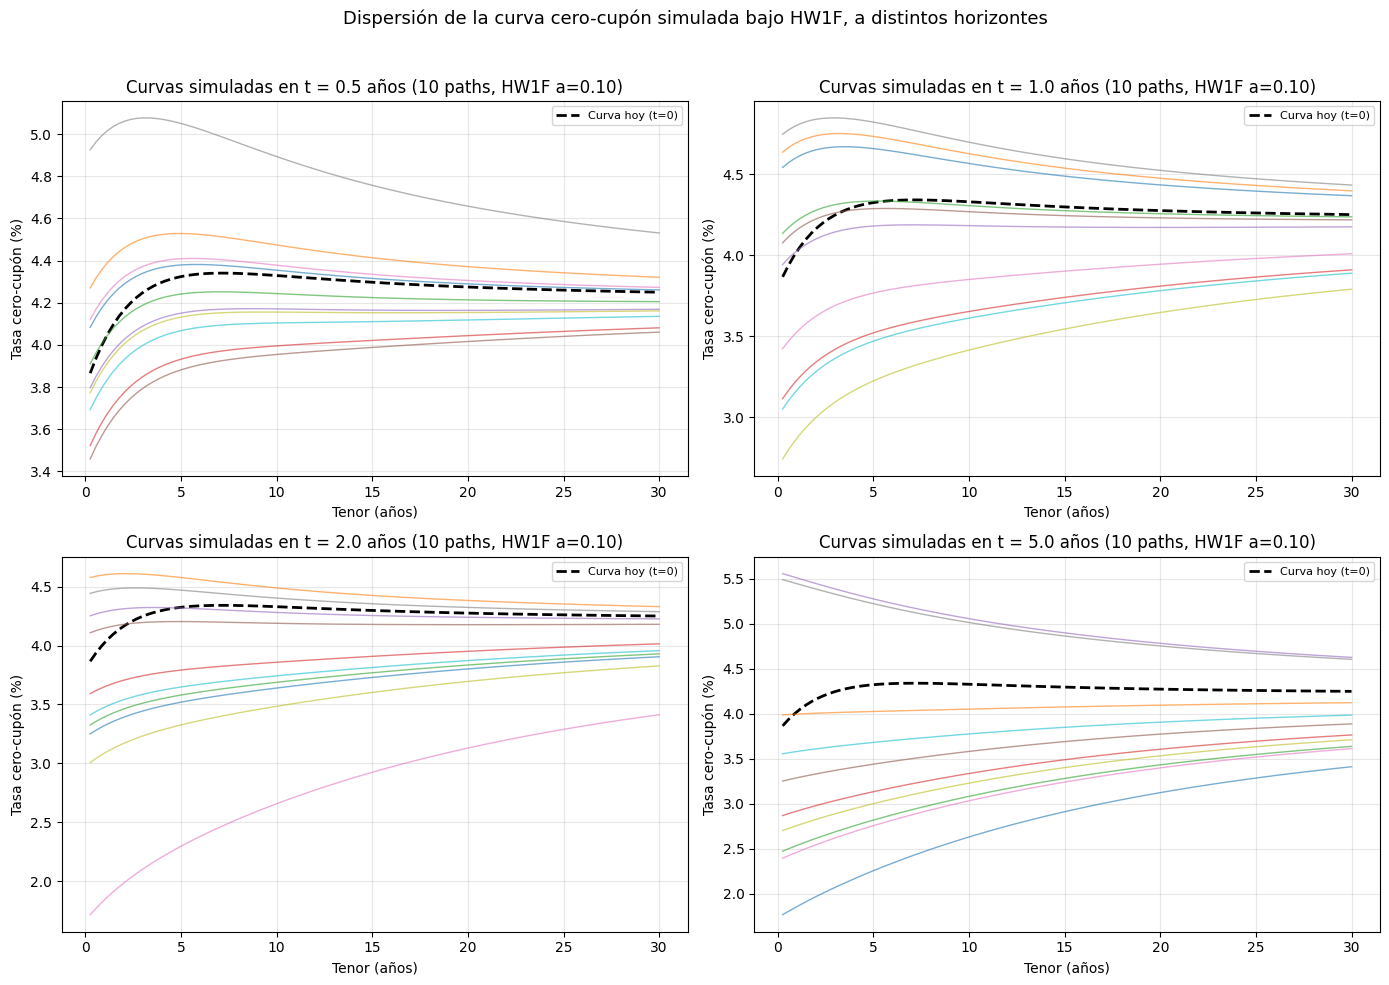

In [ ]:
import numpy as np
from scipy.integrate import quad
import matplotlib.pyplot as plt

# ============================================================
# 1. Curva cero-cupón e I(t) -- mismos parámetros calibrados
# ============================================================
def nelson_siegel(t, beta0, beta1, beta2, tau):
    t = np.asarray(t, float)
    t_safe = np.where(t == 0, 1e-6, t)
    return beta0 + beta1*(1-np.exp(-t_safe/tau))/(t_safe/tau) + \
           beta2*((1-np.exp(-t_safe/tau))/(t_safe/tau) - np.exp(-t_safe/tau))

ns_params = dict(beta0=0.042, beta1=-0.004, beta2=0.010, tau=2.5)
def zero_rate(t): return nelson_siegel(t, **ns_params)
def P0(t):
    t = np.asarray(t, float)
    return np.exp(-zero_rate(t) * t)

a_cal = 0.10          # mean reversion calibrado (forzado)
sigma_breakpoints = np.array([0.0, 1.0, 2.0, 5.0, 10.0])
sigma_cal = np.array([0.009228, 0.008215, 0.007939, 0.007332])

def sigma_of_t(t, sigma_values=sigma_cal):
    idx = np.searchsorted(sigma_breakpoints, t, side='right') - 1
    idx = np.clip(idx, 0, len(sigma_values) - 1)
    return sigma_values[idx]

def I_function(t, a=a_cal, sigma_values=sigma_cal):
    if t <= 1e-8:
        return 0.0
    integrand = lambda s: sigma_of_t(s, sigma_values)**2 * np.exp(-2*a*(t-s))
    val, _ = quad(integrand, 0, t, limit=100)
    return val

def B_hw(a, t, T):
    return (1 - np.exp(-a*(T-t))) / a

def P_hw_from_x(x, t, T, a=a_cal, sigma_values=sigma_cal):
    Bt = B_hw(a, t, T)
    I_t = I_function(t, a, sigma_values)
    A = (P0(T)/P0(t)) * np.exp(-0.5*I_t*Bt**2)
    return A * np.exp(-Bt * x)


# ============================================================
# 2. Simulación exacta de x(t) hasta varios horizontes de evaluación
# ============================================================
def simulate_x_paths(t_grid, a=a_cal, sigma_values=sigma_cal, n_paths=10, seed=7):
    rng = np.random.default_rng(seed)
    n_steps = len(t_grid) - 1
    x = np.zeros(n_paths)
    x_path = np.empty((n_paths, n_steps + 1)); x_path[:, 0] = 0.0
    I_vals = np.array([I_function(t, a, sigma_values) for t in t_grid])
    for k in range(n_steps):
        dt = t_grid[k+1] - t_grid[k]
        mean_mult = np.exp(-a*dt)
        var_step = I_vals[k+1] - np.exp(-2*a*dt)*I_vals[k]
        Z = rng.standard_normal(n_paths)
        x = x*mean_mult + np.sqrt(max(var_step, 0.0))*Z
        x_path[:, k+1] = x
    return x_path


# ================= Setup =================
eval_dates = [0.5, 1.0, 2.0, 5.0]     # horizontes futuros a inspeccionar
t_grid = np.array([0.0] + eval_dates)  # nodos de simulación (llegan exacto a cada eval_date)
tenors = np.linspace(0.25, 30, 100)    # tenores de la curva (0.25 a 30 años)

n_paths = 10
x_path = simulate_x_paths(t_grid, n_paths=n_paths, seed=7)

# --- Curva de hoy (determinística, referencia) ---
zero_today = zero_rate(tenors) * 100  # en %

# ============================================================
# 3. Plot: panel por cada horizonte de evaluación
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for ax, (idx, T_eval) in zip(axes, enumerate(eval_dates, start=1)):
    ax.plot(tenors, zero_today, color='black', linewidth=2, linestyle='--', label='Curva hoy (t=0)')
    for p in range(n_paths):
        x_p = x_path[p, idx]
        # curva simulada en T_eval: para cada tenor tau, zero rate = -ln(P(T_eval,T_eval+tau))/tau
        P_vals = np.array([P_hw_from_x(x_p, T_eval, T_eval + tau) for tau in tenors])
        zero_sim = -np.log(P_vals) / tenors * 100
        ax.plot(tenors, zero_sim, alpha=0.6, linewidth=1)

    ax.set_title(f'Curvas simuladas en t = {T_eval} años (10 paths, HW1F a=0.10)')
    ax.set_xlabel('Tenor (años)')
    ax.set_ylabel('Tasa cero-cupón (%)')
    ax.legend(fontsize=8)
    ax.grid(alpha=0.3)

fig.suptitle('Dispersión de la curva cero-cupón simulada bajo HW1F, a distintos horizontes', fontsize=13)
fig.tight_layout(rect=[0, 0, 1, 0.96])

# --- Estadísticas rápidas de dispersión por horizonte, en el tenor 5Y y 10Y ---
for T_eval in eval_dates:
    idx = eval_dates.index(T_eval) + 1
    zeros_5y = []
    zeros_10y = []
    for p in range(n_paths):
        x_p = x_path[p, idx]
        P5 = P_hw_from_x(x_p, T_eval, T_eval + 5)
        P10 = P_hw_from_x(x_p, T_eval, T_eval + 10)
        zeros_5y.append(-np.log(P5)/5*100)
        zeros_10y.append(-np.log(P10)/10*100)
    print(f"t={T_eval}y | tasa 5Y forward: media={np.mean(zeros_5y):.3f}%  std={np.std(zeros_5y):.3f}%  "
          f"| tasa 10Y forward: media={np.mean(zeros_10y):.3f}%  std={np.std(zeros_10y):.3f}%")

## Cross Currency

E[S(T=5.0)] simulado (con ajuste quanto):    1.296761
Forward FX teórico (covered interest parity):     1.297680
Diferencia relativa: -0.071%

E[S(T)] SIN ajuste quanto (mal especificado):     1.294554
Sesgo introducido al omitir el quanto:             -0.241%


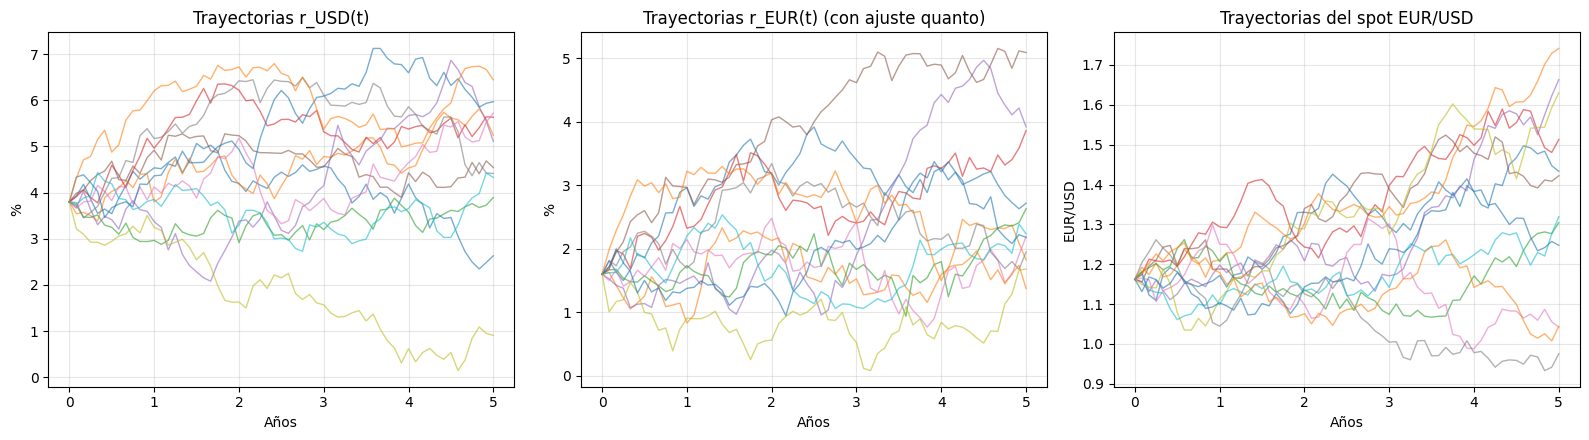

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Curvas cero-cupón USD y EUR (Nelson-Siegel, sintéticas)
# ============================================================
def nelson_siegel(t, beta0, beta1, beta2, tau):
    t = np.asarray(t, float)
    t_safe = np.where(t == 0, 1e-6, t)
    return beta0 + beta1*(1-np.exp(-t_safe/tau))/(t_safe/tau) + \
           beta2*((1-np.exp(-t_safe/tau))/(t_safe/tau) - np.exp(-t_safe/tau))

ns_usd = dict(beta0=0.042, beta1=-0.004, beta2=0.010, tau=2.5)   # misma curva USD de siempre
ns_eur = dict(beta0=0.022, beta1=-0.006, beta2=0.006, tau=2.5)   # curva EUR sintética (~2% nivel)

def zero_usd(t): return nelson_siegel(t, **ns_usd)
def zero_eur(t): return nelson_siegel(t, **ns_eur)
def P0_usd(t):
    t = np.asarray(t, float); return np.exp(-zero_usd(t)*t)
def P0_eur(t):
    t = np.asarray(t, float); return np.exp(-zero_eur(t)*t)
def f_usd(t, eps=1e-4):
    return -(np.log(P0_usd(t+eps))-np.log(P0_usd(t-eps)))/(2*eps)
def f_eur(t, eps=1e-4):
    return -(np.log(P0_eur(t+eps))-np.log(P0_eur(t-eps)))/(2*eps)


# ============================================================
# 2. Parámetros del modelo híbrido de 3 factores (LGM/HW + FX lognormal)
#    NOTA: sigma constante en esta versión (simplificado respecto al sigma(t)
#    piecewise calibrado antes) para mantener el ajuste quanto tratable en forma cerrada.
# ============================================================
a_usd = 0.10
a_eur = 0.08                 # mean reversion EUR (ilustrativo, distinto del USD)
sigma_usd = 0.0081           # vol HW USD (promedio representativo de la calibración piecewise)
sigma_eur = 0.0070           # vol HW EUR (ilustrativo)
sigma_fx  = 0.075            # vol lognormal del spot EUR/USD (misma usada en sesiones anteriores)

rho_usd_eur = 0.60           # correlación entre las dos curvas de tasas
rho_usd_fx  = -0.20          # correlación USD rate <-> spot
rho_eur_fx  =  0.30          # correlación EUR rate <-> spot

S0 = 1.1622                  # spot EUR/USD (USD por 1 EUR)

# --- Matriz de correlación y descomposición de Cholesky ---
corr = np.array([
    [1.0,          rho_usd_eur, rho_usd_fx],
    [rho_usd_eur,  1.0,         rho_eur_fx],
    [rho_usd_fx,   rho_eur_fx,  1.0       ],
])
L = np.linalg.cholesky(corr)   # orden de factores: [USD, EUR, FX]


# ============================================================
# 3. Fórmulas de bono HW1F (sigma constante) -- una por divisa
# ============================================================
def B_hw(a, t, T):
    return (1 - np.exp(-a*(T-t))) / a

def P_hw(x, t, T, a, sigma, P0_func, f_func):
    Bt = B_hw(a, t, T)
    I_t = sigma**2 * (1 - np.exp(-2*a*t)) / (2*a) if t > 0 else 0.0   # I(t) cerrado (sigma constante)
    A = (P0_func(T)/P0_func(t)) * np.exp(Bt*f_func(t) - 0.5*I_t*Bt**2) if t > 0 else P0_func(T)
    return A * np.exp(-Bt * x)


# ============================================================
# 4. Simulación conjunta de x_usd, x_eur, ln(S) -- con AJUSTE QUANTO en r_EUR
# ============================================================
def simulate_hybrid(T, n_paths=200_000, n_steps_per_year=12, seed=1):
    rng = np.random.default_rng(seed)
    n_steps = int(T * n_steps_per_year)
    dt = T / n_steps

    x_usd = np.zeros(n_paths)
    x_eur = np.zeros(n_paths)
    lnS   = np.full(n_paths, np.log(S0))

    t_grid = np.linspace(0, T, n_steps + 1)
    x_usd_path = np.empty((n_paths, n_steps+1)); x_usd_path[:,0] = 0.0
    x_eur_path = np.empty((n_paths, n_steps+1)); x_eur_path[:,0] = 0.0
    S_path     = np.empty((n_paths, n_steps+1)); S_path[:,0] = S0

    # --- varianza de cada paso (determinística, sigma constante) ---
    var_usd_step = sigma_usd**2 * (1 - np.exp(-2*a_usd*dt)) / (2*a_usd)
    var_eur_step = sigma_eur**2 * (1 - np.exp(-2*a_eur*dt)) / (2*a_eur)
    mean_mult_usd = np.exp(-a_usd*dt)
    mean_mult_eur = np.exp(-a_eur*dt)

    # --- ajuste quanto: drift determinístico adicional en x_eur, por paso ---
    # dx_eur = -a_eur*x_eur dt - rho_eur_fx*sigma_eur*sigma_fx dt + sigma_eur dW_eur   (bajo medida USD)
    quanto_shift_step = -rho_eur_fx * sigma_eur * sigma_fx * (1 - np.exp(-a_eur*dt)) / a_eur

    for k in range(n_steps):
        Z = rng.standard_normal((n_paths, 3))          # [Z_usd, Z_eur, Z_fx] independientes
        Zc = Z @ L.T                                     # correlacionados vía Cholesky

        r_usd_now = x_usd + f_usd(t_grid[k])
        r_eur_now = x_eur + f_eur(t_grid[k])

        # --- actualizar x_usd (OU puro, sin ajuste quanto: es la moneda doméstica) ---
        x_usd = x_usd*mean_mult_usd + np.sqrt(var_usd_step)*Zc[:,0]

        # --- actualizar x_eur (OU + ajuste quanto determinístico) ---
        x_eur = x_eur*mean_mult_eur + quanto_shift_step + np.sqrt(var_eur_step)*Zc[:,1]

        # --- actualizar ln(S) (lognormal, drift = diferencial de tasas cortas) ---
        lnS = lnS + (r_usd_now - r_eur_now - 0.5*sigma_fx**2)*dt + sigma_fx*np.sqrt(dt)*Zc[:,2]

        x_usd_path[:,k+1] = x_usd
        x_eur_path[:,k+1] = x_eur
        S_path[:,k+1] = np.exp(lnS)

    return t_grid, x_usd_path, x_eur_path, S_path


# ============================================================
# 5. VALIDACIÓN: E[S(T)] debe converger al forward FX (paridad cubierta de tasas)
#    F(0,T) = S0 * P0_eur(T)/P0_usd(T)
# ============================================================
T_test = 5.0
t_grid, x_usd_path, x_eur_path, S_path = simulate_hybrid(T_test, n_paths=200_000, seed=1)

E_S_T = S_path[:, -1].mean()

# Forward teórico bajo covered interest rate parity:
# S = USD por EUR. Comprar EUR forward cuesta, en USD, S0*P0_eur(T)/P0_usd(T)
F_theoretical = S0 * P0_eur(T_test) / P0_usd(T_test)

print(f"E[S(T={T_test})] simulado (con ajuste quanto):    {E_S_T:.6f}")
print(f"Forward FX teórico (covered interest parity):     {F_theoretical:.6f}")
print(f"Diferencia relativa: {(E_S_T/F_theoretical - 1)*100:.3f}%")

# --- Comparación: qué pasaría SIN el ajuste quanto (mal especificado) ---
def simulate_hybrid_no_quanto(T, n_paths=200_000, n_steps_per_year=12, seed=1):
    rng = np.random.default_rng(seed)
    n_steps = int(T * n_steps_per_year)
    dt = T / n_steps
    x_usd = np.zeros(n_paths); x_eur = np.zeros(n_paths); lnS = np.full(n_paths, np.log(S0))
    t_grid = np.linspace(0, T, n_steps + 1)
    var_usd_step = sigma_usd**2 * (1 - np.exp(-2*a_usd*dt)) / (2*a_usd)
    var_eur_step = sigma_eur**2 * (1 - np.exp(-2*a_eur*dt)) / (2*a_eur)
    mean_mult_usd = np.exp(-a_usd*dt); mean_mult_eur = np.exp(-a_eur*dt)
    for k in range(n_steps):
        Z = rng.standard_normal((n_paths, 3)); Zc = Z @ L.T
        r_usd_now = x_usd + f_usd(t_grid[k]); r_eur_now = x_eur + f_eur(t_grid[k])
        x_usd = x_usd*mean_mult_usd + np.sqrt(var_usd_step)*Zc[:,0]
        x_eur = x_eur*mean_mult_eur + np.sqrt(var_eur_step)*Zc[:,1]     # <- SIN quanto_shift_step
        lnS = lnS + (r_usd_now - r_eur_now - 0.5*sigma_fx**2)*dt + sigma_fx*np.sqrt(dt)*Zc[:,2]
    return np.exp(lnS)

S_T_no_quanto = simulate_hybrid_no_quanto(T_test, n_paths=200_000, seed=1)
E_S_T_no_quanto = S_T_no_quanto.mean()
print(f"\nE[S(T)] SIN ajuste quanto (mal especificado):     {E_S_T_no_quanto:.6f}")
print(f"Sesgo introducido al omitir el quanto:             {(E_S_T_no_quanto/F_theoretical - 1)*100:.3f}%")


# ============================================================
# 6. Plot: trayectorias de r_USD, r_EUR y S(t)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

n_show = 12
for p in range(n_show):
    r_usd_path_p = x_usd_path[p] + np.array([f_usd(t) for t in t_grid])
    r_eur_path_p = x_eur_path[p] + np.array([f_eur(t) for t in t_grid])
    axes[0].plot(t_grid, r_usd_path_p*100, alpha=0.6, linewidth=1)
    axes[1].plot(t_grid, r_eur_path_p*100, alpha=0.6, linewidth=1)
    axes[2].plot(t_grid, S_path[p], alpha=0.6, linewidth=1)

axes[0].set_title('Trayectorias r_USD(t)'); axes[0].set_xlabel('Años'); axes[0].set_ylabel('%')
axes[1].set_title('Trayectorias r_EUR(t) (con ajuste quanto)'); axes[1].set_xlabel('Años'); axes[1].set_ylabel('%')
axes[2].set_title('Trayectorias del spot EUR/USD'); axes[2].set_xlabel('Años'); axes[2].set_ylabel('EUR/USD')
for ax in axes: ax.grid(alpha=0.3)

fig.tight_layout()
plt.show()

Notional USD: 10,000,000  |  Notional EUR: 8,604,371

EE(t) del CCS (USD): [ 178494.  271647.  349166.  421024.  489628.  555244.  617979.  680725.
  741493.  801607.  860236.  919510.  978526. 1035128. 1095159. 1151921.
 1208786. 1266918. 1324319. 1381942.]
PFE 99% (USD):       [ 964156. 1418034. 1777728. 2094182. 2373605. 2663295. 2929881. 3176072.
 3410877. 3655336. 3880085. 4086343. 4303817. 4532526. 4741348. 4947756.
 5130003. 5353925. 5525360. 5725625.]

EE en el último nodo antes del intercambio final vs. el intercambio mismo:
  EE(t=4.75y): 1,324,319
  EE(t=5.00y, incluye repago de notional): 1,381,942


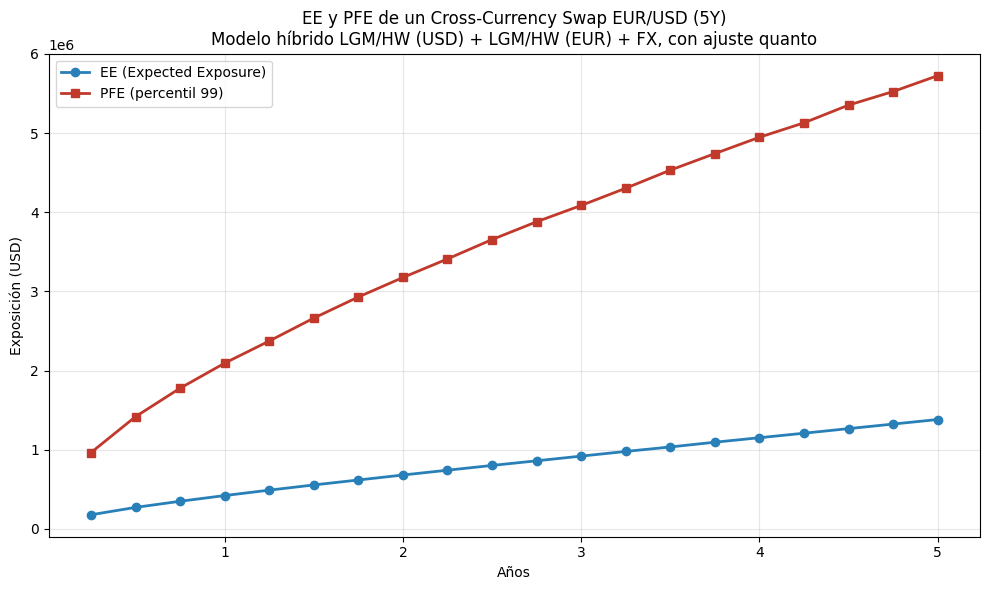

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. Curvas cero-cupón USD y EUR (Nelson-Siegel)
# ============================================================
def nelson_siegel(t, beta0, beta1, beta2, tau):
    t = np.asarray(t, float)
    t_safe = np.where(t == 0, 1e-6, t)
    return beta0 + beta1*(1-np.exp(-t_safe/tau))/(t_safe/tau) + \
           beta2*((1-np.exp(-t_safe/tau))/(t_safe/tau) - np.exp(-t_safe/tau))

ns_usd = dict(beta0=0.042, beta1=-0.004, beta2=0.010, tau=2.5)
ns_eur = dict(beta0=0.022, beta1=-0.006, beta2=0.006, tau=2.5)

def zero_usd(t): return nelson_siegel(t, **ns_usd)
def zero_eur(t): return nelson_siegel(t, **ns_eur)
def P0_usd(t):
    t = np.asarray(t, float); return np.exp(-zero_usd(t)*t)
def P0_eur(t):
    t = np.asarray(t, float); return np.exp(-zero_eur(t)*t)
def f_usd(t, eps=1e-4):
    return -(np.log(P0_usd(t+eps))-np.log(P0_usd(t-eps)))/(2*eps)
def f_eur(t, eps=1e-4):
    return -(np.log(P0_eur(t+eps))-np.log(P0_eur(t-eps)))/(2*eps)


# ============================================================
# 2. Modelo híbrido de 3 factores (LGM/HW USD + LGM/HW EUR + FX, con quanto)
# ============================================================
a_usd, a_eur = 0.10, 0.08
sigma_usd, sigma_eur, sigma_fx = 0.0081, 0.0070, 0.075
rho_usd_eur, rho_usd_fx, rho_eur_fx = 0.60, -0.20, 0.30
S0 = 1.1622

corr = np.array([
    [1.0,          rho_usd_eur, rho_usd_fx],
    [rho_usd_eur,  1.0,         rho_eur_fx],
    [rho_usd_fx,   rho_eur_fx,  1.0       ],
])
L = np.linalg.cholesky(corr)

def B_hw(a, t, T):
    return (1 - np.exp(-a*(T-t))) / a

def P_hw(x, t, T, a, sigma, P0_func, f_func):
    Bt = B_hw(a, t, T)
    I_t = sigma**2 * (1 - np.exp(-2*a*t)) / (2*a) if t > 0 else 0.0
    A = (P0_func(T)/P0_func(t)) * np.exp(Bt*f_func(t) - 0.5*I_t*Bt**2) if t > 0 else P0_func(T)
    return A * np.exp(-Bt * x)

def simulate_hybrid(T, n_paths=200_000, n_steps_per_year=12, seed=1):
    rng = np.random.default_rng(seed)
    n_steps = int(T * n_steps_per_year)
    dt = T / n_steps

    x_usd = np.zeros(n_paths)
    x_eur = np.zeros(n_paths)
    lnS   = np.full(n_paths, np.log(S0))

    t_grid = np.linspace(0, T, n_steps + 1)
    x_usd_path = np.empty((n_paths, n_steps+1)); x_usd_path[:,0] = 0.0
    x_eur_path = np.empty((n_paths, n_steps+1)); x_eur_path[:,0] = 0.0
    S_path     = np.empty((n_paths, n_steps+1)); S_path[:,0] = S0

    var_usd_step = sigma_usd**2 * (1 - np.exp(-2*a_usd*dt)) / (2*a_usd)
    var_eur_step = sigma_eur**2 * (1 - np.exp(-2*a_eur*dt)) / (2*a_eur)
    mean_mult_usd = np.exp(-a_usd*dt)
    mean_mult_eur = np.exp(-a_eur*dt)
    quanto_shift_step = -rho_eur_fx * sigma_eur * sigma_fx * (1 - np.exp(-a_eur*dt)) / a_eur

    for k in range(n_steps):
        Z = rng.standard_normal((n_paths, 3))
        Zc = Z @ L.T
        r_usd_now = x_usd + f_usd(t_grid[k])
        r_eur_now = x_eur + f_eur(t_grid[k])

        x_usd = x_usd*mean_mult_usd + np.sqrt(var_usd_step)*Zc[:,0]
        x_eur = x_eur*mean_mult_eur + quanto_shift_step + np.sqrt(var_eur_step)*Zc[:,1]
        lnS = lnS + (r_usd_now - r_eur_now - 0.5*sigma_fx**2)*dt + sigma_fx*np.sqrt(dt)*Zc[:,2]

        x_usd_path[:,k+1] = x_usd
        x_eur_path[:,k+1] = x_eur
        S_path[:,k+1] = np.exp(lnS)

    return t_grid, x_usd_path, x_eur_path, S_path


# ============================================================
# 3. Valuación del CCS: floating-flat / floating-flat, notional
#    intercambiado en t=0 y en T -- SIN spread de base (caso simple)
#
#    Identidad clave: cada pata "cupón flotante + notional" vale
#    EXACTAMENTE el notional en su propia moneda, en cualquier t:
#       Pata_EUR_en_EUR(t) = N_EUR*(1-P_eur(t,Tn)) + N_EUR*P_eur(t,Tn) = N_EUR
#       Pata_USD_en_USD(t) = N_USD*(1-P_usd(t,Tn)) + N_USD*P_usd(t,Tn) = N_USD
#    Por eso V(t) = N_EUR*S(t) - N_USD -- toda la exposición es FX.
# ============================================================
notional_usd = 10_000_000.0
N_USD = notional_usd
N_EUR = notional_usd / S0     # conversión al spot de hoy, para que V(0)=0

T_ccs = 5.0
n_paths = 200_000

t_grid, x_usd_path, x_eur_path, S_path = simulate_hybrid(T_ccs, n_paths=n_paths, seed=1)

def ccs_value(S_t):
    """Bank recibe la pata EUR (convertida a USD) y paga la pata USD."""
    return N_EUR * S_t - N_USD

# --- nodos de evaluación (trimestral) ---
eval_months = np.arange(3, int(T_ccs*12)+1, 3)     # cada 3 meses
eval_years = eval_months / 12.0
idx = eval_months     # como los pasos son mensuales, el índice coincide con el mes

EE = np.empty(len(eval_years))
PFE99 = np.empty(len(eval_years))
ENE = np.empty(len(eval_years))

for i, m in enumerate(idx):
    V = ccs_value(S_path[:, m])
    exposure_pos = np.maximum(V, 0.0)
    exposure_neg = np.minimum(V, 0.0)
    EE[i] = exposure_pos.mean()
    PFE99[i] = np.percentile(exposure_pos, 99)
    ENE[i] = exposure_neg.mean()

print(f"Notional USD: {N_USD:,.0f}  |  Notional EUR: {N_EUR:,.0f}")
print(f"\nEE(t) del CCS (USD): {np.round(EE, 0)}")
print(f"PFE 99% (USD):       {np.round(PFE99, 0)}")
print(f"\nEE en el último nodo antes del intercambio final vs. el intercambio mismo:")
print(f"  EE(t=4.75y): {EE[-2]:,.0f}")
print(f"  EE(t=5.00y, incluye repago de notional): {EE[-1]:,.0f}")


# ============================================================
# 4. Plot: EE y PFE del CCS
# ============================================================
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(eval_years, EE, 'o-', color='#2980b9', linewidth=2, label='EE (Expected Exposure)')
ax.plot(eval_years, PFE99, 's-', color='#c0392b', linewidth=2, label='PFE (percentil 99)')
ax.set_xlabel('Años')
ax.set_ylabel('Exposición (USD)')
ax.set_title('EE y PFE de un Cross-Currency Swap EUR/USD (5Y)\nModelo híbrido LGM/HW (USD) + LGM/HW (EUR) + FX, con ajuste quanto')
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

## Anslisis para identificar WWR

Datos generados: 1499 observaciones diarias (~5.9 años)
Días de estrés: 68 (4.5% de la muestra)

=== Correlación INCONDICIONAL (n=1499) ===
Pearson:  -0.433  (IC95%: [-0.473, -0.391])
Spearman: -0.071

=== Cola (peor 10%, n=150) ===
Pearson: -0.875  (IC95% bootstrap: [-0.925, -0.801])
Amplificación: 2.02x

=== Cola (peor 5%, n=75) ===
Pearson: -0.883  (IC95% bootstrap: [-0.939, -0.792])
Amplificación: 2.04x

VEREDICTO: ROJO -- WWR significativo y material: requiere ajuste de CVA y revisión de límites


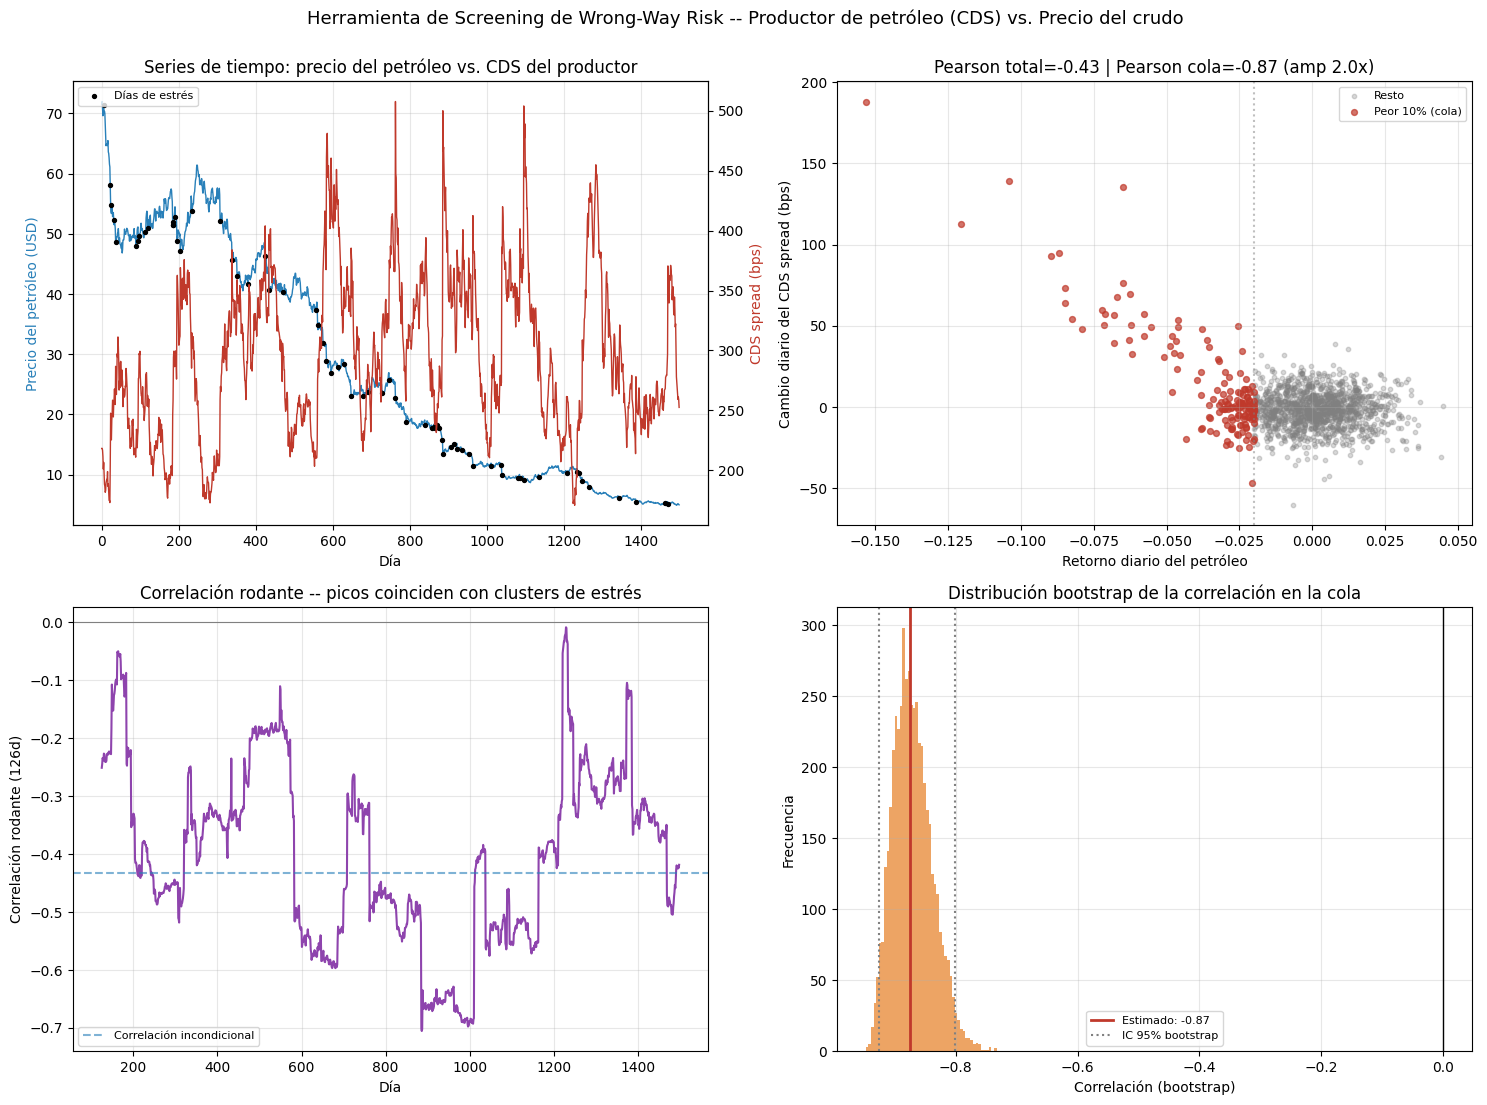

In [ ]:
import numpy as np
import pandas as pd
from scipy import stats
import matplotlib.pyplot as plt

rng = np.random.default_rng(7)

# ============================================================
# 1. Generación de datos sintéticos con dependencia de cola OCULTA
#    (modelo de régimen: normal vs. estrés, con un factor sistémico
#    compartido que solo se activa en el régimen de estrés)
# ============================================================
n_days = 1500
p_stress = 0.05

is_stress = rng.uniform(size=n_days) < p_stress
F = rng.standard_normal(n_days)
eps_oil = rng.standard_normal(n_days)
eps_credit = rng.standard_normal(n_days)

mu_oil = 0.0002
sigma_oil_normal = 0.014
sigma_oil_stress_idio = 0.010
stress_oil_magnitude = 0.055

rho_baseline = 0.05
sigma_credit_normal = 0.035
sigma_credit_idio_stress = 0.03
stress_credit_magnitude = 0.16

oil_returns = np.where(
    is_stress,
    mu_oil - stress_oil_magnitude*np.abs(F) + sigma_oil_stress_idio*eps_oil,
    mu_oil + sigma_oil_normal*eps_oil
)

credit_shock = np.where(
    is_stress,
    stress_credit_magnitude*np.abs(F) + sigma_credit_idio_stress*eps_credit,
    rho_baseline*sigma_credit_normal*eps_oil + sigma_credit_normal*np.sqrt(1-rho_baseline**2)*eps_credit
)

oil_price = 70 * np.exp(np.cumsum(oil_returns))

base_spread = 220.0
kappa = 0.02
log_spread = np.empty(n_days)
log_spread[0] = np.log(base_spread)
for t in range(1, n_days):
    log_spread[t] = log_spread[t-1] + kappa*(np.log(base_spread) - log_spread[t-1]) + credit_shock[t]
cds_spread = np.clip(np.exp(log_spread), 40, None)

spread_changes = np.diff(cds_spread)
oil_ret_for_changes = oil_returns[1:]

df = pd.DataFrame({
    'oil_price': oil_price[1:],
    'oil_return': oil_ret_for_changes,
    'cds_spread': cds_spread[1:],
    'spread_change': spread_changes,
    'is_stress': is_stress[1:],
})

print(f"Datos generados: {len(df)} observaciones diarias (~{len(df)/252:.1f} años)")
print(f"Días de estrés: {df.is_stress.sum()} ({df.is_stress.mean()*100:.1f}% de la muestra)")


# ============================================================
# 2. Correlaciones -- incondicional vs. condicional en la cola
# ============================================================
def fisher_ci(r, n, alpha=0.05):
    z = np.arctanh(r)
    se = 1/np.sqrt(n-3)
    z_crit = stats.norm.ppf(1-alpha/2)
    lo, hi = np.tanh(z - z_crit*se), np.tanh(z + z_crit*se)
    return lo, hi

pearson_full, p_pearson_full = stats.pearsonr(df.oil_return, df.spread_change)
spearman_full, p_spearman_full = stats.spearmanr(df.oil_return, df.spread_change)
ci_pearson_full = fisher_ci(pearson_full, len(df))

print(f"\n=== Correlación INCONDICIONAL (n={len(df)}) ===")
print(f"Pearson:  {pearson_full:+.3f}  (IC95%: [{ci_pearson_full[0]:+.3f}, {ci_pearson_full[1]:+.3f}])")
print(f"Spearman: {spearman_full:+.3f}")

results_tail = {}
for pct in [0.10, 0.05]:
    threshold = df.oil_return.quantile(pct)
    tail_df = df[df.oil_return <= threshold]
    n_tail = len(tail_df)
    pearson_tail, _ = stats.pearsonr(tail_df.oil_return, tail_df.spread_change)
    spearman_tail, _ = stats.spearmanr(tail_df.oil_return, tail_df.spread_change)

    n_boot = 5000
    boot_corrs = np.empty(n_boot)
    idx_pool = tail_df.index.to_numpy()
    for b in range(n_boot):
        sample_idx = rng.choice(idx_pool, size=n_tail, replace=True)
        boot_corrs[b] = np.corrcoef(df.loc[sample_idx, 'oil_return'],
                                     df.loc[sample_idx, 'spread_change'])[0, 1]
    ci_lo, ci_hi = np.percentile(boot_corrs, [2.5, 97.5])
    amplification = pearson_tail / pearson_full if pearson_full != 0 else np.nan

    print(f"\n=== Cola (peor {int(pct*100)}%, n={n_tail}) ===")
    print(f"Pearson: {pearson_tail:+.3f}  (IC95% bootstrap: [{ci_lo:+.3f}, {ci_hi:+.3f}])")
    print(f"Amplificación: {amplification:.2f}x")

    results_tail[pct] = dict(pearson=pearson_tail, ci_lo=ci_lo, ci_hi=ci_hi,
                              amplification=amplification, boot_corrs=boot_corrs, n_tail=n_tail)

pearson_tail_10 = results_tail[0.10]['pearson']
ci_lo_10, ci_hi_10 = results_tail[0.10]['ci_lo'], results_tail[0.10]['ci_hi']
amp_10 = results_tail[0.10]['amplification']
boot_corrs = results_tail[0.10]['boot_corrs']


# ============================================================
# 3. Correlación rodante
# ============================================================
window = 126
rolling_corr = df['oil_return'].rolling(window).corr(df['spread_change'])


# ============================================================
# 4. Semáforo de clasificación
# ============================================================
def traffic_light(pearson_tail, ci_lo, ci_hi, amplification):
    significativo = not (ci_lo <= 0 <= ci_hi)
    fuerte = abs(pearson_tail) >= 0.4
    amplificado = amplification is not None and abs(amplification) >= 1.5

    if significativo and fuerte and amplificado:
        return "ROJO -- WWR significativo y material: requiere ajuste de CVA y revisión de límites"
    elif significativo and (fuerte or amplificado):
        return "AMARILLO -- señal de WWR presente, monitorear y documentar; evaluar ajuste"
    else:
        return "VERDE -- sin evidencia estadística robusta de WWR en este análisis"

veredicto = traffic_light(pearson_tail_10, ci_lo_10, ci_hi_10, amp_10)
print(f"\nVEREDICTO: {veredicto}")


# ============================================================
# 5. Visualización
# ============================================================
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

ax1 = axes[0,0]
ax1b = ax1.twinx()
ax1.plot(df.index, df.oil_price, color='#2980b9', linewidth=1)
ax1b.plot(df.index, df.cds_spread, color='#c0392b', linewidth=1)
ax1.scatter(df.index[df.is_stress], df.oil_price[df.is_stress], color='black', s=8, zorder=5, label='Días de estrés')
ax1.set_ylabel('Precio del petróleo (USD)', color='#2980b9')
ax1b.set_ylabel('CDS spread (bps)', color='#c0392b')
ax1.set_xlabel('Día')
ax1.set_title('Series de tiempo: precio del petróleo vs. CDS del productor')
ax1.legend(fontsize=8, loc='upper left')
ax1.grid(alpha=0.3)

ax2 = axes[0,1]
threshold_10 = df.oil_return.quantile(0.10)
tail_mask = df.oil_return <= threshold_10
ax2.scatter(df.oil_return[~tail_mask], df.spread_change[~tail_mask], alpha=0.3, s=10, color='gray', label='Resto')
ax2.scatter(df.oil_return[tail_mask], df.spread_change[tail_mask], alpha=0.7, s=18, color='#c0392b', label='Peor 10% (cola)')
ax2.axvline(threshold_10, color='gray', linestyle=':', alpha=0.5)
ax2.set_xlabel('Retorno diario del petróleo')
ax2.set_ylabel('Cambio diario del CDS spread (bps)')
ax2.set_title(f'Pearson total={pearson_full:.2f} | Pearson cola={pearson_tail_10:.2f} (amp {amp_10:.1f}x)')
ax2.legend(fontsize=8)
ax2.grid(alpha=0.3)

ax3 = axes[1,0]
ax3.plot(df.index, rolling_corr, color='#8e44ad')
ax3.axhline(0, color='gray', linewidth=0.8)
ax3.axhline(pearson_full, color='#2980b9', linestyle='--', alpha=0.6, label='Correlación incondicional')
ax3.set_xlabel('Día'); ax3.set_ylabel(f'Correlación rodante ({window}d)')
ax3.set_title('Correlación rodante -- picos coinciden con clusters de estrés')
ax3.legend(fontsize=8); ax3.grid(alpha=0.3)

ax4 = axes[1,1]
ax4.hist(boot_corrs, bins=50, color='#e67e22', alpha=0.7)
ax4.axvline(pearson_tail_10, color='#c0392b', linewidth=2, label=f'Estimado: {pearson_tail_10:.2f}')
ax4.axvline(ci_lo_10, color='gray', linestyle=':')
ax4.axvline(ci_hi_10, color='gray', linestyle=':', label='IC 95% bootstrap')
ax4.axvline(0, color='black', linewidth=1)
ax4.set_xlabel('Correlación (bootstrap)'); ax4.set_ylabel('Frecuencia')
ax4.set_title('Distribución bootstrap de la correlación en la cola')
ax4.legend(fontsize=8); ax4.grid(alpha=0.3)

fig.suptitle('Herramienta de Screening de Wrong-Way Risk -- Productor de petróleo (CDS) vs. Precio del crudo', fontsize=13, y=1.00)
fig.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

# ============================================================
# 1. Carga de datos reales (ajusta las rutas a tus archivos)
#    - Oil: descarga CSV de https://fred.stlouisfed.org/series/DCOILWTICO
#    - Equity: descarga "Historical Data" de Yahoo Finance para tu ticker
#      (ej. OXY, DVN, APA -- productores independientes, más apalancados que
#      las majors, y por tanto mejor proxy de riesgo de crédito HY)
# ============================================================
OIL_CSV = "DCOILWTICO.csv"      # columnas típicas: DATE, DCOILWTICO
EQUITY_CSV = "OXY.csv"          # columnas típicas: Date, Open, High, Low, Close, Adj Close, Volume

def load_fred_csv(path, value_col=None):
    df = pd.read_csv(path)
    date_col = [c for c in df.columns if 'date' in c.lower()][0]
    if value_col is None:
        value_col = [c for c in df.columns if c != date_col][0]
    df[date_col] = pd.to_datetime(df[date_col])
    df = df[[date_col, value_col]].rename(columns={date_col: 'date', value_col: 'oil_price'})
    df['oil_price'] = pd.to_numeric(df['oil_price'], errors='coerce')
    return df.dropna()

def load_equity_csv(path):
    df = pd.read_csv(path)
    date_col = [c for c in df.columns if 'date' in c.lower()][0]
    price_col = 'Adj Close' if 'Adj Close' in df.columns else \
                [c for c in df.columns if 'close' in c.lower()][0]
    df[date_col] = pd.to_datetime(df[date_col])
    df = df[[date_col, price_col]].rename(columns={date_col: 'date', price_col: 'equity_price'})
    df['equity_price'] = pd.to_numeric(df['equity_price'], errors='coerce')
    return df.dropna()


# --- Descomenta cuando tengas los archivos ---
# oil_df = load_fred_csv(OIL_CSV)
# eq_df = load_equity_csv(EQUITY_CSV)
# df = pd.merge(oil_df, eq_df, on='date', how='inner').sort_values('date').reset_index(drop=True)
# df['oil_return'] = df['oil_price'].pct_change()
# df['equity_return'] = df['equity_price'].pct_change()
# df = df.dropna()


# ============================================================
# 2. Análisis de regresión -- versión simple (sin bootstrap)
#
#    Interpretación: equity_return positivamente correlacionado con oil_return
#    es la relación "normal" esperada (productor sube con el petróleo). El
#    WWR se evidencia si esa sensibilidad (beta) se vuelve MUCHO más fuerte
#    específicamente cuando el petróleo tiene sus peores caídas -- es decir,
#    la contraparte se debilita desproporcionadamente más en el escenario
#    que le genera más exposición al banco.
# ============================================================
def run_wwr_regression_analysis(df, tail_pct=0.10):
    X_full = sm.add_constant(df['oil_return'])
    y_full = df['equity_return']
    model_full = sm.OLS(y_full, X_full).fit(cov_type='HC1')

    print("="*70)
    print(f"REGRESIÓN OLS -- MUESTRA COMPLETA (n={len(df)})")
    print("="*70)
    print(model_full.summary())

    beta_full = model_full.params['oil_return']
    r2_full = model_full.rsquared

    threshold = df['oil_return'].quantile(tail_pct)
    tail_df = df[df['oil_return'] <= threshold]

    X_tail = sm.add_constant(tail_df['oil_return'])
    y_tail = tail_df['equity_return']
    model_tail = sm.OLS(y_tail, X_tail).fit(cov_type='HC1')

    print("\n" + "="*70)
    print(f"REGRESIÓN OLS -- COLA (peor {int(tail_pct*100)}% de retornos del petróleo, n={len(tail_df)})")
    print("="*70)
    print(model_tail.summary())

    beta_tail = model_tail.params['oil_return']
    r2_tail = model_tail.rsquared

    print("\n" + "="*70)
    print("COMPARACIÓN Y VEREDICTO")
    print("="*70)
    print(f"Beta (muestra completa): {beta_full:.3f}   R²: {r2_full:.3f}")
    print(f"Beta (cola, peor {int(tail_pct*100)}%):    {beta_tail:.3f}   R²: {r2_tail:.3f}")
    print(f"Factor de amplificación del beta: {beta_tail/beta_full:.2f}x")

    p_beta_tail = model_tail.pvalues['oil_return']
    significativo = p_beta_tail < 0.05

    if significativo and (beta_tail/beta_full) >= 1.3:
        veredicto = "ROJO/AMARILLO -- la sensibilidad se amplifica en la cola: evidencia de WWR"
    elif significativo:
        veredicto = "AMARILLO -- relación significativa pero sin amplificación clara en la cola"
    else:
        veredicto = "VERDE -- sin evidencia robusta de amplificación en la cola"
    print(f"\nVEREDICTO: {veredicto}")

    return model_full, model_tail, tail_df, threshold


# ============================================================
# 3. Plot
# ============================================================
def plot_wwr_regression(df, model_full, model_tail, tail_df, threshold):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

    tail_mask = df['oil_return'] <= threshold
    axes[0].scatter(df.oil_return[~tail_mask], df.equity_return[~tail_mask],
                     alpha=0.3, s=10, color='gray', label='Resto de la muestra')
    axes[0].scatter(df.oil_return[tail_mask], df.equity_return[tail_mask],
                     alpha=0.7, s=18, color='#c0392b', label='Cola (peor 10%)')

    x_range_full = np.linspace(df.oil_return.min(), df.oil_return.max(), 50)
    axes[0].plot(x_range_full, model_full.params['const'] + model_full.params['oil_return']*x_range_full,
                 color='#2980b9', linewidth=2, label='Recta OLS -- muestra completa')

    x_range_tail = np.linspace(tail_df.oil_return.min(), threshold, 20)
    axes[0].plot(x_range_tail, model_tail.params['const'] + model_tail.params['oil_return']*x_range_tail,
                 color='#c0392b', linewidth=2, linestyle='--', label='Recta OLS -- solo cola')

    axes[0].axvline(threshold, color='gray', linestyle=':', alpha=0.5)
    axes[0].set_xlabel('Retorno diario del petróleo (WTI)')
    axes[0].set_ylabel('Retorno diario del equity (proxy de crédito)')
    axes[0].set_title('Regresión: equity return ~ oil return\n(completa vs. cola)')
    axes[0].legend(fontsize=8)
    axes[0].grid(alpha=0.3)

    betas = [model_full.params['oil_return'], model_tail.params['oil_return']]
    errs = [model_full.bse['oil_return']*1.96, model_tail.bse['oil_return']*1.96]
    axes[1].bar(['Beta\n(muestra completa)', 'Beta\n(cola)'], betas,
                yerr=errs, capsize=6, color=['#2980b9', '#c0392b'])
    axes[1].axhline(0, color='gray', linewidth=0.8)
    axes[1].set_ylabel('Beta (sensibilidad equity ~ oil)')
    axes[1].set_title('Comparación de sensibilidad, con IC 95%')
    axes[1].grid(alpha=0.3)

    fig.tight_layout()
    plt.show()


# ================= Ejecución (descomentar cuando tengas los CSVs) =================
# model_full, model_tail, tail_df, threshold = run_wwr_regression_analysis(df, tail_pct=0.10)
# plot_wwr_regression(df, model_full, model_tail, tail_df, threshold)